# การประยุกต์ใช้และประเมินผลสถาปัตยกรรม SISA สำหรับ Machine Unlearning ใน Credit Scoring

**Detailed thesis-aligned academic lab notebook**

Notebook นี้เป็นเอกสารทดลองหลักที่ต่อยอดจาก corrected pipeline เดิม ไม่ได้เริ่มโครงการใหม่ และไม่ได้ใช้ผลตัวเลขจาก legacy notebook โดยไม่ตรวจสอบ  
`home_credit_fixed final.ipynb` ถูกเก็บเป็นหลักฐานเดิมแบบ immutable (SHA-256 แสดงด้านล่าง)

นิยาม **exact** ในงานนี้หมายถึง exact SISA retraining ภายใต้ preprocessing, shard assignment, seed, model configuration และ calibration protocol ที่ตรึงไว้—not การลบข้อมูลย้อนกลับจาก raw CSV ทุกไฟล์

In [1]:
print('Legacy SHA-256: 51E642E9BD463760A1491C620710CAF8BCE846336D6D0CA5915C46351938E030')
print('Corrected schema: home-credit-sisa-final-v1')
print('Config hash: 750d68aae1b6')

Legacy SHA-256: 51E642E9BD463760A1491C620710CAF8BCE846336D6D0CA5915C46351938E030
Corrected schema: home-credit-sisa-final-v1
Config hash: 750d68aae1b6


## Executive experiment map

งานทดลองที่อยู่ใน final notebook:

1. leakage-safe baseline 4 families: Logistic Regression, Random Forest, LightGBM, XGBoost;
2. SISA S=4 บนทั้ง 4 families;
3. LightGBM shard-count scalability/sensitivity S={2,4,8,16,32,64,128};
4. four primary sharding strategies plus a random-balanced control และ practical learned aggregation 2 แบบ;
5. deletion scale × locality พร้อม paired requests 10 repetitions;
6. Exact SISA retraining ภายใต้ fixed protocol เทียบ protocol-compatible Gold ทั้ง 4 families;
7. focused slicing demonstration ด้วย incremental logistic model;
8. approximate continued boosting สำหรับ LightGBM/XGBoost;
9. focused membership-inference attack และ workload/runtime evidence.
10. **supplementary** policy-aware/company-aware nested Specialist case study บน synthetic relationships.

สิ่งที่ **defer** อย่างโปร่งใส: shadow-model MIA ที่เข้มแข็งกว่า, approximate methods สำหรับ LR/RF, slicing สำหรับ batch RF/boosting, การ optimize S แยกทุก family, external-dataset generalization, raw-source erasure pipeline, hardware-scale benchmark และ legal compliance audit. Legacy proxy branches อื่นไม่ได้ถูกรื้อฟื้น.

## วิธีอ่าน notebook

- **Chapter 3** แสดงวิธีวิจัยและ implementation จริง: โค้ด, assertions, definitions และ protocol
- **Chapter 4** แสดง output ที่ execute แล้ว, figure และ interpretation
- ไฟล์ใน `outputs_final/` คือ authoritative checkpoints; cell เรียก stage ได้เพื่อ validate/reuse แต่ core logic ไม่ถูกซ่อนไว้จากผู้อ่าน

In [2]:
from pathlib import Path
import json, joblib, numpy as np, pandas as pd
try:
    from IPython.display import display, Image
except ImportError:  # Script-mode QA fallback; notebooks normally provide IPython.
    def display(value):
        print(value)
    class Image:
        def __init__(self, filename):
            self.filename = str(filename)
        def __repr__(self):
            return f"<Image file={self.filename}>"
from scipy import sparse
from sklearn.metrics import roc_auc_score, average_precision_score
from final_pipeline import *
from expanded_experiments import *
from thesis_notebook_support import stage_thesis_notebook_support
from policy_aware_extension import stage_policy_aware_extension
from scalability_finalization import run_absolute_finalization

# Expensive stages are checkpointed. This audit stage derives transparent tables only.
stage_thesis_notebook_support()
stage_policy_aware_extension(run_runtime=True)  # loads the validated supplementary checkpoint
run_absolute_finalization()  # loads S=2..128 checkpoints and refreshes derived consistency tables

[2026-09-20 21:37:56] Validated thesis notebook support checkpoints


[2026-09-20 21:37:56] Loaded validated checkpoint: supplementary policy-aware extension


[2026-09-20 21:37:59] Absolute-final scalability and consistency artifacts complete


# Chapter 3 — Research Methodology / ระเบียบวิธีวิจัย

## 3.1 Dataset

หน่วยวิเคราะห์หลักคือผู้สมัครสินเชื่อ (`SK_ID_CURR`) จาก Home Credit Default Risk. ตารางธุรกรรมภายนอกถูก aggregate กลับสู่ระดับ applicant ก่อน merge เพื่อป้องกัน row multiplication. ตารางนี้นับจาก raw CSV แบบ chunked จริง ไม่ได้คัดลอกจากคำอธิบาย dataset.

In [3]:
def _table_profile(path: Path, id_col: str = "SK_ID_CURR") -> tuple[int, int, int]:
    """Count rows and distinct applicant IDs in bounded-memory chunks."""
    n_columns = len(pd.read_csv(path, nrows=0).columns)
    rows = 0
    unique_ids: set[int] = set()
    for chunk in pd.read_csv(path, usecols=[id_col], chunksize=1_000_000):
        rows += len(chunk)
        unique_ids.update(chunk[id_col].dropna().astype(np.int64).unique().tolist())
    return rows, n_columns, len(unique_ids)

In [4]:
source_profile = pd.read_csv(DIRS['results'] / 'dataset_table_summary.csv')
display(source_profile.head(40))

,source,file,rows,columns,unique_applicants,role
0,application,application_train.csv,307511,122,307511,Primary applicant table and TARGET
1,bureau,bureau.csv,1716428,17,305811,Applicant-linked historical transactions
2,previous,previous_application.csv,1670214,37,338857,Applicant-linked historical transactions
3,installments,installments_payments.csv,13605401,8,339587,Applicant-linked historical transactions
4,credit_card,credit_card_balance.csv,3840312,23,103558,Applicant-linked historical transactions


### 3.1.1 Identity-safe merge and feature aggregation

In [5]:
def _chunk_features(name: str, ids: set[int]) -> pd.DataFrame:
    filename, cols = TABLE_SPECS[name]
    cache = DIRS["cache"] / f"agg_{name}_{CFG.hash}.csv.gz"
    if cache.exists():
        return pd.read_csv(cache)
    parts = []
    for chunk_no, chunk in enumerate(pd.read_csv(ROOT / filename, usecols=cols,
                                                  chunksize=CFG.chunk_size)):
        chunk = chunk[chunk["SK_ID_CURR"].isin(ids)]
        if chunk.empty:
            continue
        if name == "installments":
            chunk["PAYMENT_DELAY"] = chunk["DAYS_ENTRY_PAYMENT"] - chunk["DAYS_INSTALMENT"]
            chunk["PAYMENT_RATIO"] = chunk["AMT_PAYMENT"] / chunk["AMT_INSTALMENT"].replace(0, np.nan)
        numeric = [c for c in chunk.columns if c != "SK_ID_CURR"]
        part = chunk.groupby("SK_ID_CURR")[numeric].agg(["sum", "count", "min", "max"])
        part.columns = [f"{name}__{c}__{s}" for c, s in part.columns]
        parts.append(part.reset_index())
        if chunk_no % 5 == 0:
            log(f"{name}: processed chunk {chunk_no + 1}")
    combined = pd.concat(parts, ignore_index=True)
    sum_cols = [c for c in combined if c.endswith("__sum") or c.endswith("__count")]
    min_cols = [c for c in combined if c.endswith("__min")]
    max_cols = [c for c in combined if c.endswith("__max")]
    agg_map = {c: "sum" for c in sum_cols} | {c: "min" for c in min_cols} | {c: "max" for c in max_cols}
    combined = combined.groupby("SK_ID_CURR", as_index=False).agg(agg_map)
    for sum_col in sum_cols:
        if sum_col.endswith("__sum"):
            count_col = sum_col[:-5] + "count"
            if count_col in combined:
                combined[sum_col[:-3] + "mean"] = combined[sum_col] / combined[count_col].replace(0, np.nan)
    combined.to_csv(cache, index=False, compression="gzip")
    log(f"Cached {name} aggregates: {combined.shape}")
    return combined

def _load_merged(split: pd.DataFrame) -> pd.DataFrame:
    cache = DIRS["cache"] / f"merged_features_{CFG.hash}.csv.gz"
    if cache.exists():
        merged = pd.read_csv(cache)
    else:
        header = pd.read_csv(ROOT / "application_train.csv", nrows=0)
        usecols = ["SK_ID_CURR", "TARGET"] + [c for c in APP_FEATURES if c in header.columns]
        merged = pd.read_csv(ROOT / "application_train.csv", usecols=usecols)
        original = merged["SK_ID_CURR"].to_numpy(copy=True)
        ids = set(int(x) for x in original)
        for name in TABLE_SPECS:
            agg = _chunk_features(name, ids)
            merged = merged.merge(agg, on="SK_ID_CURR", how="left", validate="one_to_one", sort=False)
            assert np.array_equal(merged["SK_ID_CURR"].to_numpy(), original), f"ID order changed after {name}"
            del agg
            gc.collect()
        merged.to_csv(cache, index=False, compression="gzip")
    check = merged[["SK_ID_CURR", "TARGET"]].merge(
        split[["SK_ID_CURR", "TARGET"]], on="SK_ID_CURR", validate="one_to_one", suffixes=("", "_split"))
    assert (check["TARGET"] == check["TARGET_split"]).all()
    assert merged["SK_ID_CURR"].is_unique and len(merged) == len(split)
    return merged

จุดตรวจสำคัญ: merge ใช้ `validate='one_to_one'`, ตรวจลำดับ ID หลังทุก merge, ตรวจ target alignment กับ immutable split file และยืนยันว่าจำนวน applicant ไม่เปลี่ยน. Derived transaction features ที่มีจริงคือ sum/count/min/max/mean และ `PAYMENT_DELAY`, `PAYMENT_RATIO`.

### 3.1.2 Isolated data roles and split construction

In [6]:
def _split_frame(app: pd.DataFrame) -> pd.DataFrame:
    idx = np.arange(len(app))
    y = app["TARGET"].to_numpy()
    dev_idx, test_idx = train_test_split(idx, test_size=CFG.test_fraction,
                                         stratify=y, random_state=CFG.seed)
    remaining = 1.0 - CFG.test_fraction
    cal_rel = CFG.calibration_fraction / remaining
    dev_idx, cal_idx = train_test_split(dev_idx, test_size=cal_rel,
                                        stratify=y[dev_idx], random_state=CFG.seed + 1)
    remaining -= CFG.calibration_fraction
    val_rel = CFG.validation_fraction / remaining
    train_idx, val_idx = train_test_split(dev_idx, test_size=val_rel,
                                          stratify=y[dev_idx], random_state=CFG.seed + 2)
    labels = np.full(len(app), "", dtype=object)
    for name, rows in [("train", train_idx), ("validation", val_idx),
                       ("calibration", cal_idx), ("test", test_idx)]:
        labels[rows] = name
    assert np.all(labels != "") and len(np.unique(app["SK_ID_CURR"])) == len(app)
    split = app[["SK_ID_CURR", "TARGET"]].copy()
    split["split"] = labels
    return split

def stage_splits() -> pd.DataFrame:
    path = DIRS["config"] / f"data_splits_{CFG.hash}.csv"
    if path.exists():
        split = pd.read_csv(path)
        assert split["SK_ID_CURR"].is_unique
        log("Validated cached split file")
        return split
    app = pd.read_csv(ROOT / "application_train.csv", usecols=["SK_ID_CURR", "TARGET"])
    split = _split_frame(app)
    atomic_csv(split, path)
    summary = split.groupby("split")["TARGET"].agg(["size", "mean"]).reset_index()
    atomic_csv(summary, DIRS["results"] / "data_split_summary.csv")
    update_manifest("data_partitions", "complete", [str(path), "results/data_split_summary.csv"],
                    "Final test is isolated before all model/configuration choices.")
    log(f"Created immutable identity-preserving splits for {len(split):,} applicants")
    return split

In [7]:
split_summary = pd.read_csv(DIRS['results'] / 'data_split_summary.csv')
display(split_summary.head(40))

,split,size,mean
0,calibration,30752,0.080743
1,test,46127,0.080734
2,train,184505,0.080724
3,validation,46127,0.080734


In [8]:
integrity = pd.read_csv(DIRS['results'] / 'split_integrity.csv')
display(integrity.head(30))

,check,value,status
0,global_SK_ID_CURR_unique,1,PASS
1,all_rows_have_one_split,1,PASS
2,expected_split_roles,4,PASS
3,overlap_calibration_test,0,PASS
4,overlap_calibration_train,0,PASS
5,overlap_calibration_validation,0,PASS
6,overlap_test_train,0,PASS
7,overlap_test_validation,0,PASS
8,overlap_train_validation,0,PASS
9,train_matrix_rows,184505,PASS


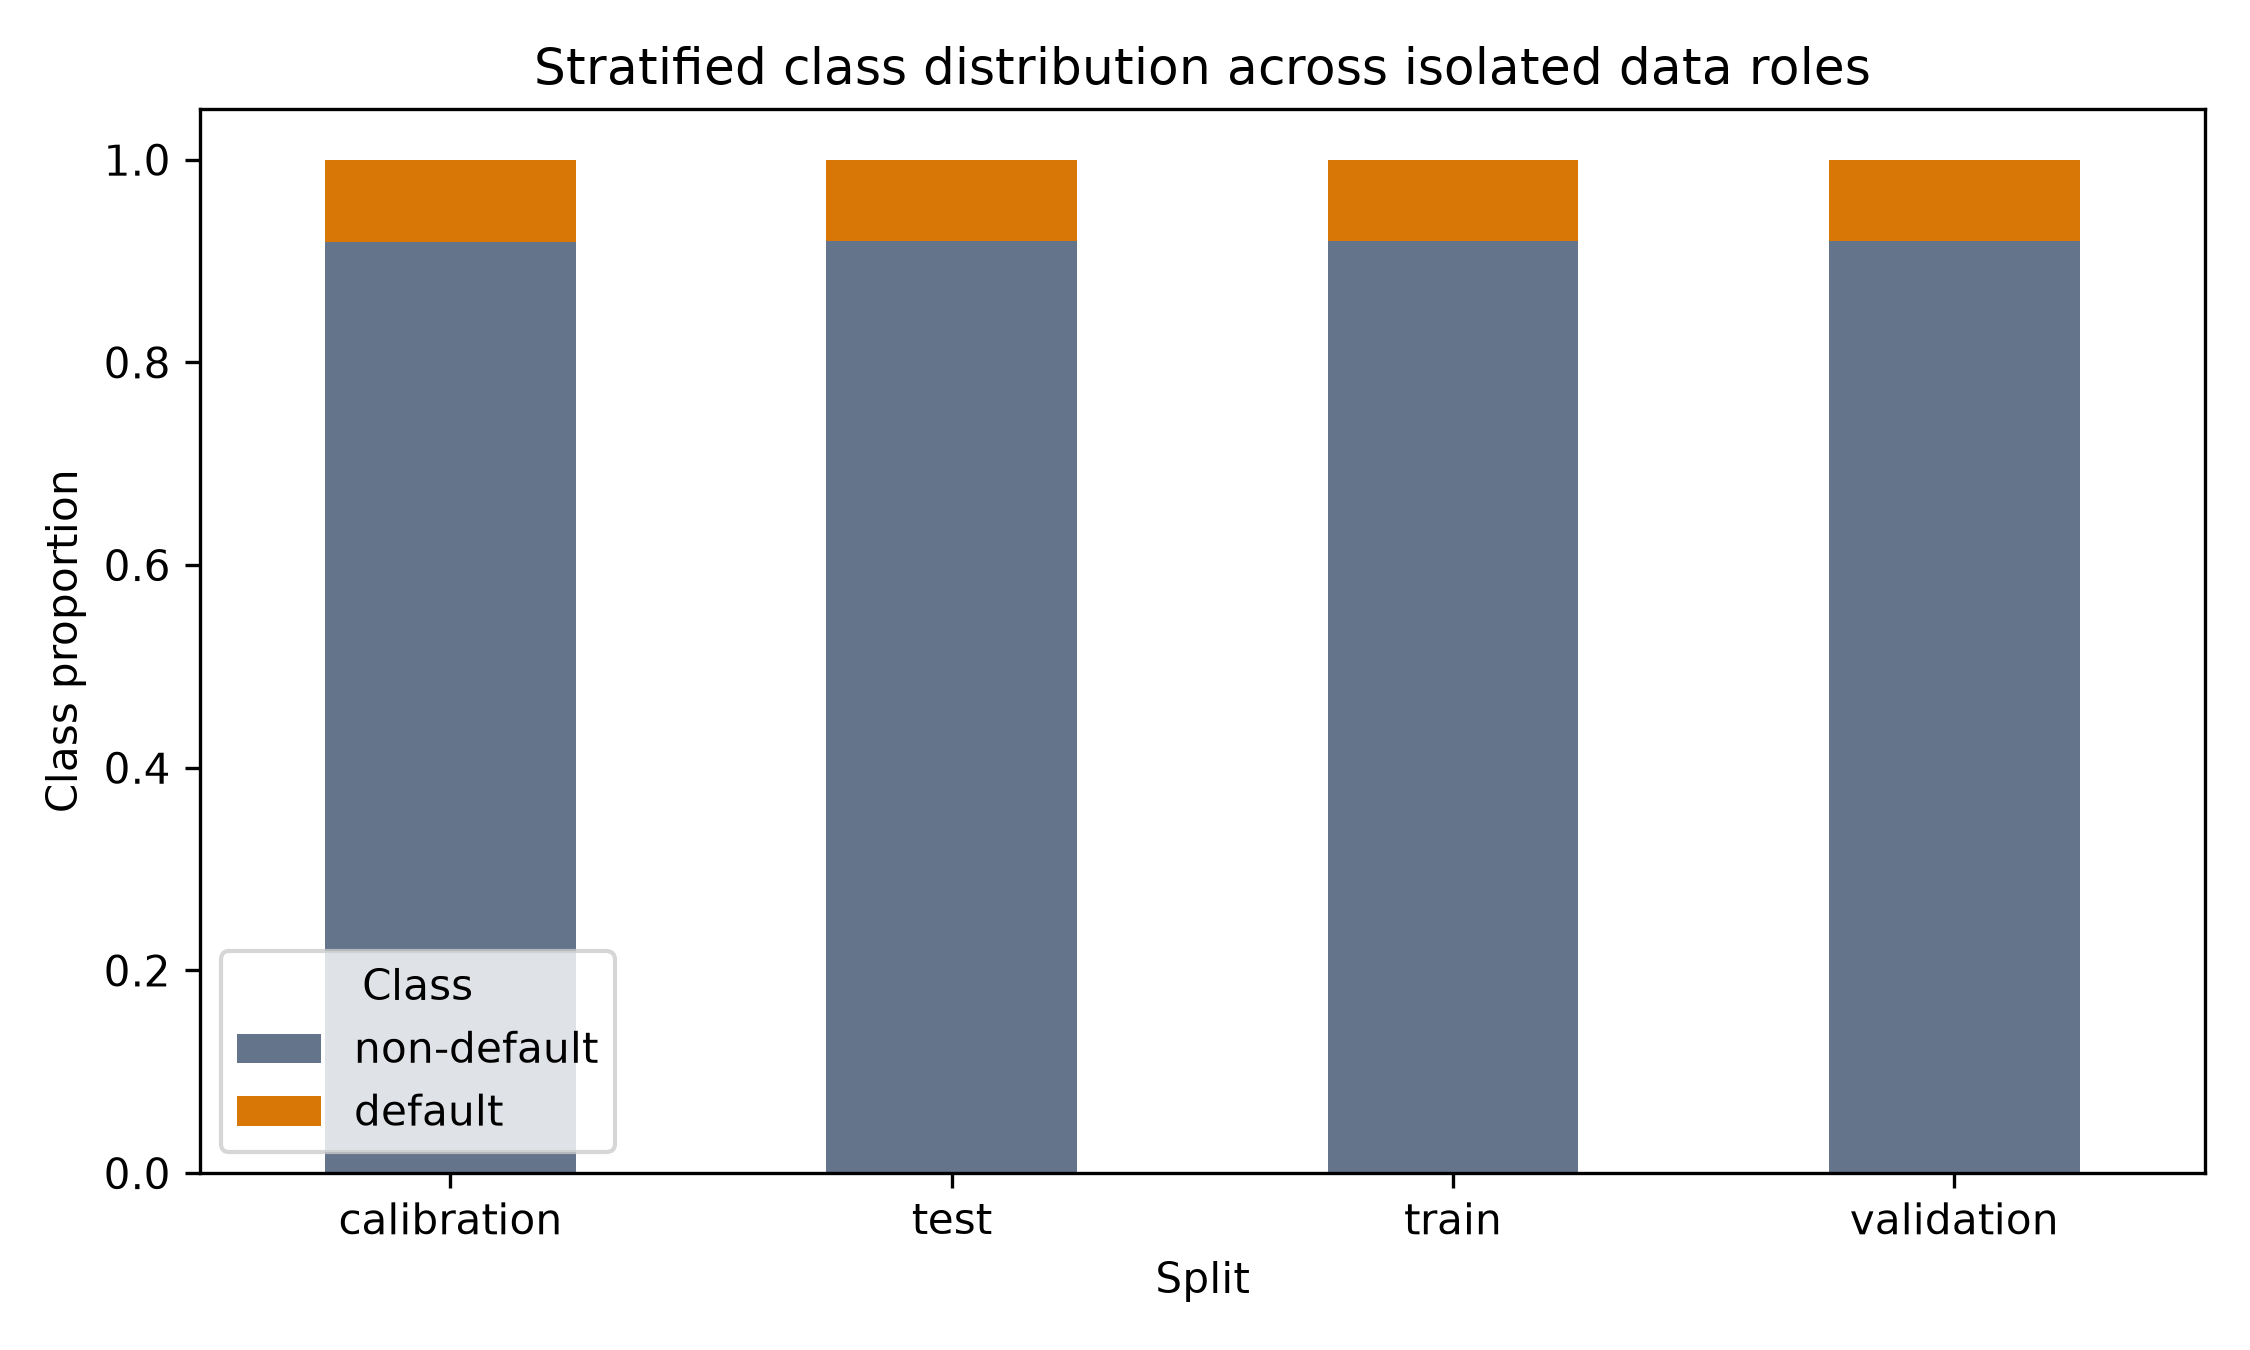

In [9]:
display(Image(filename=DIRS['figures'] / 'phase2_class_distribution.png'))

**Methodological interpretation.** Train ใช้ fit preprocessing/model, calibration ใช้ fit Platt, validation ใช้เลือก threshold และ final test ใช้รายงานผลเท่านั้น. ทุก pair ของ split มี ID overlap = 0 และ target alignment ผ่านทุก split.

## 3.2 Data Preprocessing

การตัดคอลัมน์ missing, median/mode imputation และ one-hot vocabulary เรียนรู้จาก train เท่านั้น. Validation/calibration/test ถูก transform ด้วย object เดิม. Sparse CSR float32 ลด memory โดยไม่ densify matrix.

In [10]:
def stage_preprocessing() -> None:
    marker = DIRS["cache"] / f"preprocessing_complete_{CFG.hash}.json"
    if marker.exists():
        log("Validated preprocessing checkpoint")
        return
    split = stage_splits()
    merged = _load_merged(split)
    merged = merged.merge(split[["SK_ID_CURR", "split"]], on="SK_ID_CURR",
                          validate="one_to_one", sort=False)
    frames = {name: merged.loc[merged["split"] == name].copy() for name in
              ["train", "validation", "calibration", "test"]}
    feature_cols = [c for c in merged if c not in ["SK_ID_CURR", "TARGET", "split"]]
    train_missing = frames["train"][feature_cols].isna().mean()
    feature_cols = [c for c in feature_cols if train_missing[c] <= CFG.missing_drop_threshold]
    categorical = [c for c in feature_cols if not pd.api.types.is_numeric_dtype(frames["train"][c])]
    numeric = [c for c in feature_cols if c not in categorical]
    preprocessor = ColumnTransformer([
        ("num", SimpleImputer(strategy="median", add_indicator=True), numeric),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True, dtype=np.float32)),
        ]), categorical),
    ], sparse_threshold=1.0)
    X_train = preprocessor.fit_transform(frames["train"][feature_cols]).tocsr().astype(np.float32)
    joblib.dump({"preprocessor": preprocessor, "feature_cols": feature_cols,
                 "schema_version": SCHEMA_VERSION, "config_hash": CFG.hash},
                DIRS["models"] / f"preprocessor_{CFG.hash}.joblib", compress=3)
    for name, frame in frames.items():
        X = X_train if name == "train" else preprocessor.transform(frame[feature_cols]).tocsr().astype(np.float32)
        sparse.save_npz(DIRS["cache"] / f"X_{name}_{CFG.hash}.npz", X, compressed=True)
        np.savez_compressed(DIRS["cache"] / f"meta_{name}_{CFG.hash}.npz",
                            ids=frame["SK_ID_CURR"].to_numpy(np.int64),
                            y=frame["TARGET"].to_numpy(np.int8))
        assert X.shape[0] == len(frame)
        del X
    save_json({"schema_version": SCHEMA_VERSION, "config_hash": CFG.hash,
               "n_features": int(X_train.shape[1]), "raw_features": len(feature_cols),
               "categorical": categorical, "numeric": numeric,
               "fit_scope": "train_only"}, marker)
    update_manifest("corrected_preprocessing", "complete",
                    [str(marker), "cache/X_{split}_{config}.npz", "models/preprocessor.joblib"],
                    "Applicant IDs and targets asserted before/after every merge; learned preprocessing fit on train only.")
    log(f"Preprocessing complete: train={X_train.shape}; sparse float32")
    del merged, frames, X_train, preprocessor
    gc.collect()

def load_matrix(name: str):
    X = sparse.load_npz(DIRS["cache"] / f"X_{name}_{CFG.hash}.npz")
    meta = np.load(DIRS["cache"] / f"meta_{name}_{CFG.hash}.npz")
    return X, meta["y"], meta["ids"]

In [11]:
preprocessing_scope = pd.read_csv(DIRS['results'] / 'preprocessing_audit.csv')
display(preprocessing_scope.head(40))

,stage,fit_scope,detail
0,identity,not learned,SK_ID_CURR retained; one-to-one merge and row ...
1,external aggregation,all rows by applicant ID,sum/count/min/max/mean; installments also PAYM...
2,missing-column filter,train only,drop when train missing rate > 80%
3,numeric imputation,train only,median + missing indicators
4,categorical imputation,train only,most frequent
5,categorical encoding,train only,one-hot; unknown categories ignored
6,output,train_only,CSR float32; 87 retained raw and 182 transform...


In [12]:
bundle = joblib.load(DIRS['models'] / f'preprocessor_{CFG.hash}.joblib')
marker = json.loads((DIRS['cache'] / f'preprocessing_complete_{CFG.hash}.json').read_text(encoding='utf-8'))
matrix_shapes = {}
for split_name in ['train','validation','calibration','test']:
    X, y, ids = load_matrix(split_name)
    matrix_shapes[split_name] = {'rows': X.shape[0], 'features': X.shape[1],
                                 'dtype': str(X.dtype), 'sparse': sparse.issparse(X)}
display(pd.DataFrame(matrix_shapes).T)
print(marker)

,rows,features,dtype,sparse
train,184505,182,float32,True
validation,46127,182,float32,True
calibration,30752,182,float32,True
test,46127,182,float32,True


{'schema_version': 'home-credit-sisa-final-v1', 'config_hash': '750d68aae1b6', 'n_features': 182, 'raw_features': 87, 'categorical': ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE'], 'numeric': ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'TOTALAREA_MODE', 'DAYS_LAST_PHONE_CHANGE', 'bureau__DAYS_CREDIT__sum', 'bureau__DAYS_CREDIT__count', 'bureau__AMT_CREDIT_SUM__sum', 'bureau__AMT_CREDIT_SUM__count', 'bureau__AMT_CREDIT_SUM_DEBT__sum', 'bureau__AMT_CREDIT_SUM_DEBT__count', 'bureau__DAYS_CREDIT__min', 'bureau__AMT_CREDIT_SUM__min', 'bureau__AMT_CREDIT_SUM_DEBT__min', 'bureau__DAYS_CREDIT__max', 'bureau__A

**Check.** Corrected representation มี 182 transformed features; preprocessing marker ระบุ `fit_scope='train_only'`. Identity ไม่ถูกใช้เป็น predictor แต่เก็บคู่กับ matrix ใน meta artifact เพื่อ audit และ deletion routing.

## 3.3 Baseline Model Development

Baseline ทั้งสี่เป็น reference utility ก่อน sharding. Hyperparameters ถูกตรึงล่วงหน้า; ไม่มี test-driven tuning. Probability calibration ใช้ calibration split และ threshold ที่ maximize F1 ใช้ validation split.

In [13]:
def make_model(name: str, seed: int):
    if name == "Logistic Regression":
        return Pipeline([
            ("scale", StandardScaler(with_mean=False)),
            ("model", LogisticRegression(max_iter=500, class_weight="balanced", C=0.2,
                                         random_state=seed, n_jobs=CFG.threads)),
        ])
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators=180, max_depth=12, min_samples_leaf=10,
                                      max_features="sqrt", class_weight="balanced_subsample",
                                      random_state=seed, n_jobs=CFG.threads)
    if name == "LightGBM":
        return LGBMClassifier(n_estimators=300, learning_rate=0.04, num_leaves=31,
                              subsample=0.85, colsample_bytree=0.85, reg_lambda=1.0,
                              class_weight="balanced", random_state=seed,
                              n_jobs=CFG.threads, verbosity=-1, deterministic=True,
                              force_col_wise=True)
    if name == "XGBoost":
        return XGBClassifier(n_estimators=300, learning_rate=0.04, max_depth=5,
                             min_child_weight=5, subsample=0.85, colsample_bytree=0.85,
                             reg_lambda=1.0, eval_metric="logloss", random_state=seed,
                             n_jobs=CFG.threads, tree_method="hist")
    raise ValueError(name)

def positive_probability(model, X) -> np.ndarray:
    return np.asarray(model.predict_proba(X)[:, 1], dtype=np.float64)

def fit_platt(raw_prob: np.ndarray, y: np.ndarray):
    logits = np.log(np.clip(raw_prob, 1e-6, 1 - 1e-6) / np.clip(1 - raw_prob, 1e-6, 1))[:, None]
    cal = LogisticRegression(C=1e6, max_iter=200, random_state=CFG.seed)
    cal.fit(logits, y)
    return cal

def calibrate(calibrator, raw_prob: np.ndarray) -> np.ndarray:
    logits = np.log(np.clip(raw_prob, 1e-6, 1 - 1e-6) / np.clip(1 - raw_prob, 1e-6, 1))[:, None]
    return calibrator.predict_proba(logits)[:, 1]

def choose_threshold(y: np.ndarray, p: np.ndarray) -> float:
    thresholds = np.linspace(0.02, 0.60, 117)
    f1 = [f1_score(y, p >= t) for t in thresholds]
    return float(thresholds[int(np.argmax(f1))])

def metrics(y: np.ndarray, p: np.ndarray, threshold: float) -> dict:
    pred = p >= threshold
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "roc_auc": roc_auc_score(y, p), "average_precision": average_precision_score(y, p),
        "log_loss": log_loss(y, p), "brier": brier_score_loss(y, p),
        "threshold": threshold, "f1": f1_score(y, pred),
        "sensitivity": tp / max(tp + fn, 1), "specificity": tn / max(tn + fp, 1),
    }

In [14]:
model_config = pd.read_csv(DIRS['results'] / 'baseline_model_config.csv')
display(model_config.head(40))

,model,configuration,role
0,Logistic Regression,StandardScaler(with_mean=False); C=0.2; class_...,linear baseline
1,Random Forest,n_estimators=180; max_depth=12; min_samples_le...,bagged tree baseline
2,LightGBM,n_estimators=300; learning_rate=0.04; num_leav...,gradient-boosted tree baseline and main S sweep
3,XGBoost,n_estimators=300; learning_rate=0.04; max_dept...,gradient-boosted tree baseline


### 3.3.1 Logistic Regression

ใช้เป็น linear, interpretable reference. `class_weight='balanced'`, C=0.2, sparse-compatible scaling; Platt calibration ใช้ calibration split และ threshold เลือกจาก validation เท่านั้น.

In [15]:
lr_result = pd.read_csv(DIRS['results'] / 'baseline_performance_complete.csv').query("model == 'Logistic Regression'")
display(lr_result[['model', 'roc_auc', 'average_precision', 'ks', 'brier', 'threshold', 'f1', 'sensitivity', 'specificity', 'fit_seconds']])

,model,roc_auc,average_precision,ks,brier,threshold,f1,sensitivity,specificity,fit_seconds
0,Logistic Regression,0.754891,0.234573,0.382488,0.068128,0.145,0.304623,0.438776,0.873358,22.278107


### 3.3.2 Random Forest

ใช้เป็น bagged non-linear tree reference. ใช้ 180 trees, depth 12, minimum leaf 10 และ `balanced_subsample`; ใช้ calibration/validation protocol เดียวกัน.

In [16]:
rf_result = pd.read_csv(DIRS['results'] / 'baseline_performance_complete.csv').query("model == 'Random Forest'")
display(rf_result[['model', 'roc_auc', 'average_precision', 'ks', 'brier', 'threshold', 'f1', 'sensitivity', 'specificity', 'fit_seconds']])

,model,roc_auc,average_precision,ks,brier,threshold,f1,sensitivity,specificity,fit_seconds
1,Random Forest,0.74723,0.223192,0.373641,0.06868,0.135,0.28942,0.455424,0.851426,354.538574


### 3.3.3 LightGBM

ใช้เป็น efficient gradient-boosting family และเป็น model หลักสำหรับ shard-count/strategy studies. ใช้ balanced classes, deterministic mode และ fixed 300 boosting rounds.

In [17]:
lgb_result = pd.read_csv(DIRS['results'] / 'baseline_performance_complete.csv').query("model == 'LightGBM'")
display(lgb_result[['model', 'roc_auc', 'average_precision', 'ks', 'brier', 'threshold', 'f1', 'sensitivity', 'specificity', 'fit_seconds']])

,model,roc_auc,average_precision,ks,brier,threshold,f1,sensitivity,specificity,fit_seconds
2,LightGBM,0.768972,0.259649,0.408259,0.067085,0.17,0.314259,0.412191,0.89364,9.350336


### 3.3.4 XGBoost

ใช้ตรวจ robustness กับ boosting implementation อีก family. ใช้ histogram tree method, fixed depth/rate/subsampling และ protocol calibration/threshold เดียวกัน.

In [18]:
xgb_result = pd.read_csv(DIRS['results'] / 'baseline_performance_complete.csv').query("model == 'XGBoost'")
display(xgb_result[['model', 'roc_auc', 'average_precision', 'ks', 'brier', 'threshold', 'f1', 'sensitivity', 'specificity', 'fit_seconds']])

,model,roc_auc,average_precision,ks,brier,threshold,f1,sensitivity,specificity,fit_seconds
3,XGBoost,0.768174,0.26138,0.408869,0.066991,0.18,0.316378,0.372449,0.913756,11.829097


### Consolidated baseline execution

In [19]:
def stage_baselines() -> None:
    stage_preprocessing()
    Xtr, ytr, _ = load_matrix("train")
    Xv, yv, idv = load_matrix("validation")
    Xc, yc, idc = load_matrix("calibration")
    Xt, yt, idt = load_matrix("test")
    rows = []
    for i, name in enumerate(["Logistic Regression", "Random Forest", "LightGBM", "XGBoost"]):
        artifact = DIRS["models"] / f"baseline_{name.lower().replace(' ', '_')}_{CFG.hash}.joblib"
        pred_path = DIRS["results"] / f"predictions_{name.lower().replace(' ', '_')}_{CFG.hash}.csv.gz"
        if artifact.exists() and pred_path.exists():
            bundle = joblib.load(artifact)
            pred = pd.read_csv(pred_path)
            rows.append({"model": name, "fit_seconds": bundle["fit_seconds"],
                         **metrics(pred.loc[pred.split == "test", "y"].to_numpy(),
                                   pred.loc[pred.split == "test", "probability"].to_numpy(),
                                   bundle["threshold"])})
            log(f"Reused validated baseline checkpoint: {name}")
            continue
        started = time.perf_counter()
        model = make_model(name, CFG.seed + i)
        model.fit(Xtr, ytr)
        fit_seconds = time.perf_counter() - started
        cal = fit_platt(positive_probability(model, Xc), yc)
        pv = calibrate(cal, positive_probability(model, Xv))
        threshold = choose_threshold(yv, pv)
        pt = calibrate(cal, positive_probability(model, Xt))
        bundle = {"model": model, "calibrator": cal, "threshold": threshold,
                  "fit_seconds": fit_seconds, "schema_version": SCHEMA_VERSION,
                  "config_hash": CFG.hash}
        joblib.dump(bundle, artifact, compress=3)
        pred = pd.concat([
            pd.DataFrame({"SK_ID_CURR": idv, "split": "validation", "y": yv, "probability": pv}),
            pd.DataFrame({"SK_ID_CURR": idt, "split": "test", "y": yt, "probability": pt}),
        ], ignore_index=True)
        pred.to_csv(pred_path, index=False, compression="gzip")
        rows.append({"model": name, "fit_seconds": fit_seconds, **metrics(yt, pt, threshold)})
        atomic_csv(pd.DataFrame(rows), DIRS["results"] / "baseline_performance.csv")
        log(f"Baseline complete: {name}; test AUC={rows[-1]['roc_auc']:.4f}; {fit_seconds:.1f}s")
        del model, cal, pred, bundle
        gc.collect()
    atomic_csv(pd.DataFrame(rows), DIRS["results"] / "baseline_performance.csv")
    update_manifest("baseline_models", "complete",
                    ["results/baseline_performance.csv", "results/predictions_*.csv.gz", "models/baseline_*.joblib"],
                    "Calibration fitted on calibration split; threshold selected on validation; test used once for reporting.")
    del Xtr, Xv, Xc, Xt
    gc.collect()

**Design note.** `stage_baselines()` เขียน model bundle, calibrator, threshold และ per-applicant validation/test probabilities ทำให้ผลสรุปตรวจย้อนกลับได้.

## 3.4 SISA Sharding Strategies

### Core SISA architecture walkthrough

SISA ในงานนี้ประกอบด้วย (1) deterministic assignment ของ train records เข้า S shards, (2) model instance แยกต่อ shard, (3) probability aggregation, (4) calibration/threshold ที่ตรึง, และ (5) deletion router ที่ระบุ affected shard. เมื่อมีคำขอลบ Exact SISA ภายใต้ fixed protocol จะ retrain เฉพาะ affected shard; protocol-compatible Gold retrain ทุก shard หลังลบด้วย seed/configuration เดียวกัน.

### Core deterministic assignment

In [20]:
def stratified_assignment(y, ids, n_shards, seed=CFG.seed):
    rng = np.random.default_rng(seed)
    shard = np.empty(len(y), dtype=np.int16)
    for label in np.unique(y):
        rows = np.flatnonzero(y == label)
        rng.shuffle(rows)
        shard[rows] = np.arange(len(rows)) % n_shards
    return pd.DataFrame({"row_index": np.arange(len(y)), "SK_ID_CURR": ids,
                         "TARGET": y, "shard": shard})

def get_stratified_assignment(y, ids, n_shards):
    if n_shards == CFG.shards:
        existing = DIRS["shards"] / f"stratified_S{CFG.shards}_{CFG.hash}.csv"
        if existing.exists():
            return pd.read_csv(existing)
    path = _assignment_path("stratified", n_shards)
    if path.exists():
        return pd.read_csv(path)
    assignment = stratified_assignment(y, ids, n_shards)
    atomic_csv(assignment, path)
    return assignment

### One model per shard and retained-size aggregation

In [21]:
def _fit_or_load_shards(model_name, n_shards, assignment, strategy="stratified"):
    Xtr, ytr, _ = load_matrix("train")
    models, sizes, fit_times = [], [], []
    for shard in range(n_shards):
        rows = assignment.loc[assignment.shard == shard, "row_index"].to_numpy()
        path = _model_path(model_name, n_shards, shard, strategy)
        if path.exists():
            bundle = joblib.load(path); model = bundle["model"]
            fit_seconds = float(bundle.get("fit_seconds", 0.0))
        else:
            started = time.perf_counter()
            model = make_model(model_name, CFG.seed + 100 + shard)
            model.fit(Xtr[rows], ytr[rows])
            fit_seconds = time.perf_counter() - started
            joblib.dump({"model": model, "rows": len(rows), "fit_seconds": fit_seconds,
                         "schema_version": SCHEMA_VERSION, "config_hash": CFG.hash,
                         "strategy": strategy, "shards": n_shards}, path, compress=3)
            log(f"Phase 2 {model_name} {strategy} S={n_shards}: shard {shard + 1}/{n_shards}")
        models.append(model); sizes.append(len(rows)); fit_times.append(fit_seconds)
    del Xtr
    return models, np.asarray(sizes), np.asarray(fit_times)

def _raw_ensemble(models, X, weights):
    result = np.zeros(X.shape[0], dtype=np.float64)
    for model, weight in zip(models, weights):
        result += positive_probability(model, X) * weight
    return result

def _evaluate_ensemble(models, sizes):
    Xc, yc, _ = load_matrix("calibration")
    Xv, yv, _ = load_matrix("validation")
    Xt, yt, idt = load_matrix("test")
    weights = sizes / sizes.sum()
    cal = fit_platt(_raw_ensemble(models, Xc, weights), yc)
    pv = calibrate(cal, _raw_ensemble(models, Xv, weights))
    threshold = choose_threshold(yv, pv)
    pt = calibrate(cal, _raw_ensemble(models, Xt, weights))
    result = metrics(yt, pt, threshold)
    result["ks"] = ks_statistic(yt, pt)
    del Xc, Xv, Xt
    return result, pt, idt, yt, cal, threshold

**Established SISA concept vs project choice.** การแยกข้อมูลเป็น isolated shards และ retrain เฉพาะ shard ที่ได้รับผลเป็นแกน SISA. ส่วน S=4, class-stratified assignment, retained-size weighted probability, Platt calibration และ model hyperparameters เป็น operational choices ของโครงการนี้.

### Four primary statistical/data-driven sharding designs

เปรียบเทียบห้า assignment designs ภายใต้ controlled layer ที่เปลี่ยนเฉพาะ assignment และตรึง LightGBM S=4 + weighted aggregation. Practical layer อนุญาต learned aggregation แยกต่างหาก. ตาราง classification หลีกเลี่ยงการอ้างว่าแนวคิดใดมาจากงานตีพิมพ์เมื่อ project artifacts ไม่มี citation ที่ตรวจสอบแล้ว.

In [22]:
strategy_design = pd.read_csv(DIRS['results'] / 'sharding_contribution_thesis.csv')
display(strategy_design.head(40))

,Strategy,Role in study,Design principle,Actual assignment basis,Expected shard structure,Matched deletion pattern,Aggregation approach,Primary hypothesis,Observed utility effect,Observed locality/workload effect,Main limitation
0,Stratified,primary standard baseline,balance size and target rate,class-wise shuffled round robin,similar size and class prior,control for feature/risk locality,retained-size weighted + Platt,stable utility and predictable 1/S single-dele...,controlled ROC-AUC=0.765968,0.1% feature-localized workload=1.000; risk-lo...,does not intentionally localize feature/risk c...
1,Representative,primary project implementation/adaptation,spread every feature cluster across shards,train-only SVD8 + MiniBatchKMeans + cluster-wi...,population-like mixture per shard,none pre-specified,retained-size weighted + Platt,preserve utility through representation,controlled ROC-AUC=0.766435,no dedicated matched-locality advantage claimed,depends on embedding/clustering and does not t...
2,Specialist,primary project-specific experimental design,concentrate feature-similar applicants,train-only feature-cluster ordering split into...,feature-specialized shards,feature-localized,weighted controlled; learned practical layer a...,reduce affected shards for feature-localized r...,controlled ROC-AUC=0.765861,0.1% matched workload=0.625,structure depends on feature representation; d...
3,Risk-Band,primary project-specific experimental design,concentrate similar OOF risk,3-fold train-only OOF LightGBM risk quantile b...,different risk/class priors by shard,risk-localized,weighted controlled; learned practical layer a...,reduce affected shards for risk-localized requ...,controlled ROC-AUC=0.695504; learned aggregati...,0.1% matched workload=0.250,naive averaging fails under heterogeneous shar...
4,Random-balanced,optional control,balance size without explicit class/feature/ri...,global seeded shuffle and equal split,balanced random shards,none/control,retained-size weighted + Platt,separate balancing from stratification,controlled ROC-AUC=0.766113,locality is incidental rather than designed,no deliberate alignment with deletion requests


### Actual assignment implementation

In [23]:
def _embedding():
    path = DIRS["cache"] / f"phase2_train_svd8_{CFG.hash}.npy"
    if path.exists():
        return np.load(path)
    Xtr, _, _ = load_matrix("train")
    emb = TruncatedSVD(n_components=8, random_state=CFG.seed).fit_transform(Xtr).astype(np.float32)
    np.save(path, emb)
    return emb

def _oof_risk():
    path = DIRS["cache"] / f"phase2_oof_lightgbm_3fold_{CFG.hash}.npy"
    if path.exists():
        return np.load(path)
    Xtr, ytr, _ = load_matrix("train")
    oof = np.zeros(len(ytr), dtype=np.float32)
    cv = StratifiedKFold(3, shuffle=True, random_state=CFG.seed)
    for fold, (fit_rows, hold_rows) in enumerate(cv.split(Xtr, ytr)):
        model = make_model("LightGBM", CFG.seed + 300 + fold)
        model.fit(Xtr[fit_rows], ytr[fit_rows])
        oof[hold_rows] = positive_probability(model, Xtr[hold_rows])
        log(f"OOF risk fold {fold + 1}/3 checkpointed in memory")
    np.save(path, oof)
    return oof

def _strategy_assignments():
    _, ytr, idtr = load_matrix("train")
    n, s = len(ytr), CFG.shards
    outputs = {"stratified_balanced": get_stratified_assignment(ytr, idtr, s)}
    random_path = DIRS["shards"] / f"random_balanced_S{s}_{CFG.hash}.csv"
    outputs["random_balanced"] = pd.read_csv(random_path)
    emb = _embedding()
    label_path = DIRS["cache"] / f"phase2_feature_clusters_S{s}_{CFG.hash}.npy"
    if label_path.exists():
        labels = np.load(label_path)
    else:
        labels = MiniBatchKMeans(n_clusters=s, random_state=CFG.seed, batch_size=4096,
                                 n_init=5).fit_predict(emb)
        np.save(label_path, labels)
    rng = np.random.default_rng(CFG.seed)
    rep_shard = np.empty(n, dtype=np.int16)
    offset = 0
    for cluster in range(s):
        rows = np.flatnonzero(labels == cluster); rng.shuffle(rows)
        rep_shard[rows] = (np.arange(len(rows)) + offset) % s
        offset = (offset + len(rows)) % s
    order = np.argsort(labels, kind="stable")
    spec_shard = np.empty(n, dtype=np.int16)
    for shard, rows in enumerate(np.array_split(order, s)):
        spec_shard[rows] = shard
    risk = _oof_risk(); risk_order = np.argsort(risk, kind="stable")
    risk_shard = np.empty(n, dtype=np.int16)
    for shard, rows in enumerate(np.array_split(risk_order, s)):
        risk_shard[rows] = shard
    for name, values in [("representative", rep_shard), ("specialist", spec_shard), ("risk_band", risk_shard)]:
        path = _assignment_path(name, s)
        if path.exists():
            outputs[name] = pd.read_csv(path)
        else:
            frame = pd.DataFrame({"row_index": np.arange(n), "SK_ID_CURR": idtr,
                                  "TARGET": ytr, "shard": values})
            atomic_csv(frame, path); outputs[name] = frame
    return outputs, labels, risk

### 3.4.1 Stratified Sharding

**Motivation/role:** standard experimental baseline ที่รักษาขนาดและ target rate ต่อ shard. **Mechanism:** class-wise shuffled round robin. **Hypothesis:** utility คงที่และ single-delete workload ใกล้ 1/S. **Matched scenario:** control สำหรับทุก deletion pattern. **Observed result:** AUC≈0.766 และ distributed requests กระทบทุก shard เมื่อ request โตขึ้น. **Limitation:** ไม่สร้าง feature/risk locality โดยตั้งใจ.

### 3.4.2 Representative Sharding

**Status:** project implementation/adaptation; ไม่อ้าง literature origin ที่ยังไม่ได้ตรวจ. **Mechanism:** train-only SVD8 + MiniBatchKMeans แล้วกระจายสมาชิกแต่ละ cluster ไปทุก shard. **Hypothesis:** แต่ละ shard เป็นตัวแทน population และคง utility. **Observed result:** controlled utility ใกล้/สูงกว่า stratified เล็กน้อย. **Limitation:** ไม่ได้ตั้งใจลด matched localized deletion workload.

### 3.4.3 Specialist Sharding

**Status:** experimental sharding strategy evaluated in this study. **Mechanism:** feature-cluster order ถูกแบ่งเป็น equal contiguous shards เพื่อเพิ่ม specialization. **Hypothesis:** feature-localized requests กระทบ shards น้อยลง. **Observed result:** utility ใกล้ stratified และ paired feature-localized workload ลดลง. **Limitation:** structure ขึ้นกับ embedding/clustering และ practical deployment อาจต้อง aggregation ที่เหมาะ.

### 3.4.4 Risk-Band Sharding

**Status:** experimental sharding strategy evaluated in this study. **Mechanism:** 3-fold train-only OOF LightGBM risk เรียงเป็น equal bands. **Hypothesis:** risk-localized requests มี locality สูง. **Observed result:** matched workload ลดมาก แต่ simple averaging ทำให้ utility ลดเพราะ shard priors ต่างกัน. **Limitation:** learned aggregation กู้ utility ได้บางส่วนแต่ไม่ทั้งหมด.

**Random-balanced control:** global shuffled balanced assignment ใช้แยกผลของ balancing ออกจาก explicit stratification; ไม่ใช่ primary strategy ที่ห้า.

### Shard diagnostics required before outcome comparison

In [24]:
shard_diagnostics = pd.read_csv(DIRS['results'] / 'shard_diagnostics.csv')
display(shard_diagnostics.head(25))

,strategy,shard,records,size_share,default_rate,oof_risk_mean,oof_risk_sd,svd_component_1_mean,svd_component_1_sd,dominant_feature_cluster,dominant_cluster_share
0,stratified_balanced,0,46127,0.250004,0.080734,0.376793,0.211639,5292505.5,4356631.0,1,0.801830
1,stratified_balanced,1,46127,0.250004,0.080734,0.377264,0.212056,5292570.0,3511793.0,1,0.799705
2,stratified_balanced,2,46126,0.249999,0.080714,0.376903,0.211185,5287449.5,4089978.2,1,0.803018
3,stratified_balanced,3,46125,0.249993,0.080715,0.377637,0.212576,5279770.0,3583600.2,1,0.803837
4,random_balanced,0,46127,0.250004,0.081189,0.377126,0.212126,5288736.0,4104331.5,1,0.802697
5,random_balanced,1,46126,0.249999,0.080735,0.377336,0.212332,5300818.5,3623200.8,1,0.800958
6,random_balanced,2,46126,0.249999,0.081516,0.376725,0.212223,5280446.0,4341021.0,1,0.802931
7,random_balanced,3,46126,0.249999,0.079456,0.377411,0.210775,5282295.0,3473520.0,1,0.801804
8,representative,0,46127,0.250004,0.079910,0.377828,0.210926,5292560.5,3795211.8,1,0.802090
9,representative,1,46126,0.249999,0.081516,0.377329,0.211911,5282669.5,4244922.0,1,0.802107


In [25]:
diagnostic_summary = shard_diagnostics.groupby('strategy').agg(
    size_cv=('records', lambda x: x.std()/x.mean()),
    default_rate_sd=('default_rate','std'),
    risk_mean_range=('oof_risk_mean', lambda x: x.max()-x.min()),
    dominant_cluster_share_mean=('dominant_cluster_share','mean'))
display(diagnostic_summary)

,size_cv,default_rate_sd,risk_mean_range,dominant_cluster_share_mean
strategy,,,,
random_balanced,0.000011,0.000904,0.000686,0.802098
representative,0.000011,0.001159,0.001774,0.802098
risk_band,0.000011,0.081026,0.543407,0.802098
specialist,0.000011,0.003925,0.020083,0.802098
stratified_balanced,0.000021,0.000011,0.000845,0.802098


**Diagnostic meaning.** Strategy ไม่ถูกนิยามจากชื่ออย่างเดียว: size/class/risk/SVD/cluster diagnostics แสดง structure ที่ assignment สร้างจริง. โดยเฉพาะ risk-band มี class/risk heterogeneity สูง จึงไม่ควรคาดว่า simple averaging จะเหมาะโดยอัตโนมัติ.

### Shard-Count Scalability / Sensitivity Analysis

ใช้ LightGBM family เดียวและตรึง preprocessing, stratified assignment rule, hyperparameters, calibration/validation/test protocol. Reuse S=2/4/8/16 และคำนวณเพิ่มเฉพาะ S=32/64/128. การทดลองนี้อธิบาย sensitivity เท่านั้นและไม่ใช้ final test เพื่อเลือก “optimal S”. Assignment-localized 0.1% เป็น ideal one-shard request; distributed 0.1% ใช้ fixed request rows เดียวกันข้ามทุก S.

In [26]:
def _workload_metrics(assignment: pd.DataFrame, deleted_rows: np.ndarray) -> dict:
    deleted_rows = np.unique(np.asarray(deleted_rows, dtype=int))
    affected = np.sort(assignment.loc[assignment.row_index.isin(deleted_rows), "shard"].unique())
    shard_sizes = assignment.groupby("shard").size()
    affected_original_rows = int(shard_sizes.loc[affected].sum())
    n_original = len(assignment)
    n_deleted = len(deleted_rows)
    actual_retrained_rows = affected_original_rows - n_deleted
    return {
        "deleted_records": n_deleted,
        "affected_shards": len(affected),
        "affected_shard_fraction": len(affected) / assignment.shard.nunique(),
        "affected_data_fraction": affected_original_rows / n_original,
        "actual_retrained_fraction": actual_retrained_rows / (n_original - n_deleted),
    }

def stage_extended_shard_count() -> None:
    """Extend the corrected LightGBM sensitivity study through S=128."""
    _, ytr, idtr = load_matrix("train")
    existing = pd.read_csv(DIRS["results"] / "shard_count_performance.csv").set_index("shards")
    rng = np.random.default_rng(CFG.seed + 3200)
    distributed_rows = np.sort(rng.choice(np.arange(len(idtr)),
                                          max(1, round(len(idtr) * .001)), replace=False))
    request_rows = [{"request": "distributed_0.1%", "shards": "all",
                     "row_index": int(row), "SK_ID_CURR": int(idtr[row])}
                    for row in distributed_rows]
    completed = []

    for n_shards in EXTENDED_S_VALUES:
        checkpoint = DIRS["results"] / f"shard_count_scalability_S{n_shards}.csv"
        if checkpoint.exists():
            completed.append(pd.read_csv(checkpoint).iloc[0].to_dict())
            continue

        assignment = get_stratified_assignment(ytr, idtr, n_shards)
        models, sizes, fit_times = _fit_or_load_shards(
            "LightGBM", n_shards, assignment, strategy="stratified")
        evaluated, timing = _timed_evaluation(models, sizes)

        # Reuse authoritative validated utility for S<=16; assert fresh evaluation compatibility.
        if n_shards in existing.index:
            prior = existing.loc[n_shards]
            assert abs(evaluated["roc_auc"] - prior.roc_auc) < 1e-12
            assert abs(evaluated["average_precision"] - prior.average_precision) < 1e-12
            assert abs(evaluated["brier"] - prior.brier) < 1e-12
            utility = {"roc_auc": prior.roc_auc, "average_precision": prior.average_precision,
                       "ks": prior.ks, "brier": prior.brier}
        else:
            utility = {name: evaluated[name] for name in ["roc_auc", "average_precision", "ks", "brier"]}

        anchor_row = 0
        anchor_shard = int(assignment.loc[assignment.row_index.eq(anchor_row), "shard"].iloc[0])
        anchor_pool = assignment.loc[assignment.shard.eq(anchor_shard), "row_index"].to_numpy(dtype=int)
        localized_rows = np.sort(anchor_pool[:max(1, round(len(idtr) * .001))])
        single = _workload_metrics(assignment, np.asarray([anchor_row]))
        localized = _workload_metrics(assignment, localized_rows)
        distributed = _workload_metrics(assignment, distributed_rows)
        request_rows.extend({"request": "assignment_localized_0.1%", "shards": n_shards,
                             "row_index": int(row), "SK_ID_CURR": int(idtr[row])}
                            for row in localized_rows)

        row = {
            "shards": n_shards, "mean_rows_per_shard": sizes.mean(),
            "min_rows_per_shard": sizes.min(), "max_rows_per_shard": sizes.max(),
            **utility, "sisa_training_seconds": fit_times.sum(),
            **timing,
            "single_record_affected_shard_fraction": single["affected_shard_fraction"],
            "single_record_affected_data_fraction": single["affected_data_fraction"],
            "single_record_actual_retrained_fraction": single["actual_retrained_fraction"],
            "localized_deleted_records": localized["deleted_records"],
            "localized_affected_shards": localized["affected_shards"],
            "localized_affected_data_fraction": localized["affected_data_fraction"],
            "localized_actual_retrained_fraction": localized["actual_retrained_fraction"],
            "distributed_deleted_records": distributed["deleted_records"],
            "distributed_affected_shards": distributed["affected_shards"],
            "distributed_affected_data_fraction": distributed["affected_data_fraction"],
            "distributed_actual_retrained_fraction": distributed["actual_retrained_fraction"],
            "utility_selection_role": "sensitivity analysis only; no test-based optimal-S selection",
        }
        atomic_csv(pd.DataFrame([row]), checkpoint)
        completed.append(row)
        log(f"Checkpointed LightGBM shard-count scalability S={n_shards}: AUC={row['roc_auc']:.4f}")
        del models
        gc.collect()

    result = pd.DataFrame(completed).sort_values("shards").reset_index(drop=True)
    assert result.shards.tolist() == EXTENDED_S_VALUES
    atomic_csv(result, DIRS["results"] / "shard_count_scalability_extended.csv")
    pd.DataFrame(request_rows).to_csv(DIRS["results"] / "shard_count_scalability_requests.csv.gz",
                                      index=False, compression="gzip")
    _scalability_figures(result)
    update_manifest("shard_count_scalability_extended", "complete", [
        "results/shard_count_scalability_extended.csv",
        "results/shard_count_scalability_S32.csv",
        "results/shard_count_scalability_S64.csv",
        "results/shard_count_scalability_S128.csv",
        "figures/shard_count_vs_predictive_utility.png",
        "figures/shard_count_vs_deletion_workload.png"],
        "LightGBM-only sensitivity S=2..128; S<=16 reused; S=32/64/128 newly computed; no optimal-S selection.")

## 3.5 Model Aggregation

### 3.5.1 Simple Averaging

Controlled comparison ใช้ retained-size weighted mean แล้ว fit Platt บน calibration. กฎเดียวกันนี้ทำให้เปรียบเทียบ assignment ได้โดยไม่เปลี่ยน aggregation พร้อมกัน.

### 3.5.2 Learned Aggregator

Specialist/risk-band practical architecture ใช้ shard probabilities เป็น meta-features: ครึ่งแรกของ calibration fit logistic meta-model และอีกครึ่ง fit Platt เพื่อไม่ calibrate บน meta-training rows เดียวกัน.

In [27]:
def _evaluate_strategy(strategy, assignment, practical=False):
    models, sizes, fit_times = _fit_or_load_shards("LightGBM", CFG.shards, assignment, strategy)
    Xc, yc, _ = load_matrix("calibration"); Xv, yv, _ = load_matrix("validation")
    Xt, yt, _ = load_matrix("test")
    pc = np.stack([positive_probability(m, Xc) for m in models], axis=1)
    pv_raw = np.stack([positive_probability(m, Xv) for m in models], axis=1)
    pt_raw = np.stack([positive_probability(m, Xt) for m in models], axis=1)
    if practical:
        meta = LogisticRegression(C=0.2, class_weight="balanced", max_iter=500, random_state=CFG.seed)
        meta_fit, meta_cal = train_test_split(np.arange(len(yc)), test_size=.5,
                                             stratify=yc, random_state=CFG.seed)
        meta.fit(pc[meta_fit], yc[meta_fit])
        second_cal = fit_platt(meta.predict_proba(pc[meta_cal])[:, 1], yc[meta_cal])
        pv = calibrate(second_cal, meta.predict_proba(pv_raw)[:, 1])
        pt = calibrate(second_cal, meta.predict_proba(pt_raw)[:, 1])
        aggregation = "learned logistic meta-aggregator + held-out Platt calibration"
    else:
        weights = sizes / sizes.sum(); cal = fit_platt(pc @ weights, yc)
        pv = calibrate(cal, pv_raw @ weights); pt = calibrate(cal, pt_raw @ weights)
        aggregation = "retained-size weighted probability + Platt calibration"
    threshold = choose_threshold(yv, pv); met = metrics(yt, pt, threshold); met["ks"] = ks_statistic(yt, pt)
    del Xc, Xv, Xt, models
    return met, sizes, fit_times, aggregation

In [28]:
aggregation_coefficients = pd.read_csv(DIRS['results'] / 'aggregation_coefficients.csv')
display(aggregation_coefficients.head(40))

,strategy,component,coefficient,meta_intercept,meta_fit_rows,platt_fit_rows,platt_slope,platt_intercept
0,specialist,shard_0,0.712714,-2.123221,15376,15376,0.936060,-2.430182
1,specialist,shard_1,0.952108,-2.123221,15376,15376,0.936060,-2.430182
2,specialist,shard_2,1.595204,-2.123221,15376,15376,0.936060,-2.430182
3,specialist,shard_3,1.809833,-2.123221,15376,15376,0.936060,-2.430182
4,risk_band,shard_0,0.087936,-3.141470,15376,15376,0.998697,-2.430997
5,risk_band,shard_1,0.496204,-3.141470,15376,15376,0.998697,-2.430997
6,risk_band,shard_2,2.134534,-3.141470,15376,15376,0.998697,-2.430997
7,risk_band,shard_3,5.983088,-3.141470,15376,15376,0.998697,-2.430997


**Separation of claims.** ผล controlled ตอบว่า assignment อย่างเดียวเปลี่ยนอะไร; ผล practical ตอบว่า architecture ที่ยอมให้ aggregation เรียนรู้สามารถกู้ utility ได้เพียงใด. ห้ามนำสอง layer มาปะปนเป็น comparison เดียว.

## 3.6 Deletion Locality Experimental Design

ขนาดคำขอคือ single, 0.01%, 0.1%, 1% ของ train. Pattern มี distributed random, feature-localized และ risk-localized. Request cohort เดียวกันถูกประเมินข้าม strategy ใน repetition เดียวกันเพื่อสร้าง paired design.

In [29]:
def stage_deletion_scale_locality():
    checkpoint = DIRS["results"] / "deletion_scale_locality.csv"
    if checkpoint.exists() and len(pd.read_csv(checkpoint)) > 0:
        log("Validated deletion-scale/locality checkpoint")
        return
    stage_expanded_sharding()
    _, ytr, idtr = load_matrix("train")
    assignments, feature_labels, risk = _strategy_assignments()
    sizes_to_test = [("single", 1), ("0.01%", max(1, round(len(idtr)*.0001))),
                     ("0.1%", max(1, round(len(idtr)*.001))), ("1%", max(1, round(len(idtr)*.01)))]
    request_rows, result_rows = [], []
    for rep in range(10):
        rng = np.random.default_rng(CFG.seed + 1000 + rep)
        for size_label, n_delete in sizes_to_test:
            random_ids = rng.choice(idtr, n_delete, replace=False)
            for applicant_id in random_ids:
                request_rows.append({"repetition": rep, "size": size_label, "pattern": "distributed_random",
                                     "SK_ID_CURR": int(applicant_id)})
            # Aligned cohorts: one feature cluster or risk band; same request evaluated across all strategies.
            cluster = int(rng.integers(CFG.shards)); pool = idtr[feature_labels == cluster]
            localized_ids = rng.choice(pool, min(n_delete, len(pool)), replace=False)
            for applicant_id in localized_ids:
                request_rows.append({"repetition": rep, "size": size_label, "pattern": "feature_localized",
                                     "SK_ID_CURR": int(applicant_id)})
            band = int(rng.integers(CFG.shards)); risk_band = np.empty(len(risk), dtype=int)
            for b, rows in enumerate(np.array_split(np.argsort(risk, kind="stable"), CFG.shards)):
                risk_band[rows] = b
            pool = idtr[risk_band == band]
            risk_ids = rng.choice(pool, min(n_delete, len(pool)), replace=False)
            for applicant_id in risk_ids:
                request_rows.append({"repetition": rep, "size": size_label, "pattern": "risk_localized",
                                     "SK_ID_CURR": int(applicant_id)})
            request_sets = {"distributed_random": set(random_ids),
                            "feature_localized": set(localized_ids), "risk_localized": set(risk_ids)}
            for strategy, assignment in assignments.items():
                shard_sizes = assignment.groupby("shard").size()
                for pattern, deleted in request_sets.items():
                    affected = sorted(assignment.loc[assignment.SK_ID_CURR.isin(deleted), "shard"].unique())
                    workload = shard_sizes.loc[affected].sum() / len(assignment)
                    result_rows.append({"repetition": rep, "deletion_size": size_label,
                                        "deleted_records": len(deleted), "pattern": pattern,
                                        "strategy": strategy, "affected_shards": len(affected),
                                        "affected_shard_fraction": len(affected)/CFG.shards,
                                        "retraining_workload_fraction": workload,
                                        "estimated_speedup_from_workload": 1/max(workload, 1e-12)})
    requests = pd.DataFrame(request_rows).drop_duplicates()
    requests.to_csv(DIRS["deletion_requests"] / f"phase2_scale_locality_{CFG.hash}.csv.gz",
                    index=False, compression="gzip")
    result = pd.DataFrame(result_rows)
    atomic_csv(result, DIRS["results"] / "deletion_scale_locality.csv")
    summary = result.groupby(["deletion_size", "pattern", "strategy"], as_index=False).agg(
        affected_shards_mean=("affected_shards", "mean"),
        affected_fraction_mean=("affected_shard_fraction", "mean"),
        workload_mean=("retraining_workload_fraction", "mean"),
        workload_sd=("retraining_workload_fraction", "std"),
        estimated_speedup_median=("estimated_speedup_from_workload", "median"))
    atomic_csv(summary, DIRS["results"] / "deletion_scale_locality_summary.csv")
    # Paired inference for two pre-specified locality hypotheses at 0.1%.
    tests = []
    for strategy, pattern in [("specialist", "feature_localized"), ("risk_band", "risk_localized")]:
        a = result[(result.deletion_size == "0.1%") & (result.pattern == pattern) &
                   (result.strategy == strategy)].sort_values("repetition")
        b = result[(result.deletion_size == "0.1%") & (result.pattern == pattern) &
                   (result.strategy == "stratified_balanced")].sort_values("repetition")
        diff = a.retraining_workload_fraction.to_numpy() - b.retraining_workload_fraction.to_numpy()
        stat, pvalue = wilcoxon(diff, alternative="less") if np.any(diff != 0) else (0.0, 1.0)
        rng = np.random.default_rng(CFG.seed); boots = np.array([
            rng.choice(diff, len(diff), replace=True).mean() for _ in range(2000)])
        tests.append({"comparison": f"{strategy} vs stratified for {pattern}", "paired_n": len(diff),
                      "mean_workload_difference": diff.mean(), "ci95_low": np.quantile(boots,.025),
                      "ci95_high": np.quantile(boots,.975), "wilcoxon_statistic": stat,
                      "one_sided_p_value": pvalue})
    atomic_csv(pd.DataFrame(tests), DIRS["results"] / "deletion_locality_statistics.csv")
    update_manifest("deletion_scale_locality", "complete",
                    ["results/deletion_scale_locality.csv", "results/deletion_scale_locality_summary.csv",
                     "results/deletion_locality_statistics.csv"],
                    "Ten paired requests; workload-derived speedup is explicitly estimated, not wall-clock runtime.")
    log("Deletion scale/locality experiment complete (10 paired repetitions)")

In [30]:
deletion = pd.read_csv(DIRS['results'] / 'deletion_scale_locality.csv')
display(deletion.groupby(['deletion_size','pattern']).agg(
    repetitions=('repetition','nunique'), deleted_records=('deleted_records','first')).reset_index())

,deletion_size,pattern,repetitions,deleted_records
0,0.01%,distributed_random,10,18
1,0.01%,feature_localized,10,18
2,0.01%,risk_localized,10,18
3,0.1%,distributed_random,10,185
4,0.1%,feature_localized,10,185
5,0.1%,risk_localized,10,185
6,1%,distributed_random,10,1845
7,1%,feature_localized,10,1845
8,1%,risk_localized,10,1845
9,single,distributed_random,10,1


**Deletion semantics.** Feature-localized sampling เลือก cohort จาก feature cluster; risk-localized เลือกจาก OOF risk band; distributed random สุ่มจาก train ทั้งหมด. IDs ของคำขอถูกเก็บใน `outputs_final/deletion_requests/`.

### 3.6.1 Supplementary Policy-Aware Relationship Deletion Scenario

ส่วนนี้เป็น **supplementary extension ไม่ใช่ primary sharding strategy ที่ห้า**. จุดประสงค์คือแสดงว่า Specialist สามารถรับ organization-defined relationship layer เพิ่มได้. Home Credit ไม่มีข้อมูล partnership จริงในรูปแบบนี้: `ORGANIZATION_TYPE` ใช้เป็น coarse source แล้ว deterministic identity hash สร้าง synthetic company groups; 18% ได้ secondary synthetic relationship. ไม่มี target หรือ final-test information ใน mapping.

In [31]:
def build_synthetic_relationship_mapping() -> tuple[pd.DataFrame, pd.DataFrame]:
    """Create identity-safe synthetic relationships for corrected train applicants.

    ORGANIZATION_TYPE supplies a coarse source category.  Within sufficiently
    large categories, an identity-stable hash creates up to 12 synthetic company
    groups.  Eighteen percent of applicants receive one additional synthetic
    relationship.  No final-test data or target values enter this construction.
    """
    _, _, train_ids = load_matrix("train")
    raw = pd.read_csv(ROOT / "application_train.csv",
                      usecols=["SK_ID_CURR", "ORGANIZATION_TYPE"])
    assert raw.SK_ID_CURR.is_unique
    aligned = pd.DataFrame({"row_index": np.arange(len(train_ids)),
                            "SK_ID_CURR": train_ids}).merge(
        raw, on="SK_ID_CURR", how="left", validate="one_to_one", sort=False)
    assert np.array_equal(aligned.SK_ID_CURR.to_numpy(), train_ids)
    assert aligned.ORGANIZATION_TYPE.notna().all()

    org = aligned.ORGANIZATION_TYPE.astype(str).to_numpy()
    org_counts = pd.Series(org).value_counts()
    use_subgroups = pd.Series(org).map(org_counts).to_numpy() >= 800
    hashed = ((train_ids.astype(np.uint64) * np.uint64(11400714819323198485)
               + np.uint64(POLICY_SEED)) % np.uint64(SUBGROUPS_PER_ORG_TYPE)).astype(int)
    subgroup = np.where(use_subgroups, hashed, 0)
    primary = np.asarray([f"{name}__SyntheticCompany_{part + 1:02d}"
                          for name, part in zip(org, subgroup)], dtype=object)
    companies = np.unique(primary)
    company_index = {company: index for index, company in enumerate(companies)}

    rng = np.random.default_rng(POLICY_SEED)
    has_secondary = rng.random(len(train_ids)) < MULTI_RELATIONSHIP_FRACTION
    secondary = np.full(len(train_ids), None, dtype=object)
    selected = np.flatnonzero(has_secondary)
    draws = rng.integers(0, len(companies) - 1, size=len(selected))
    for row, draw in zip(selected, draws):
        own = company_index[primary[row]]
        other = int(draw + (draw >= own))
        secondary[row] = companies[other]

    primary_frame = aligned[["row_index", "SK_ID_CURR", "ORGANIZATION_TYPE"]].copy()
    primary_frame["relationship"] = primary
    primary_frame["relationship_order"] = 1
    primary_frame["is_primary"] = True
    primary_frame["relationship_count"] = 1 + has_secondary.astype(int)
    primary_frame["strict_delete_eligible"] = ~has_secondary
    secondary_frame = aligned.loc[has_secondary, ["row_index", "SK_ID_CURR", "ORGANIZATION_TYPE"]].copy()
    secondary_frame["relationship"] = secondary[has_secondary]
    secondary_frame["relationship_order"] = 2
    secondary_frame["is_primary"] = False
    secondary_frame["relationship_count"] = 2
    secondary_frame["strict_delete_eligible"] = False
    mapping = pd.concat([primary_frame, secondary_frame], ignore_index=True).sort_values(
        ["row_index", "relationship_order"], kind="stable").reset_index(drop=True)

    # Identity and order assertions required by the corrected SISA universe.
    first = mapping[mapping.relationship_order.eq(1)].sort_values("row_index")
    assert len(first) == len(train_ids)
    assert np.array_equal(first.SK_ID_CURR.to_numpy(), train_ids)
    assert mapping.SK_ID_CURR.isin(set(train_ids)).all()
    assert mapping.groupby("row_index").SK_ID_CURR.nunique().eq(1).all()
    assert mapping.groupby("row_index").size().to_numpy().shape[0] == len(train_ids)
    assert np.array_equal(mapping.groupby("row_index").size().to_numpy(), 1 + has_secondary.astype(int))

    company_size = mapping.groupby("relationship").agg(
        customers=("row_index", "nunique"),
        strict_eligible_customers=("strict_delete_eligible", "sum"),
        source_organization_types=("ORGANIZATION_TYPE", "nunique")).reset_index()
    summary = pd.DataFrame([
        {"measure": "corrected_sisa_train_customers", "value": len(train_ids), "note": "unique SK_ID_CURR in corrected train"},
        {"measure": "relationship_source", "value": "ORGANIZATION_TYPE + deterministic synthetic subgroup + optional secondary relationship", "note": "scenario simulation; not real partnerships"},
        {"measure": "mapping_success_rate", "value": 1.0, "note": "all corrected train IDs mapped"},
        {"measure": "organization_types", "value": len(np.unique(org)), "note": "raw application attribute"},
        {"measure": "synthetic_companies", "value": len(company_size), "note": "unique relationship labels"},
        {"measure": "single_relationship_customers", "value": int((~has_secondary).sum()), "note": f"proportion={(~has_secondary).mean():.6f}"},
        {"measure": "multiple_relationship_customers", "value": int(has_secondary.sum()), "note": f"proportion={has_secondary.mean():.6f}"},
        {"measure": "company_size_min", "value": int(company_size.customers.min()), "note": "includes primary and secondary memberships"},
        {"measure": "company_size_median", "value": float(company_size.customers.median()), "note": "includes primary and secondary memberships"},
        {"measure": "company_size_max", "value": int(company_size.customers.max()), "note": "includes primary and secondary memberships"},
    ])
    mapping.to_csv(DIRS["results"] / "policy_relationship_mapping.csv.gz", index=False, compression="gzip")
    atomic_csv(company_size, DIRS["results"] / "policy_relationship_distribution.csv")
    atomic_csv(summary, DIRS["results"] / "policy_relationship_summary.csv")
    return mapping, company_size

def strict_deletion_rows(mapping: pd.DataFrame, relationship: str) -> np.ndarray:
    """Strict policy deletes only customers whose sole relationship is removed."""
    rows = mapping.loc[(mapping.relationship == relationship) &
                       mapping.strict_delete_eligible, "row_index"].to_numpy(dtype=int)
    assert len(rows) and len(np.unique(rows)) == len(rows)
    return np.sort(rows)

def any_relationship_deletion_rows(mapping: pd.DataFrame, relationship: str) -> np.ndarray:
    """Explanatory alternative: delete every customer linked to the relationship."""
    return np.sort(mapping.loc[mapping.relationship == relationship,
                               "row_index"].unique().astype(int))

In [32]:
policy_mapping_summary = pd.read_csv(DIRS['results'] / 'policy_relationship_summary.csv')
display(policy_mapping_summary.head(40))

,measure,value,note
0,corrected_sisa_train_customers,184505,unique SK_ID_CURR in corrected train
1,relationship_source,ORGANIZATION_TYPE + deterministic synthetic su...,scenario simulation; not real partnerships
2,mapping_success_rate,1.0,all corrected train IDs mapped
3,organization_types,58,raw application attribute
4,synthetic_companies,377,unique relationship labels
5,single_relationship_customers,151289,proportion=0.819972
6,multiple_relationship_customers,33216,proportion=0.180028
7,company_size_min,105,includes primary and secondary memberships
8,company_size_median,261.0,includes primary and secondary memberships
9,company_size_max,3573,includes primary and secondary memberships


In [33]:
policy_rules = pd.read_csv(DIRS['results'] / 'policy_deletion_rules.csv')
display(policy_rules.head(40))

,policy,eligible,multi_relationship_customer,role
0,strict,customer has only the removed relationship,retain while another relationship remains,main supplementary experiment
1,any,customer has the removed relationship among on...,delete,explanatory alternative only; not expanded int...


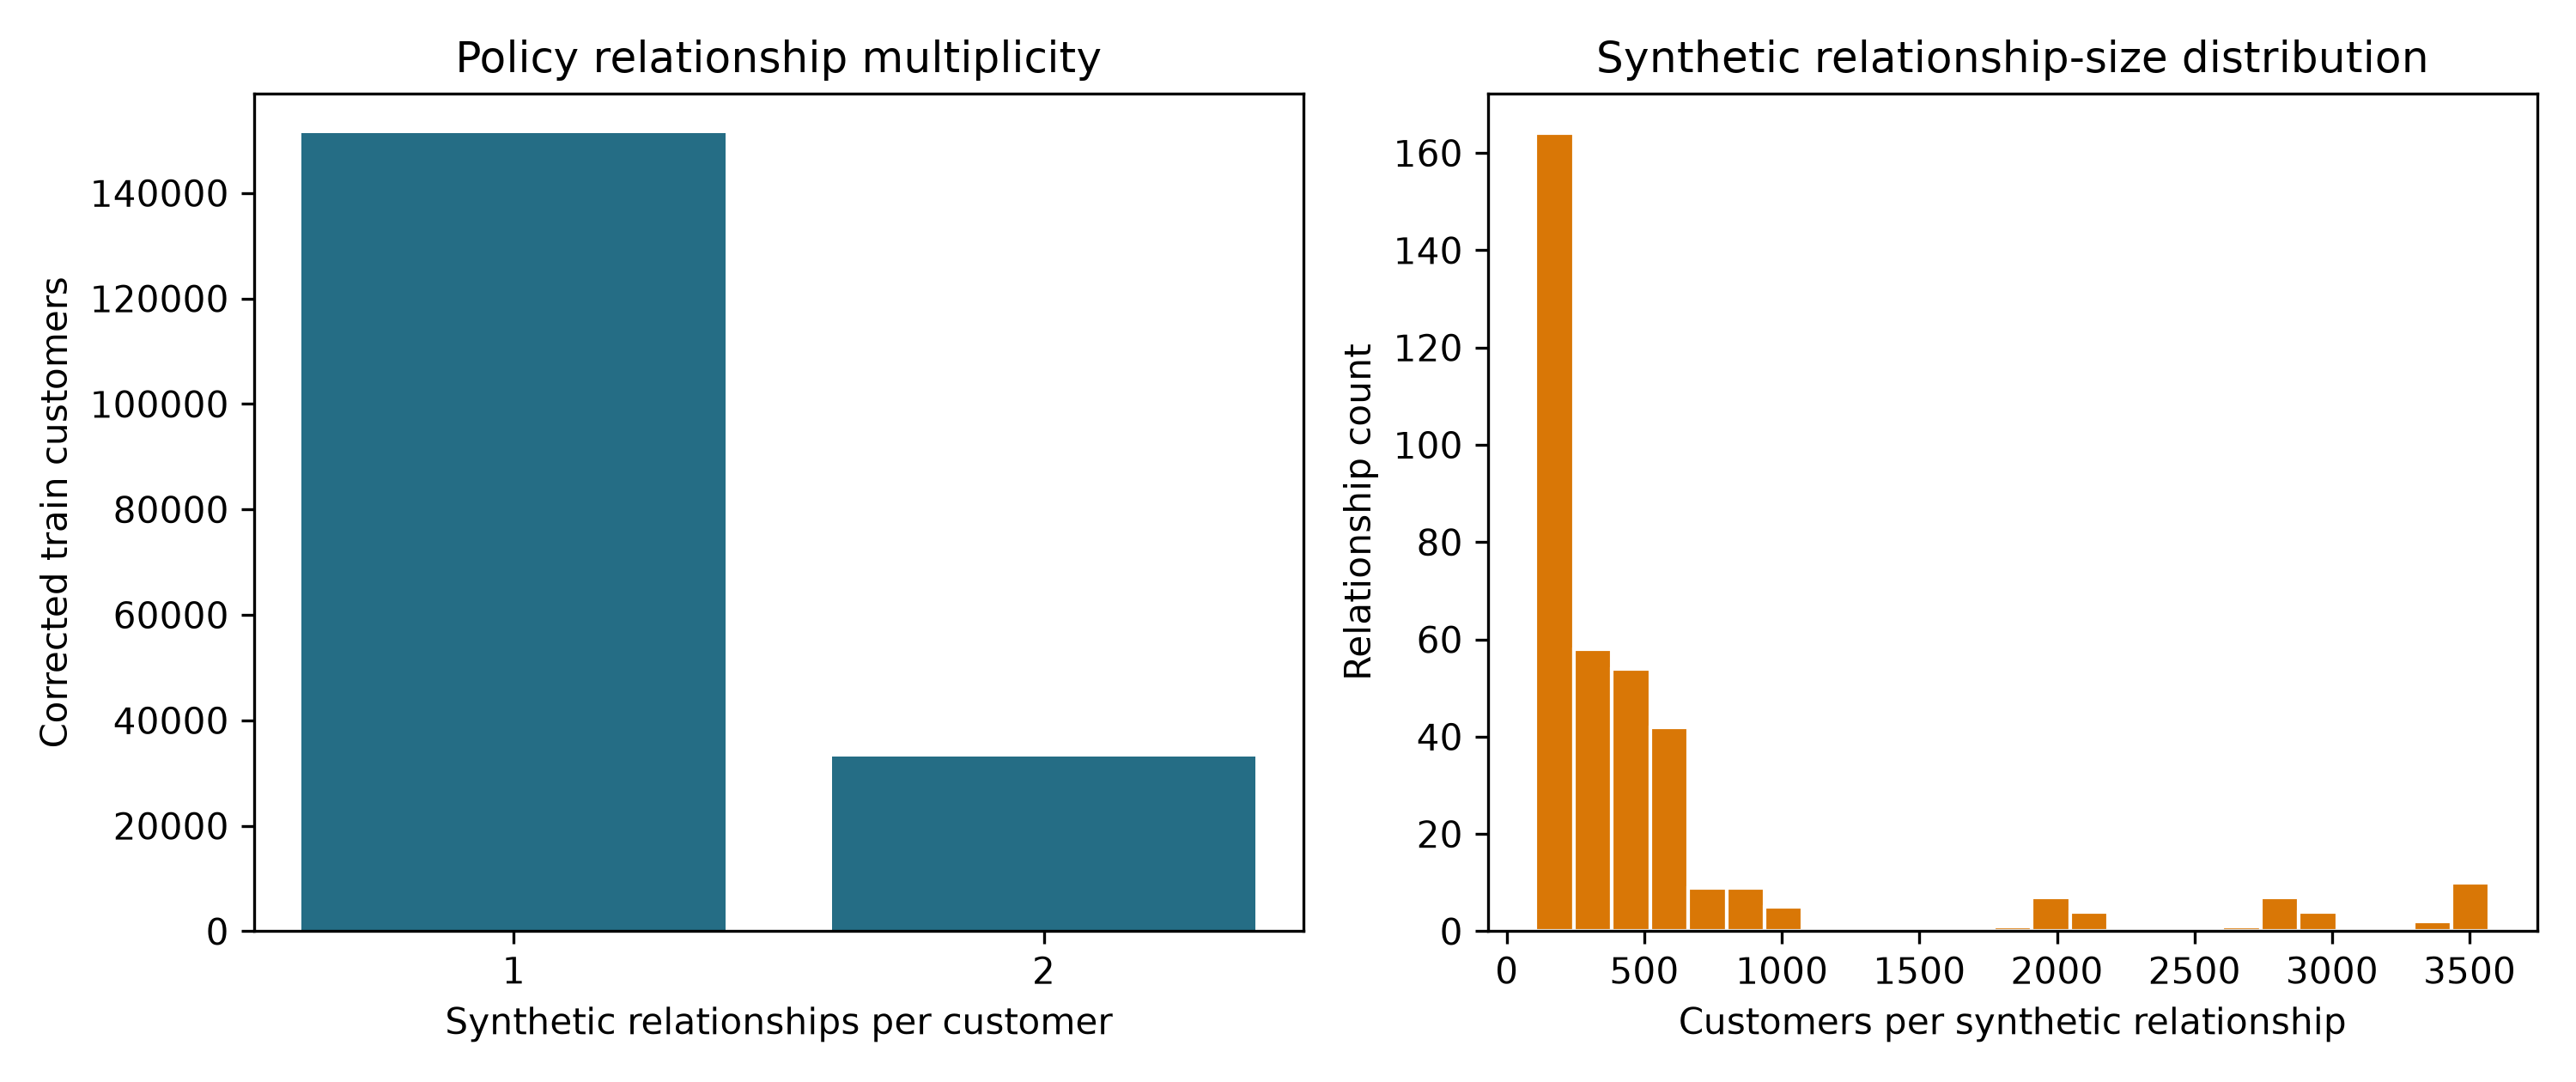

In [34]:
display(Image(filename=DIRS['figures'] / 'policy_relationship_mapping.png'))

**Strict policy:** ลูกค้าที่มี Company X เพียง relationship เดียว eligible เมื่อ X ถูกลบ; ลูกค้าที่มี X+Y ถูก retain เพราะ Y ยังเหลือ. `any` แสดงเป็น explanatory alternative เท่านั้นและไม่ขยาย grid. Policy นี้เป็น operational simulation ไม่ใช่ข้อกำหนด PDPA.

### Nested Specialist constraints

เริ่มจาก corrected Specialist assignment แล้วเคลื่อนเฉพาะ single-relationship customers เมื่อ strict-eligible spread ลดลง, full relationship spread ไม่เพิ่ม, shard size อยู่ใน ±5%, และจำนวน moved customers ทั้งหมดไม่เกิน 10%. การจำกัด movement ทำให้ layer นี้ยังเป็น local optimization.

In [35]:
def nested_specialist_optimization(base_assignment: np.ndarray, mapping: pd.DataFrame,
                                   priority_relationships: list[str]) -> tuple[np.ndarray, pd.DataFrame]:
    """Concentrate strict-eligible relationships subject to hard constraints.

    Only single-relationship customers move.  Therefore a move cannot fragment a
    second relationship.  A complete source-shard block is moved only when the
    strict-eligible spread falls, full membership spread does not increase, and
    both source/target shard sizes remain within ±5% of the equal-size target.
    """
    n = len(base_assignment)
    n_shards = CFG.shards
    nested = base_assignment.copy()
    target_size = n / n_shards
    minimum = int(np.floor(target_size * (1 - BALANCE_TOLERANCE)))
    maximum = int(np.ceil(target_size * (1 + BALANCE_TOLERANCE)))
    load = np.bincount(nested, minlength=n_shards).astype(int)
    maximum_moved = int(np.floor(n * MAX_MOVED_FRACTION))
    moved_total = 0

    full_rows = {name: group.row_index.unique().astype(int)
                 for name, group in mapping.groupby("relationship")}
    eligible_rows = {name: strict_deletion_rows(mapping, name)
                     for name in mapping.loc[mapping.strict_delete_eligible, "relationship"].unique()}
    priority = {name: rank for rank, name in enumerate(priority_relationships)}
    ordered = sorted(eligible_rows, key=lambda name: (
        priority.get(name, len(priority)),
        -len(np.unique(base_assignment[eligible_rows[name]])),
        -len(eligible_rows[name]), str(name)))

    audit = []
    for relationship in ordered:
        eligible = eligible_rows[relationship]
        full = full_rows[relationship]
        base_full_spread = len(np.unique(base_assignment[full]))
        base_eligible_spread = len(np.unique(base_assignment[eligible]))
        before_moves = int(np.sum(nested != base_assignment))
        for _ in range(n_shards - 1):
            counts = np.bincount(nested[eligible], minlength=n_shards)
            present = np.flatnonzero(counts)
            if len(present) <= 1:
                break
            target = int(present[np.argmax(counts[present])])
            changed = False
            for source in present[np.argsort(counts[present])]:
                source = int(source)
                if source == target:
                    continue
                moving = eligible[nested[eligible] == source]
                if moved_total + len(moving) > maximum_moved:
                    continue
                if load[target] + len(moving) > maximum or load[source] - len(moving) < minimum:
                    continue
                old_full_spread = len(np.unique(nested[full]))
                old_eligible_spread = len(np.unique(nested[eligible]))
                nested[moving] = target
                new_full_spread = len(np.unique(nested[full]))
                new_eligible_spread = len(np.unique(nested[eligible]))
                if new_eligible_spread < old_eligible_spread and new_full_spread <= old_full_spread:
                    load[source] -= len(moving)
                    load[target] += len(moving)
                    moved_total += len(moving)
                    changed = True
                    break
                nested[moving] = source
            if not changed:
                break
        audit.append({
            "relationship": relationship, "customers": len(full),
            "strict_eligible_customers": len(eligible),
            "full_spread_before": base_full_spread,
            "full_spread_after": len(np.unique(nested[full])),
            "strict_spread_before": base_eligible_spread,
            "strict_spread_after": len(np.unique(nested[eligible])),
            "customers_moved_for_relationship": int(np.sum(nested != base_assignment)) - before_moves,
            "priority_scenario": relationship in priority,
        })

    audit_frame = pd.DataFrame(audit)
    assert len(nested) == n and np.all((nested >= 0) & (nested < n_shards))
    assert np.bincount(nested, minlength=n_shards).sum() == n
    assert np.all(np.bincount(nested, minlength=n_shards) >= minimum)
    assert np.all(np.bincount(nested, minlength=n_shards) <= maximum)
    assert audit_frame.full_spread_after.le(audit_frame.full_spread_before).all()
    assert audit_frame.strict_spread_after.le(audit_frame.strict_spread_before).all()
    return nested, audit_frame

def _relationship_scenarios(mapping: pd.DataFrame, base_assignment: np.ndarray) -> list[str]:
    eligible = mapping[mapping.strict_delete_eligible].groupby("relationship").row_index.apply(
        lambda values: np.asarray(values, dtype=int))
    candidates = []
    for name, rows in eligible.items():
        if len(rows) >= 200 and len(np.unique(base_assignment[rows])) > 1:
            candidates.append((name, len(rows), len(np.unique(base_assignment[rows]))))
    candidates.sort(key=lambda item: (-item[2], -item[1], str(item[0])))
    assert len(candidates) >= N_RELATIONSHIP_SCENARIOS
    return [item[0] for item in candidates[:N_RELATIONSHIP_SCENARIOS]]

def _locality_results(mapping: pd.DataFrame, base: np.ndarray, nested: np.ndarray,
                      relationships: list[str]) -> pd.DataFrame:
    rows = []
    for scenario, relationship in enumerate(relationships):
        deleted = strict_deletion_rows(mapping, relationship)
        for label, assignment in [("Specialist baseline", base),
                                  ("Specialist + policy-aware nested mapping", nested)]:
            affected = np.unique(assignment[deleted])
            shard_sizes = np.bincount(assignment, minlength=CFG.shards)
            retrained = int(shard_sizes[affected].sum() - len(deleted))
            rows.append({
                "scenario": scenario, "relationship": relationship,
                "policy": "strict", "assignment": label,
                "deleted_customers": len(deleted), "affected_shards": len(affected),
                "affected_shard_fraction": len(affected) / CFG.shards,
                "retrained_rows": retrained,
                "retrained_data_fraction": retrained / (len(assignment) - len(deleted)),
                "locality_score": 1 - (len(affected) - 1) / (CFG.shards - 1),
                "estimated_speedup_from_workload": (len(assignment) - len(deleted)) / max(retrained, 1),
            })
    result = pd.DataFrame(rows)
    atomic_csv(result, DIRS["results"] / "policy_deletion_locality_results.csv")
    summary = result.groupby("assignment", as_index=False).agg(
        scenarios=("scenario", "nunique"), affected_shards_mean=("affected_shards", "mean"),
        affected_shards_sd=("affected_shards", "std"),
        retrained_fraction_mean=("retrained_data_fraction", "mean"),
        retrained_fraction_sd=("retrained_data_fraction", "std"),
        locality_mean=("locality_score", "mean"),
        estimated_speedup_median=("estimated_speedup_from_workload", "median"))
    atomic_csv(summary, DIRS["results"] / "policy_deletion_locality_summary.csv")
    request_rows = []
    _, _, ids = load_matrix("train")
    for scenario, relationship in enumerate(relationships):
        deleted = strict_deletion_rows(mapping, relationship)
        request_rows.extend({"scenario": scenario, "relationship": relationship,
                             "policy": "strict", "row_index": int(row),
                             "SK_ID_CURR": int(ids[row])} for row in deleted)
    pd.DataFrame(request_rows).to_csv(DIRS["results"] / "policy_deletion_requests.csv.gz",
                                      index=False, compression="gzip")
    return result

In [36]:
policy_nested_design = pd.read_csv(DIRS['results'] / 'policy_nested_summary.csv')
display(policy_nested_design.head(40))

,extension,base_sharding,relationship_layer,deletion_policy,balance_tolerance,maximum_moved_fraction,customers,customers_moved,customers_moved_fraction,specialist_assignment_preservation,assignment_adjusted_rand_index,base_mean_dominant_feature_cluster_share,nested_mean_dominant_feature_cluster_share,dominant_feature_cluster_share_change,relationships_improved,relationships_worsened,mean_strict_spread_before,mean_strict_spread_after,max_abs_default_rate_change
0,Policy-Aware / Company-Aware Nested Specialist,Specialist,synthetic company mapping,strict,0.05,0.1,184505,18450,0.099997,0.900003,0.752324,0.802098,0.797373,-0.004725,23,0,4.0,3.896552,0.00292


In [37]:
policy_balance = pd.read_csv(DIRS['results'] / 'policy_nested_balance.csv')
display(policy_balance.head(40))

,shard,base_size,nested_size,base_default_rate,nested_default_rate,base_dominant_feature_cluster_share,nested_dominant_feature_cluster_share
0,0,46127,46032,0.079693,0.080357,0.702734,0.725539
1,1,46126,46747,0.085353,0.083834,1.000000,0.974886
2,2,46126,47459,0.081863,0.079711,1.000000,0.972271
3,3,46126,44267,0.075988,0.078908,0.505658,0.516796


In [38]:
policy_extension_role = pd.read_csv(DIRS['results'] / 'policy_extension_contribution.csv')
display(policy_extension_role.head(40))

,extension,base_sharding,additional_relationship_layer,deletion_policy,intended_operational_locality,observed_workload_effect,utility_effect,limitation
0,Policy-Aware / Company-Aware Nested Specialist,Specialist,synthetic company memberships,strict single-relationship eligibility,concentrate eligible customers for relationshi...,see policy_deletion_locality_summary.csv,see policy_nested_utility.csv,"synthetic, intentionally optimized scenario; g..."


**Configurability axes.** Primary axis ถามว่า training population ควรแบ่งเชิงสถิติอย่างไร (four strategies). Supplementary axis ถามว่าสามารถ align placement เพิ่มเติมกับ operational deletion relationship/policy ได้หรือไม่. Arbitrary mapping ไม่ได้ดีเสมอและมี trade-offs ด้าน balance, utility, complexity, maintenance, fairness และ locality.

## 3.7 Exact vs Approximate Unlearning

- **Exact SISA retraining conditional on a fixed preprocessing pipeline, fixed shard assignment, and fixed aggregation/calibration protocol:** retrain affected shard(s) จาก retained records; untouched shards reuse เดิม
- **Protocol-compatible Gold:** retrain ทุก shard จาก retained records ด้วย seed/configuration และ evaluation protocol เดียวกัน
- **Approximate:** continued boosting จาก original booster; ต้นไม้เดิมยังอยู่ จึงไม่ใช่ exact forgetting
- **Focused slicing:** incremental logistic checkpoints; replay เริ่มจาก earliest affected slice

### Exact and gold implementation across four families

In [39]:
def _original_sisa_models(model_name, assignment):
    models, sizes, fit_times = _fit_or_load_shards(model_name, CFG.shards, assignment)
    return models, sizes, fit_times

def _frozen_original_calibration(models, sizes):
    Xc, yc, _ = load_matrix("calibration"); Xv, yv, _ = load_matrix("validation")
    weights = sizes / sizes.sum()
    cal = fit_platt(_raw_ensemble(models, Xc, weights), yc)
    pv = calibrate(cal, _raw_ensemble(models, Xv, weights))
    threshold = choose_threshold(yv, pv)
    return cal, threshold

def stage_exact_unlearning_four_models():
    checkpoint = DIRS["results"] / "exact_unlearning_four_models.csv"
    if checkpoint.exists() and len(pd.read_csv(checkpoint)) == 4:
        log("Validated four-model exact-unlearning checkpoint")
        return
    stage_sisa_four_models()
    Xtr, ytr, idtr = load_matrix("train"); Xt, yt, idt = load_matrix("test")
    assignment = get_stratified_assignment(ytr, idtr, CFG.shards)
    delete_row = int(assignment.loc[assignment.shard == 0, "row_index"].iloc[0])
    delete_id = int(idtr[delete_row])
    atomic_csv(pd.DataFrame([{"scenario": "single_record", "SK_ID_CURR": delete_id,
                              "original_row_index": delete_row, "original_shard": 0}]),
               DIRS["deletion_requests"] / f"phase2_standard_single_{CFG.hash}.csv")
    completed = pd.read_csv(checkpoint).to_dict("records") if checkpoint.exists() else []
    done_names = {r["model"] for r in completed}
    for model_name in MODEL_NAMES:
        if model_name in done_names:
            continue
        originals, original_sizes, _ = _original_sisa_models(model_name, assignment)
        cal, threshold = _frozen_original_calibration(originals, original_sizes)
        # Exact: only affected shard 0.
        exact_models = list(originals); exact_sizes = original_sizes.copy()
        frame0 = assignment[assignment.shard == 0]
        keep0 = frame0.row_index.to_numpy(); keep0 = keep0[keep0 != delete_row]
        exact_path = DIRS["models"] / f"phase2_exact_single_{_slug(model_name)}_shard0_{CFG.hash}.joblib"
        if exact_path.exists():
            bundle = joblib.load(exact_path); exact_model = bundle["model"]; exact_seconds = bundle["fit_seconds"]
        else:
            started = time.perf_counter(); exact_model = make_model(model_name, CFG.seed + 100)
            exact_model.fit(Xtr[keep0], ytr[keep0]); exact_seconds = time.perf_counter() - started
            joblib.dump({"model": exact_model, "fit_seconds": exact_seconds,
                         "schema_version": SCHEMA_VERSION, "config_hash": CFG.hash}, exact_path, compress=3)
        exact_models[0] = exact_model; exact_sizes[0] -= 1
        # Gold: retrain every shard from retained data, identical seeds/configuration.
        gold_models, gold_sizes, gold_seconds = [], [], 0.0
        for shard in range(CFG.shards):
            rows = assignment.loc[assignment.shard == shard, "row_index"].to_numpy()
            rows = rows[rows != delete_row]
            path = DIRS["models"] / f"phase2_gold_single_{_slug(model_name)}_shard{shard}_{CFG.hash}.joblib"
            if path.exists():
                bundle = joblib.load(path); model = bundle["model"]; elapsed = bundle["fit_seconds"]
            else:
                started = time.perf_counter(); model = make_model(model_name, CFG.seed + 100 + shard)
                model.fit(Xtr[rows], ytr[rows]); elapsed = time.perf_counter() - started
                joblib.dump({"model": model, "fit_seconds": elapsed,
                             "schema_version": SCHEMA_VERSION, "config_hash": CFG.hash}, path, compress=3)
            gold_models.append(model); gold_sizes.append(len(rows)); gold_seconds += elapsed
        exact_w = exact_sizes / exact_sizes.sum(); gold_w = np.asarray(gold_sizes) / sum(gold_sizes)
        p_exact = calibrate(cal, _raw_ensemble(exact_models, Xt, exact_w))
        p_gold = calibrate(cal, _raw_ensemble(gold_models, Xt, gold_w)); diff = p_exact - p_gold
        completed.append({"model": model_name, "scenario": "single_record",
                          "deleted_records": 1, "affected_shards": 1,
                          "workload_fraction": 1/CFG.shards, "exact_seconds": exact_seconds,
                          "gold_seconds": gold_seconds, "speedup": gold_seconds/max(exact_seconds,1e-9),
                          "prediction_mae": np.mean(np.abs(diff)),
                          "prediction_rmse": np.sqrt(np.mean(diff**2)),
                          "max_probability_difference": np.max(np.abs(diff)),
                          "prediction_disagreement": np.mean((p_exact>=threshold)!=(p_gold>=threshold)),
                          "exact_roc_auc": roc_auc_score(yt,p_exact), "gold_roc_auc": roc_auc_score(yt,p_gold)})
        atomic_csv(pd.DataFrame(completed), checkpoint)
        np.savez_compressed(DIRS["results"] / f"phase2_exact_gold_single_{_slug(model_name)}_{CFG.hash}.npz",
                            ids=idt, y=yt, exact=p_exact, gold=p_gold)
        log(f"Four-model exact: {model_name}, speedup={completed[-1]['speedup']:.2f}x, MAE={completed[-1]['prediction_mae']:.3g}")
        del originals, exact_models, gold_models
        gc.collect()
    update_manifest("exact_unlearning_four_models", "complete",
                    ["results/exact_unlearning_four_models.csv", "results/phase2_exact_gold_single_*.npz"],
                    "One standardized single-record scenario; descriptive cross-model evidence with compatible seeds.")

### Focused slicing implementation

In [40]:
def _partial_fit_sequence(X, y, slices, checkpoint_dir: Path, prefix: str, delete_rows=None):
    model = None; checkpoints = []; elapsed = 0.0
    delete_rows = set() if delete_rows is None else set(delete_rows)
    for r, rows in enumerate(slices):
        use = np.array([idx for idx in rows if int(idx) not in delete_rows], dtype=int)
        if model is None:
            model = SGDClassifier(loss="log_loss", alpha=1e-4, average=True,
                                  random_state=CFG.seed, max_iter=1, tol=None, shuffle=False)
            started = time.perf_counter()
            for epoch in range(3):
                model.partial_fit(X[use], y[use], classes=np.array([0,1]) if epoch == 0 else None)
            elapsed += time.perf_counter()-started
        else:
            started = time.perf_counter()
            for _ in range(3): model.partial_fit(X[use], y[use])
            elapsed += time.perf_counter()-started
        path = checkpoint_dir / f"{prefix}_slice{r}.joblib"; joblib.dump(model, path, compress=3); checkpoints.append(path)
    return model, elapsed, checkpoints

def stage_slicing_demo():
    checkpoint = DIRS["results"] / "slicing_demonstration.csv"
    if (checkpoint.exists() and "preprocessing" in pd.read_csv(checkpoint).columns and
            set(pd.read_csv(checkpoint).slices) == {1, 4}):
        log("Validated slicing demonstration checkpoint")
        return
    stage_deletion_scale_locality()
    Xtr, ytr, idtr = load_matrix("train"); Xt, yt, _ = load_matrix("test")
    scaler_path = DIRS["models"] / f"slicing_maxabs_scaler_{CFG.hash}.joblib"
    if scaler_path.exists():
        scaler = joblib.load(scaler_path)
    else:
        scaler = MaxAbsScaler().fit(Xtr); joblib.dump(scaler, scaler_path, compress=3)
    Xtr = scaler.transform(Xtr); Xt = scaler.transform(Xt)
    assignment = get_stratified_assignment(ytr, idtr, CFG.shards)
    results = []
    for n_slices in [1, 4]:
        shard_models, slice_maps = [], {}
        setup_dir = DIRS["models"] / f"slicing_scaled_v2_S{CFG.shards}_R{n_slices}_{CFG.hash}"
        setup_dir.mkdir(exist_ok=True)
        total_rows = 0
        for shard in range(CFG.shards):
            rows = assignment.loc[assignment.shard == shard, "row_index"].to_numpy(copy=True)
            rng = np.random.default_rng(CFG.seed + shard); rng.shuffle(rows)
            slices = [np.asarray(x, dtype=int) for x in np.array_split(rows, n_slices)]
            slice_maps[shard] = slices; total_rows += len(rows)
            model, _, _ = _partial_fit_sequence(Xtr, ytr, slices, setup_dir, f"original_shard{shard}")
            shard_models.append(model)
        # Delete one deterministic record from the last slice of shard 0.
        delete_row = int(slice_maps[0][-1][0]); earliest = n_slices - 1
        replay_started = time.perf_counter()
        if earliest == 0:
            exact, _, _ = _partial_fit_sequence(Xtr, ytr, slice_maps[0], setup_dir,
                                                f"exact_R{n_slices}", {delete_row})
        else:
            exact = joblib.load(setup_dir / f"original_shard0_slice{earliest-1}.joblib")
            for rows in slice_maps[0][earliest:]:
                use = rows[rows != delete_row]
                for _ in range(3): exact.partial_fit(Xtr[use], ytr[use])
        replay_seconds = time.perf_counter() - replay_started
        gold_models = []
        gold_started = time.perf_counter()
        for shard in range(CFG.shards):
            deleted = {delete_row} if shard == 0 else set()
            gold, _, _ = _partial_fit_sequence(Xtr, ytr, slice_maps[shard], setup_dir,
                                               f"gold_R{n_slices}_shard{shard}", deleted)
            gold_models.append(gold)
        gold_seconds = time.perf_counter() - gold_started
        exact_models = list(shard_models); exact_models[0] = exact
        weights = assignment.groupby("shard").size().to_numpy(dtype=float); weights /= weights.sum()
        p_exact = _raw_ensemble(exact_models, Xt, weights); p_gold = _raw_ensemble(gold_models, Xt, weights)
        diff = p_exact - p_gold
        replay_rows = sum(len(x) for x in slice_maps[0][earliest:])
        results.append({"model": "SGD logistic (incremental LR)",
                        "preprocessing": "train-fitted MaxAbsScaler; 3 deterministic passes/slice",
                        "shards": CFG.shards,
                        "slices": n_slices, "deleted_records": 1, "earliest_affected_slice": earliest,
                        "replayed_rows": replay_rows, "affected_shard_rows": sum(map(len,slice_maps[0])),
                        "replayed_fraction_of_affected_shard": replay_rows/sum(map(len,slice_maps[0])),
                        "replay_seconds": replay_seconds, "gold_all_shards_seconds": gold_seconds,
                        "speedup_vs_gold": gold_seconds/max(replay_seconds,1e-9),
                        "prediction_mae": np.mean(np.abs(diff)),
                        "max_probability_difference": np.max(np.abs(diff)),
                        "exact_roc_auc": roc_auc_score(yt,p_exact), "gold_roc_auc": roc_auc_score(yt,p_gold)})
        atomic_csv(pd.DataFrame(results), DIRS["results"] / "slicing_demonstration.csv")
        log(f"Slicing R={n_slices}: replayed={results[-1]['replayed_fraction_of_affected_shard']:.1%}, MAE={results[-1]['prediction_mae']:.3g}")
    update_manifest("slicing_demonstration", "complete", ["results/slicing_demonstration.csv"],
                    "Focused deterministic partial-fit logistic experiment with slice checkpoints and gold replay; not claimed for batch LR/RF/boosting models.")

### Approximate continued boosting implementation

In [41]:
def stage_approximate_two_boosters():
    checkpoint = DIRS["results"] / "approximate_two_boosters.csv"
    if checkpoint.exists() and len(pd.read_csv(checkpoint)) == 2:
        log("Validated two-booster approximate checkpoint")
        return
    stage_exact_unlearning_four_models()
    Xtr, ytr, idtr = load_matrix("train"); Xt, yt, _ = load_matrix("test")
    assignment = get_stratified_assignment(ytr, idtr, CFG.shards)
    request = pd.read_csv(DIRS["deletion_requests"] / f"phase2_standard_single_{CFG.hash}.csv").iloc[0]
    delete_row = int(request.original_row_index)
    rows0 = assignment.loc[assignment.shard == 0, "row_index"].to_numpy(); rows0 = rows0[rows0 != delete_row]
    completed = pd.read_csv(checkpoint).to_dict("records") if checkpoint.exists() else []
    done_names = {r["model"] for r in completed}
    for model_name in ["LightGBM", "XGBoost"]:
        if model_name in done_names:
            continue
        originals, sizes, _ = _original_sisa_models(model_name, assignment)
        cal, threshold = _frozen_original_calibration(originals, sizes)
        approx_path = DIRS["models"] / f"phase2_approx_single_{_slug(model_name)}_shard0_{CFG.hash}.joblib"
        if approx_path.exists():
            bundle = joblib.load(approx_path); approximate = bundle["model"]; seconds = bundle["fit_seconds"]
        else:
            approximate = make_model(model_name, CFG.seed + 900)
            approximate.set_params(n_estimators=60, learning_rate=0.02)
            started = time.perf_counter()
            if model_name == "LightGBM":
                approximate.fit(Xtr[rows0], ytr[rows0], init_model=originals[0].booster_)
            else:
                approximate.fit(Xtr[rows0], ytr[rows0], xgb_model=originals[0].get_booster())
            seconds = time.perf_counter() - started
            joblib.dump({"model": approximate, "fit_seconds": seconds,
                         "method": "continued_boosting_heuristic", "schema_version": SCHEMA_VERSION,
                         "config_hash": CFG.hash}, approx_path, compress=3)
        models = list(originals); models[0] = approximate; retained_sizes = sizes.copy(); retained_sizes[0] -= 1
        p_approx = calibrate(cal, _raw_ensemble(models, Xt, retained_sizes/retained_sizes.sum()))
        gold = np.load(DIRS["results"] / f"phase2_exact_gold_single_{_slug(model_name)}_{CFG.hash}.npz")["gold"]
        diff = p_approx - gold
        completed.append({"model": model_name, "method": "continued_boosting_heuristic",
                          "scenario": "single_record", "approx_seconds": seconds,
                          "prediction_mae": np.mean(np.abs(diff)),
                          "prediction_rmse": np.sqrt(np.mean(diff**2)),
                          "max_probability_difference": np.max(np.abs(diff)),
                          "prediction_disagreement": np.mean((p_approx>=threshold)!=(gold>=threshold)),
                          "approx_roc_auc": roc_auc_score(yt,p_approx), "gold_roc_auc": roc_auc_score(yt,gold)})
        atomic_csv(pd.DataFrame(completed), checkpoint)
        log(f"Approximate two-booster: {model_name}, MAE={completed[-1]['prediction_mae']:.4f}")
    update_manifest("approximate_two_boosters", "complete", ["results/approximate_two_boosters.csv"],
                    "Continued boosting evaluated only for LightGBM/XGBoost; unsupported LR/RF approximate methods are not invented.")

## 3.8 Gold-Standard Fidelity Evaluation

### 3.8.1 Direct Deletion Audit

In [42]:
deletion_audit = pd.read_csv(DIRS['results'] / 'direct_deletion_audit.csv')
display(deletion_audit.head(40))

,model,SK_ID_CURR,assigned_shard,present_before,present_in_exact_training,present_in_gold_training,affected_shard_rows_before,affected_shard_rows_after,audit_status
0,Logistic Regression,100008,0,1,0,0,46127,46126,PASS
1,Random Forest,100008,0,1,0,0,46127,46126,PASS
2,LightGBM,100008,0,1,0,0,46127,46126,PASS
3,XGBoost,100008,0,1,0,0,46127,46126,PASS


**Audit result.** `SK_ID_CURR=100008` อยู่ก่อนลบและไม่อยู่ใน exact/gold retained training rows; affected shard ลด 46,127 → 46,126 สำหรับทุก family.

### 3.8.2 Model Fidelity

In [43]:
method_fidelity = pd.read_csv(DIRS['results'] / 'fidelity_detailed_four_models.csv')
display(method_fidelity.head(40))

,model,scenario,exact_gold_mae,exact_gold_rmse,exact_gold_max_abs,exact_gold_correlation,exact_gold_auc_difference,exact_gold_ap_difference,exact_gold_decision_disagreement,original_exact_mae,original_exact_decision_change
0,Logistic Regression,single_record,0.000000e+00,0.000000e+00,0.000000e+00,1.0,0.0,0.0,0.0,0.000062,0.000260
1,Random Forest,single_record,3.373096e-18,1.834783e-17,4.440892e-16,1.0,0.0,0.0,0.0,0.002955,0.010059
2,LightGBM,single_record,0.000000e+00,0.000000e+00,0.000000e+00,1.0,0.0,0.0,0.0,0.003147,0.008932
3,XGBoost,single_record,0.000000e+00,0.000000e+00,0.000000e+00,1.0,0.0,0.0,0.0,0.003068,0.007328


### 3.8.3 Forget-set Behavior

In [44]:
method_forget_behavior = pd.read_csv(DIRS['results'] / 'forget_set_behavior_four_models.csv')
display(method_forget_behavior.head(40))

,model,SK_ID_CURR,target,threshold,original_probability,exact_probability,gold_probability,original_to_exact_change,exact_gold_absolute_difference,original_decision,exact_decision,gold_decision
0,Logistic Regression,100008,0,0.140,0.077738,0.077822,0.077822,0.000084,0.0,0,0,0
1,Random Forest,100008,0,0.130,0.115244,0.119730,0.119730,0.004486,0.0,0,0,0
2,LightGBM,100008,0,0.155,0.087604,0.084086,0.084086,-0.003517,0.0,0,0,0
3,XGBoost,100008,0,0.165,0.103105,0.102658,0.102658,-0.000447,0.0,0,0,0


### 3.8.4 Cross-model Validation

In [45]:
method_cross_model = pd.read_csv(DIRS['results'] / 'exact_unlearning_four_models.csv')
display(method_cross_model.head(40))

,model,scenario,deleted_records,affected_shards,workload_fraction,exact_seconds,gold_seconds,speedup,prediction_mae,prediction_rmse,max_probability_difference,prediction_disagreement,exact_roc_auc,gold_roc_auc,affected_data_fraction,actual_retrained_fraction,legacy_workload_definition
0,Logistic Regression,single_record,1,1,0.25,3.927141,14.605070,3.719008,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.754475,0.754475,0.250004,0.25,workload_fraction approximated affected_data_f...
1,Random Forest,single_record,1,1,0.25,46.760358,201.316860,4.305289,3.373096e-18,1.834783e-17,4.440892e-16,0.0,0.745859,0.745859,0.250004,0.25,workload_fraction approximated affected_data_f...
2,LightGBM,single_record,1,1,0.25,2.694320,11.671968,4.332065,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.766285,0.766285,0.250004,0.25,workload_fraction approximated affected_data_f...
3,XGBoost,single_record,1,1,0.25,4.668463,15.691439,3.361157,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.769013,0.769013,0.250004,0.25,workload_fraction approximated affected_data_f...


In [46]:
def fidelity_metrics(y, exact, gold, threshold):
    difference = exact - gold
    return {'mae': np.mean(np.abs(difference)),
            'rmse': np.sqrt(np.mean(difference**2)),
            'max_abs': np.max(np.abs(difference)),
            'correlation': np.corrcoef(exact, gold)[0,1],
            'auc_difference': roc_auc_score(y, exact)-roc_auc_score(y, gold),
            'ap_difference': average_precision_score(y, exact)-average_precision_score(y, gold),
            'decision_disagreement': np.mean((exact>=threshold)!=(gold>=threshold))}

## 3.9 Membership Inference Attack

Attack score เป็น negative per-record log loss. Positive examples ยืนยันว่าเป็นสมาชิกของ attacked shard; nonmembers มาจาก validation. AUC < 0.55 ถูกกำหนดล่วงหน้าให้รายงานว่า inconclusive ไม่ใช่ privacy success.

In [47]:
def _membership_score(model, X, y):
    p = np.clip(positive_probability(model, X), 1e-7, 1 - 1e-7)
    return np.where(y == 1, np.log(p), np.log(1 - p))

def stage_mia() -> None:
    """Focused loss-based MIA with verified members of one attacked shard."""
    stage_exact_unlearning()
    Xtr, ytr, _ = load_matrix("train")
    Xv, yv, _ = load_matrix("validation")
    assignment = pd.read_csv(DIRS["shards"] / f"stratified_S{CFG.shards}_{CFG.hash}.csv")
    requests = pd.read_csv(DIRS["deletion_requests"] / f"random_f{CFG.deletion_fraction}_R{CFG.deletion_repetitions}_{CFG.hash}.csv")
    deleted = set(requests.loc[requests.repetition == 0, "SK_ID_CURR"].astype(int))
    shard = 0
    frame = assignment[assignment.shard == shard]
    deleted_frame = frame[frame.SK_ID_CURR.isin(deleted)]
    retained_frame = frame[~frame.SK_ID_CURR.isin(deleted)]
    assert len(deleted_frame) > 0 and not deleted_frame.SK_ID_CURR.isin(retained_frame.SK_ID_CURR).any()
    original = joblib.load(DIRS["models"] / f"sisa_lightgbm_S{CFG.shards}_shard{shard}_{CFG.hash}.joblib")["model"]
    exact_path = DIRS["models"] / f"mia_gold_rep0_shard{shard}_{CFG.hash}.joblib"
    if exact_path.exists():
        exact = joblib.load(exact_path)["model"]
    else:
        exact = make_model("LightGBM", CFG.seed + 100 + shard)
        exact.fit(Xtr[retained_frame.row_index.to_numpy()], ytr[retained_frame.row_index.to_numpy()])
        joblib.dump({"model": exact, "schema_version": SCHEMA_VERSION, "config_hash": CFG.hash}, exact_path, compress=3)
    rng = np.random.default_rng(CFG.seed + 700)
    n = min(5000, len(retained_frame), len(yv))
    member_rows = rng.choice(retained_frame.row_index.to_numpy(), n, replace=False)
    nonmember_rows = rng.choice(np.arange(len(yv)), n, replace=False)
    labels = np.r_[np.ones(n), np.zeros(n)]
    rows = []
    for model_name, model in [("original", original), ("exact_and_gold", exact)]:
        scores = np.r_[_membership_score(model, Xtr[member_rows], ytr[member_rows]),
                       _membership_score(model, Xv[nonmember_rows], yv[nonmember_rows])]
        auc = roc_auc_score(labels, scores)
        threshold = np.quantile(scores[n:], .95)
        deleted_score = _membership_score(model, Xtr[deleted_frame.row_index.to_numpy()],
                                           ytr[deleted_frame.row_index.to_numpy()])
        rows.append({"model_state": model_name, "attacked_shard": shard,
                     "verified_members": n, "verified_nonmembers": n,
                     "deleted_records_in_shard": len(deleted_frame), "attack_auc": auc,
                     "attack_power": "meaningful" if auc >= .55 else "inconclusive",
                     "deleted_inferred_member_rate_at_5pct_fpr": np.mean(deleted_score >= threshold)})
    atomic_csv(pd.DataFrame(rows), DIRS["results"] / "privacy_mia.csv")
    update_manifest("privacy_mia", "complete", ["results/privacy_mia.csv", str(exact_path)],
                    "Loss-based focused attack; membership in attacked shard verified. AUC below 0.55 is reported as inconclusive.")
    log(f"Focused MIA complete; original attack AUC={rows[0]['attack_auc']:.3f}")

**Scope boundary.** เป็น focused loss-based attack ไม่ใช่ comprehensive privacy audit และไม่ได้ใช้ shadow models.

## 3.10 Deletion Workload and Computational Cost

Utility ใช้ ROC-AUC/AP/KS/Brier; fidelity ใช้ MAE/RMSE/max/correlation/AUC-AP difference/disagreement. สำหรับ request $D$, original train size $N$, deleted rows $|D|$, affected shards $A(D)$ และ original shard size $n_s$ นิยามสองค่าที่ห้ามใช้แทนกัน:

$$affected\_data\_fraction=\\frac{\\sum_{s\\in A(D)}n_s}{N}$$

$$actual\_retrained\_fraction=\\frac{\\sum_{s\\in A(D)}n_s-|D|}{N-|D|}$$

คอลัมน์ legacy `retraining_workload_fraction` หมายถึง **affected_data_fraction**; ส่วน policy legacy `retrained_data_fraction` หมายถึง **actual_retrained_fraction**. ทั้งสองถูกเก็บเพื่อ compatibility พร้อมคอลัมน์ชื่อชัดเจน. Estimated speedup ถูกแยกจาก measured wall-clock speedupและไม่ถูกเรียกว่า monetary cost.

In [48]:
def ks_statistic(y, p) -> float:
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))

In [49]:
def metrics(y: np.ndarray, p: np.ndarray, threshold: float) -> dict:
    pred = p >= threshold
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "roc_auc": roc_auc_score(y, p), "average_precision": average_precision_score(y, p),
        "log_loss": log_loss(y, p), "brier": brier_score_loss(y, p),
        "threshold": threshold, "f1": f1_score(y, pred),
        "sensitivity": tp / max(tp + fn, 1), "specificity": tn / max(tn + fp, 1),
    }

In [50]:
def _runtime_benchmark(mapping: pd.DataFrame, base: np.ndarray, nested: np.ndarray,
                       relationships: list[str]) -> None:
    X, y, _ = load_matrix("train")
    rows = []
    for scenario, relationship in enumerate(relationships[:N_RUNTIME_SCENARIOS]):
        deleted = strict_deletion_rows(mapping, relationship)
        for repeat in range(RUNTIME_REPEATS):
            for label, assignment in [("Specialist baseline", base),
                                      ("Specialist + policy-aware nested mapping", nested)]:
                affected = np.unique(assignment[deleted])
                started = time.perf_counter()
                for shard in affected:
                    train_rows = np.flatnonzero(assignment == shard)
                    train_rows = train_rows[~np.isin(train_rows, deleted)]
                    model = make_model("LightGBM", POLICY_SEED + repeat * 100 + int(shard))
                    model.fit(X[train_rows], y[train_rows])
                    del model
                seconds = time.perf_counter() - started
                rows.append({"scenario": scenario, "relationship": relationship,
                             "repeat": repeat, "assignment": label,
                             "affected_shards": len(affected),
                             "retraining_seconds": seconds})
                gc.collect()
    runtime = pd.DataFrame(rows)
    atomic_csv(runtime, DIRS["results"] / "policy_deletion_runtime.csv")
    summary = runtime.groupby("assignment", as_index=False).agg(
        measurements=("retraining_seconds", "size"),
        mean_seconds=("retraining_seconds", "mean"),
        sd_seconds=("retraining_seconds", "std"),
        median_seconds=("retraining_seconds", "median"))
    atomic_csv(summary, DIRS["results"] / "policy_deletion_runtime_summary.csv")

## 3.11 Experimental Protocol and Evaluation Criteria

In [51]:
protocol = pd.read_csv(DIRS['results'] / 'experimental_protocol.csv')
display(protocol.head(40))

,component,definition
0,data roles,train fits preprocessing/models; calibration f...
1,randomness,master seed=20260920; deterministic derived se...
2,SISA comparison,"same S=4 assignment, model family, retained-si..."
3,exact unlearning,retrain only affected shard(s) from retained r...
4,gold retraining,retrain every shard from retained records with...
5,approximate unlearning,continued boosting heuristic; evaluated only f...
6,runtime,wall-clock fit/retrain time on one local machi...
7,statistical scope,paired n=10 locality requests use bootstrap CI...


Repetitions มีเท่าที่ออกแบบจริง: locality ใช้ paired n=10; phase-1 exact diffuse deletion ใช้ n=3 และรายงานเชิง descriptive. Single-record cross-model เป็น standardized scenario หนึ่งชุด ไม่อ้าง confidence interval ข้าม records.

## 3.12 Tools and Experimental Environment

In [52]:
print(json.dumps(json.loads((DIRS['config'] / 'environment_detailed.json').read_text(encoding='utf-8')), indent=2))

{
  "schema_version": "home-credit-sisa-final-v1",
  "config_hash": "750d68aae1b6",
  "python": "3.12.14",
  "platform": "Windows-11-10.0.26200-SP0",
  "processor": "Intel64 Family 6 Model 186 Stepping 2, GenuineIntel",
  "logical_cpu_count": 12,
  "installed_ram_gib": 15.695304870605469,
  "configured_threads": 2,
  "seed": 20260920
}


In [53]:
manifest = json.loads((DIRS['config'] / 'experiment_manifest.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'stage': name, **details} for name, details in manifest['stages'].items()])
        [['stage','status','completed_at','notes']])

,stage,status,completed_at,notes
0,data_partitions,complete,2026-09-20T15:16:35,Final test is isolated before all model/config...
1,corrected_preprocessing,complete,2026-09-20T15:19:48,Applicant IDs and targets asserted before/afte...
2,baseline_models,complete,2026-09-20T15:55:11,Calibration fitted on calibration split; thres...
3,standard_sisa,complete,2026-09-20T15:55:18,Pre-specified S=4; stratified balanced shards;...
4,exact_sisa_vs_gold,complete,2026-09-20T15:33:54,Exact SISA retraining conditional on fixed tra...
5,controlled_sharding,complete,2026-09-20T15:31:36,"S, model, seeds, splits, aggregation, calibrat..."
6,reporting_core,complete,2026-09-20T15:35:44,Figures derive only from saved corrected-pipel...
7,approximate_unlearning,complete,2026-09-20T15:33:46,Continued boosting retains original trees and ...
8,privacy_mia,complete,2026-09-20T15:33:59,Loss-based focused attack; membership in attac...
9,sisa_four_models,complete,2026-09-20T15:55:43,Common S=4 stratified-balanced assignment and ...


**Reproducibility note.** ทุก artifact ผูกกับ schema/config hash; seeds และ thread cap ถูกตรึง. Runtime เป็นผลจากเครื่อง local เครื่องนี้ ไม่ควรตีความเป็น benchmark ของ production infrastructure.

# Chapter 4 — Results and Discussion / ผลการทดลองและอภิปรายผล

## 4.1 Baseline Model Performance

In [54]:
dataset_summary = pd.read_csv(DIRS['results'] / 'dataset_summary.csv')
display(dataset_summary.head(40))

,item,value
0,Applicants,307511.000000
1,Defaults,24825.000000
2,Default rate,0.080729
3,Corrected transformed features,182.000000
4,Raw data sources,5.000000


In [55]:
baseline = pd.read_csv(DIRS['results'] / 'baseline_performance_complete.csv')
display(baseline[['model', 'roc_auc', 'average_precision', 'ks', 'brier', 'threshold', 'f1', 'sensitivity', 'specificity', 'fit_seconds']].head(40))

,model,roc_auc,average_precision,ks,brier,threshold,f1,sensitivity,specificity,fit_seconds
0,Logistic Regression,0.754891,0.234573,0.382488,0.068128,0.145,0.304623,0.438776,0.873358,22.278107
1,Random Forest,0.747230,0.223192,0.373641,0.068680,0.135,0.289420,0.455424,0.851426,354.538574
2,LightGBM,0.768972,0.259649,0.408259,0.067085,0.170,0.314259,0.412191,0.893640,9.350336
3,XGBoost,0.768174,0.261380,0.408869,0.066991,0.180,0.316378,0.372449,0.913756,11.829097


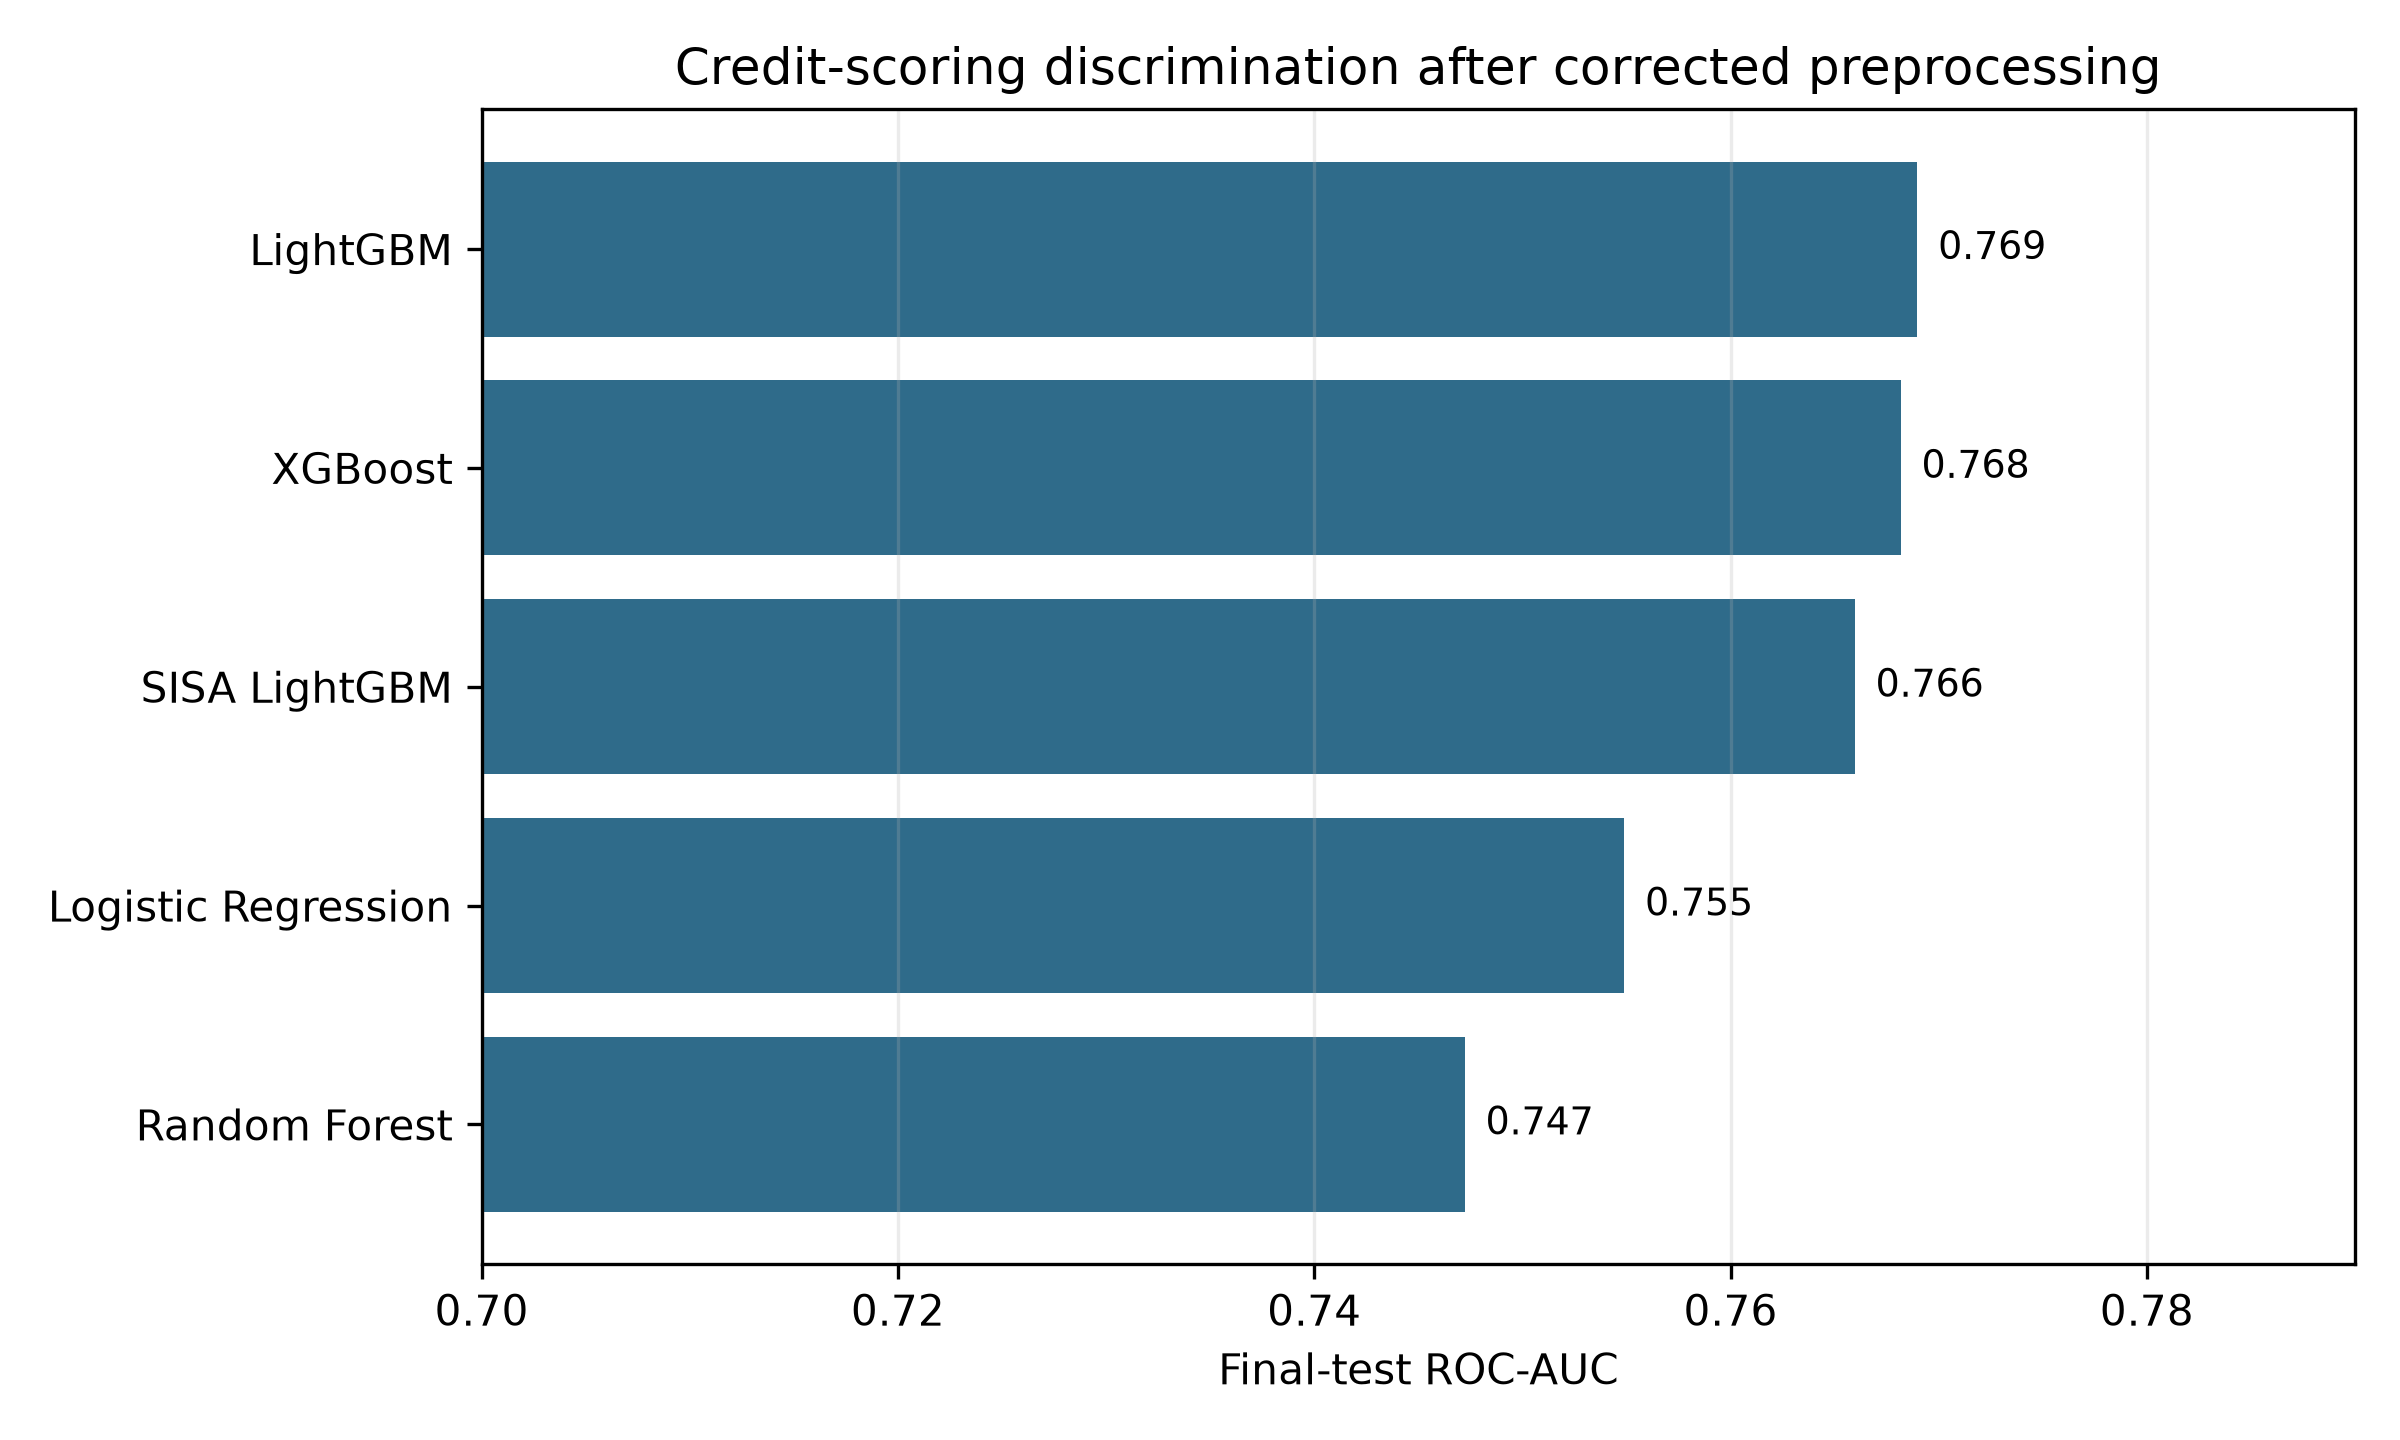

In [56]:
display(Image(filename=DIRS['figures'] / 'baseline_and_sisa_auc.png'))

**Interpretation.** Corrected pipeline ใช้ผู้สมัคร 307,511 รายและ 182 transformed features. LightGBM ให้ baseline ROC-AUC สูงสุดประมาณ 0.769; XGBoost ใกล้เคียงที่สุด ขณะที่ RF ใช้เวลาฝึกมากที่สุดบนเครื่องนี้.

## 4.2 Sharding Strategy Results

### SISA applicability across four model families

In [57]:
sisa_models = pd.read_csv(DIRS['results'] / 'sisa_four_model_comparison.csv')
display(sisa_models[['model', 'baseline_roc_auc', 'sisa_roc_auc', 'roc_auc_delta', 'sisa_average_precision', 'sisa_ks', 'sisa_brier', 'sisa_total_fit_seconds']].head(40))

,model,baseline_roc_auc,sisa_roc_auc,roc_auc_delta,sisa_average_precision,sisa_ks,sisa_brier,sisa_total_fit_seconds
0,Logistic Regression,0.754891,0.754480,-0.000410,0.235468,0.378704,0.068107,17.492872
1,Random Forest,0.747230,0.745341,-0.001890,0.218126,0.371500,0.068908,222.540560
2,LightGBM,0.768972,0.765968,-0.003005,0.254092,0.401034,0.067332,12.330813
3,XGBoost,0.768174,0.769156,0.000982,0.260944,0.407558,0.066990,15.521894


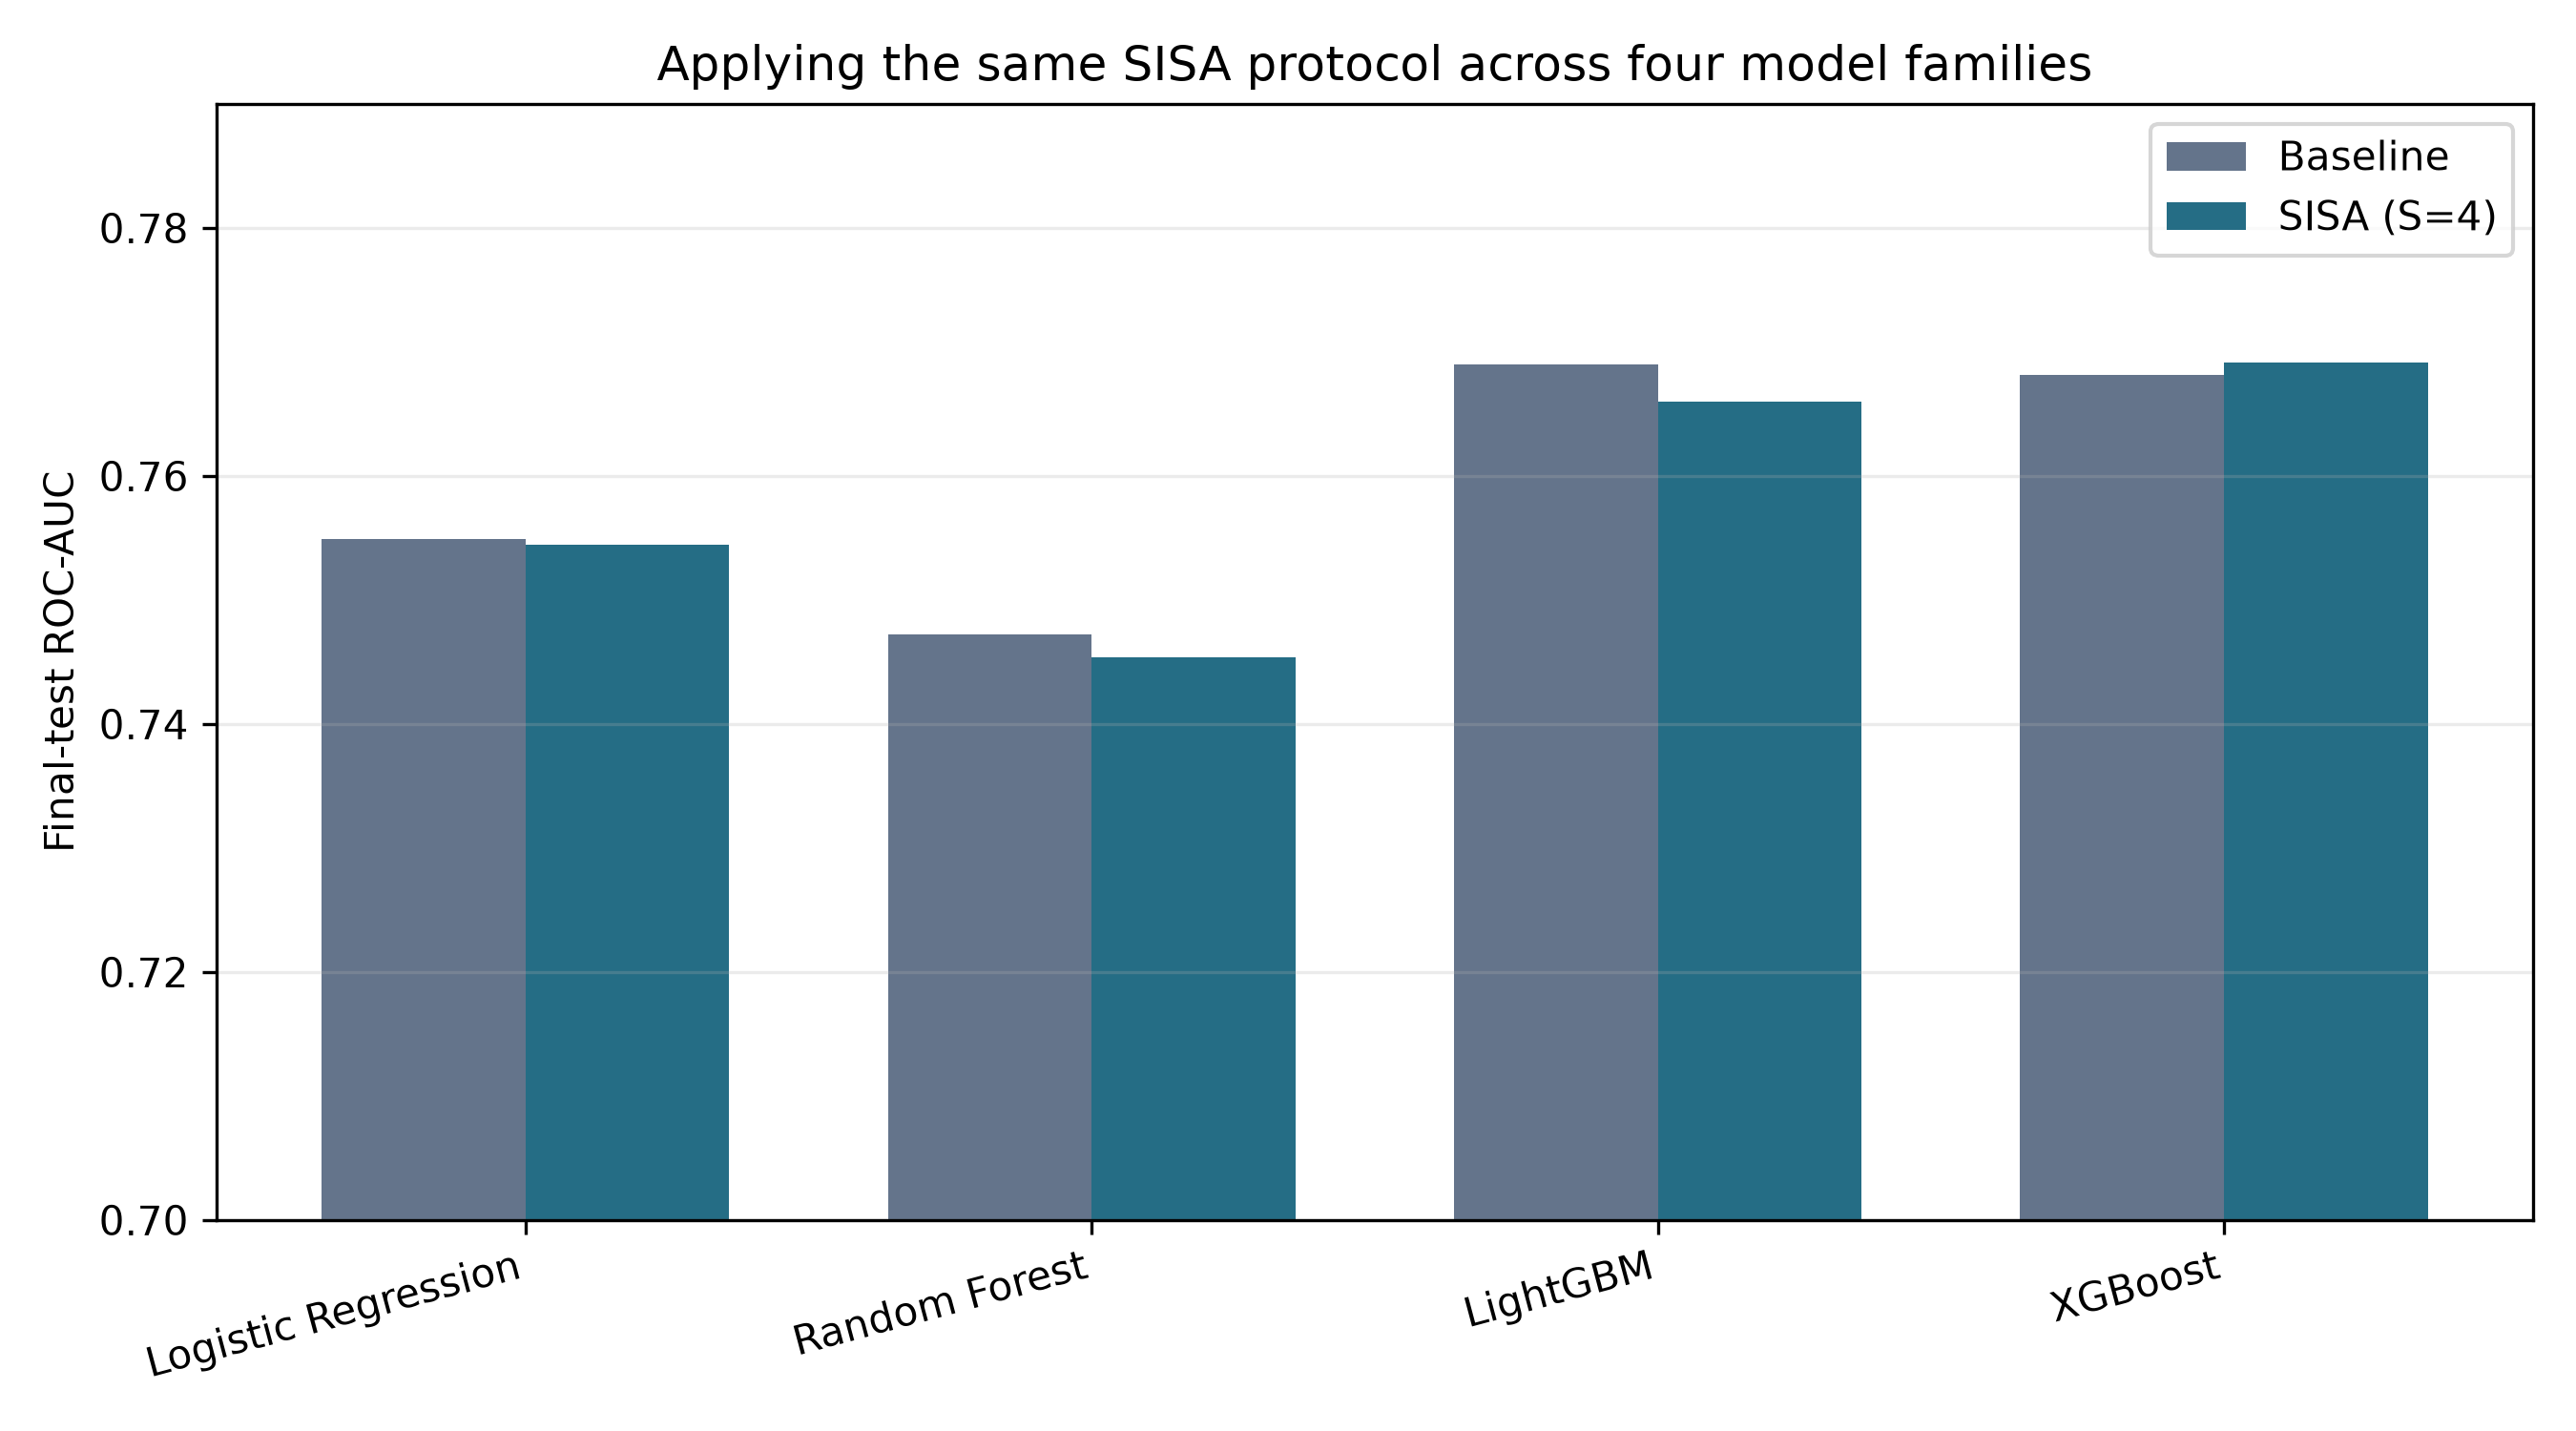

In [58]:
display(Image(filename=DIRS['figures'] / 'phase2_sisa_four_models.png'))

**Interpretation.** ภายใต้ protocol เดียวกัน SISA S=4 เปลี่ยน ROC-AUC อยู่ประมาณ −0.0030 ถึง +0.0010. หลักฐานรองรับ feasibility ข้ามทั้งสี่ families แต่ยังไม่ใช่หลักฐานว่า S=4 optimal สำหรับแต่ละ family.

### 4.2.1 Number of shards: utility–locality trade-off

In [59]:
shard_scalability_utility = pd.read_csv(DIRS['results'] / 'shard_count_scalability_extended.csv')
display(shard_scalability_utility[['shards', 'mean_rows_per_shard', 'min_rows_per_shard', 'max_rows_per_shard', 'roc_auc', 'average_precision', 'ks', 'brier', 'sisa_training_seconds', 'weighted_aggregation_seconds']].head(40))

,shards,mean_rows_per_shard,min_rows_per_shard,max_rows_per_shard,roc_auc,average_precision,ks,brier,sisa_training_seconds,weighted_aggregation_seconds
0,2,92252.500000,92252,92253,0.767791,0.259655,0.402579,0.067125,12.600352,0.000862
1,4,46126.250000,46125,46127,0.765968,0.254092,0.401034,0.067332,12.330813,0.000551
2,8,23063.125000,23062,23064,0.762574,0.250513,0.393742,0.067519,18.710777,0.000746
3,16,11531.562500,11530,11532,0.760228,0.247547,0.396226,0.067638,26.461368,0.001578
4,32,5765.781250,5765,5767,0.760952,0.247565,0.393062,0.067611,44.179180,0.001554
5,64,2882.890625,2882,2884,0.763510,0.250502,0.394206,0.067444,64.875998,0.002658
6,128,1441.445312,1441,1443,0.757137,0.243912,0.385988,0.067784,84.072131,0.004398


In [60]:
shard_scalability_workload = pd.read_csv(DIRS['results'] / 'shard_count_scalability_extended.csv')
display(shard_scalability_workload[['shards', 'single_record_affected_data_fraction', 'single_record_actual_retrained_fraction', 'localized_affected_shards', 'localized_affected_data_fraction', 'localized_actual_retrained_fraction', 'distributed_affected_shards', 'distributed_affected_data_fraction', 'distributed_actual_retrained_fraction']].head(40))

,shards,single_record_affected_data_fraction,single_record_actual_retrained_fraction,localized_affected_shards,localized_affected_data_fraction,localized_actual_retrained_fraction,distributed_affected_shards,distributed_affected_data_fraction,distributed_actual_retrained_fraction
0,2,0.499997,0.499995,1,0.499997,0.499495,2,1.000000,1.000000
1,4,0.249993,0.249989,1,0.249993,0.249240,4,1.000000,1.000000
2,8,0.124999,0.124995,1,0.124999,0.124121,8,1.000000,1.000000
3,16,0.062502,0.062497,1,0.062502,0.061561,16,1.000000,1.000000
4,32,0.031257,0.031251,1,0.031257,0.030284,32,1.000000,1.000000
5,64,0.015626,0.015620,1,0.015626,0.014638,59,0.921872,0.921794
6,128,0.007816,0.007810,1,0.007816,0.006820,101,0.789068,0.788856


In [61]:
expected_s = [2,4,8,16,32,64,128]
assert shard_scalability_utility['shards'].tolist() == expected_s
old = pd.read_csv(DIRS['results'] / 'shard_count_performance.csv').set_index('shards')
new = shard_scalability_utility.set_index('shards')
for s in [2,4,8,16]:
    assert np.isclose(old.loc[s,'roc_auc'], new.loc[s,'roc_auc'], atol=1e-12)
    assert np.isclose(old.loc[s,'average_precision'], new.loc[s,'average_precision'], atol=1e-12)
print('S=2/4/8/16 compatible; S=32/64/128 present; no optimal-S selection performed.')

S=2/4/8/16 compatible; S=32/64/128 present; no optimal-S selection performed.


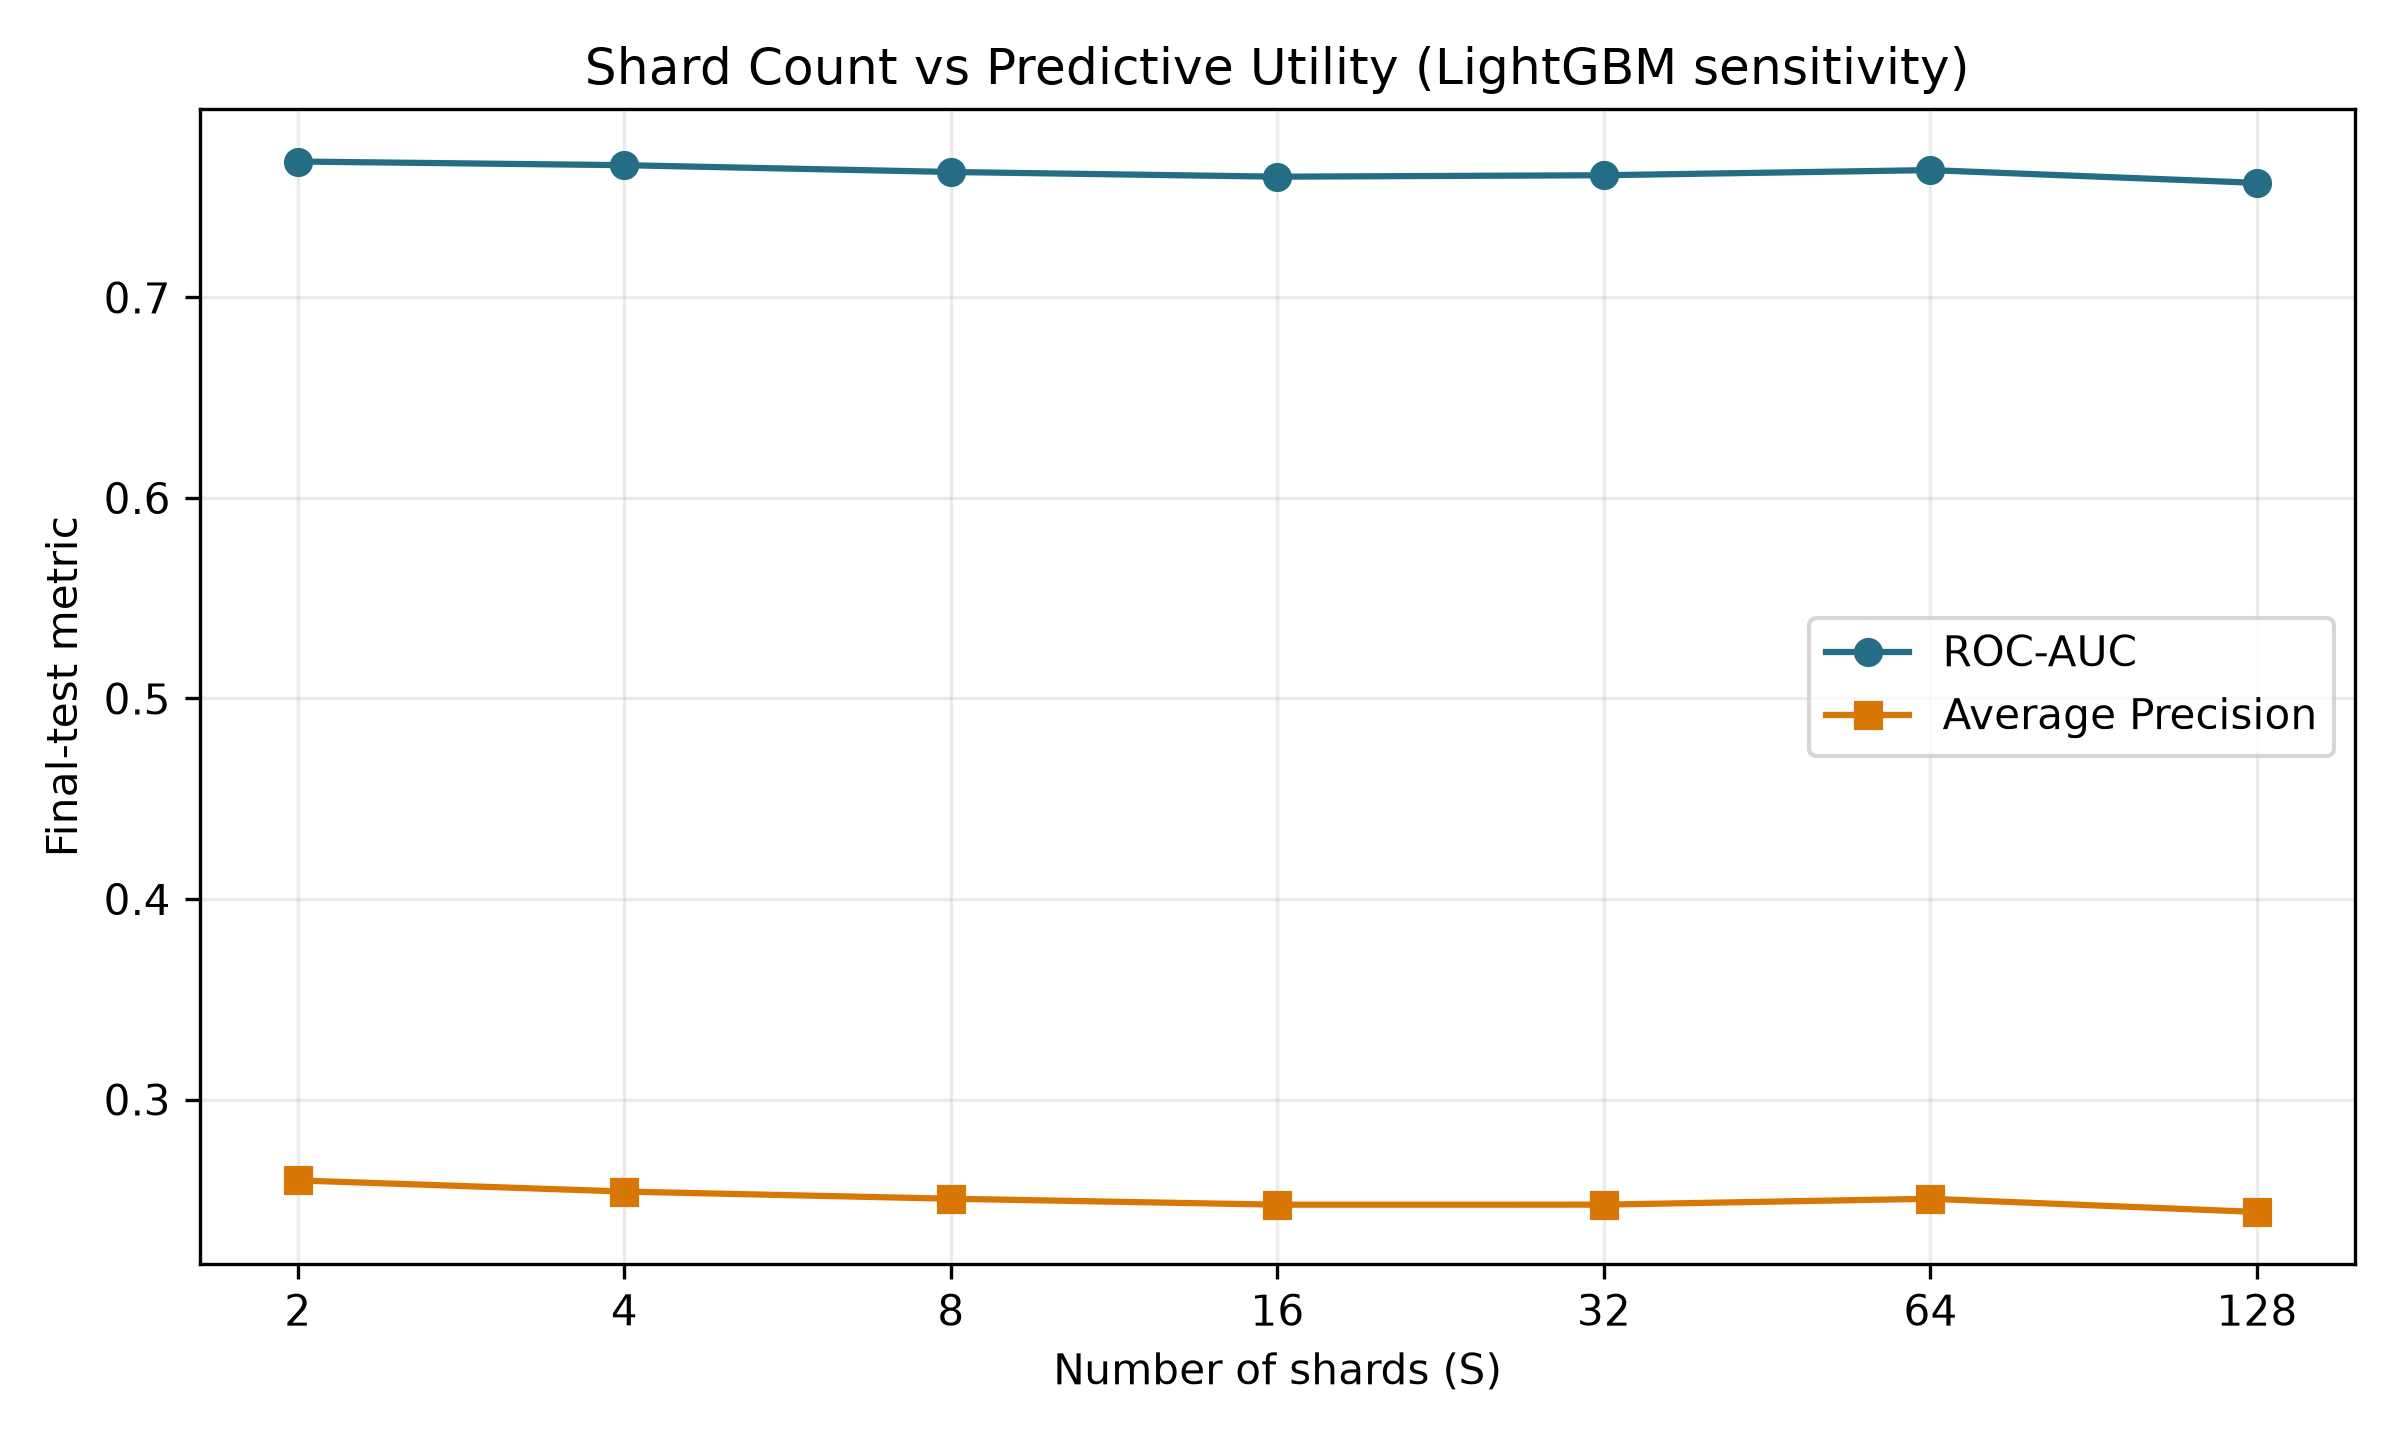

In [62]:
display(Image(filename=DIRS['figures'] / 'shard_count_vs_predictive_utility.png'))

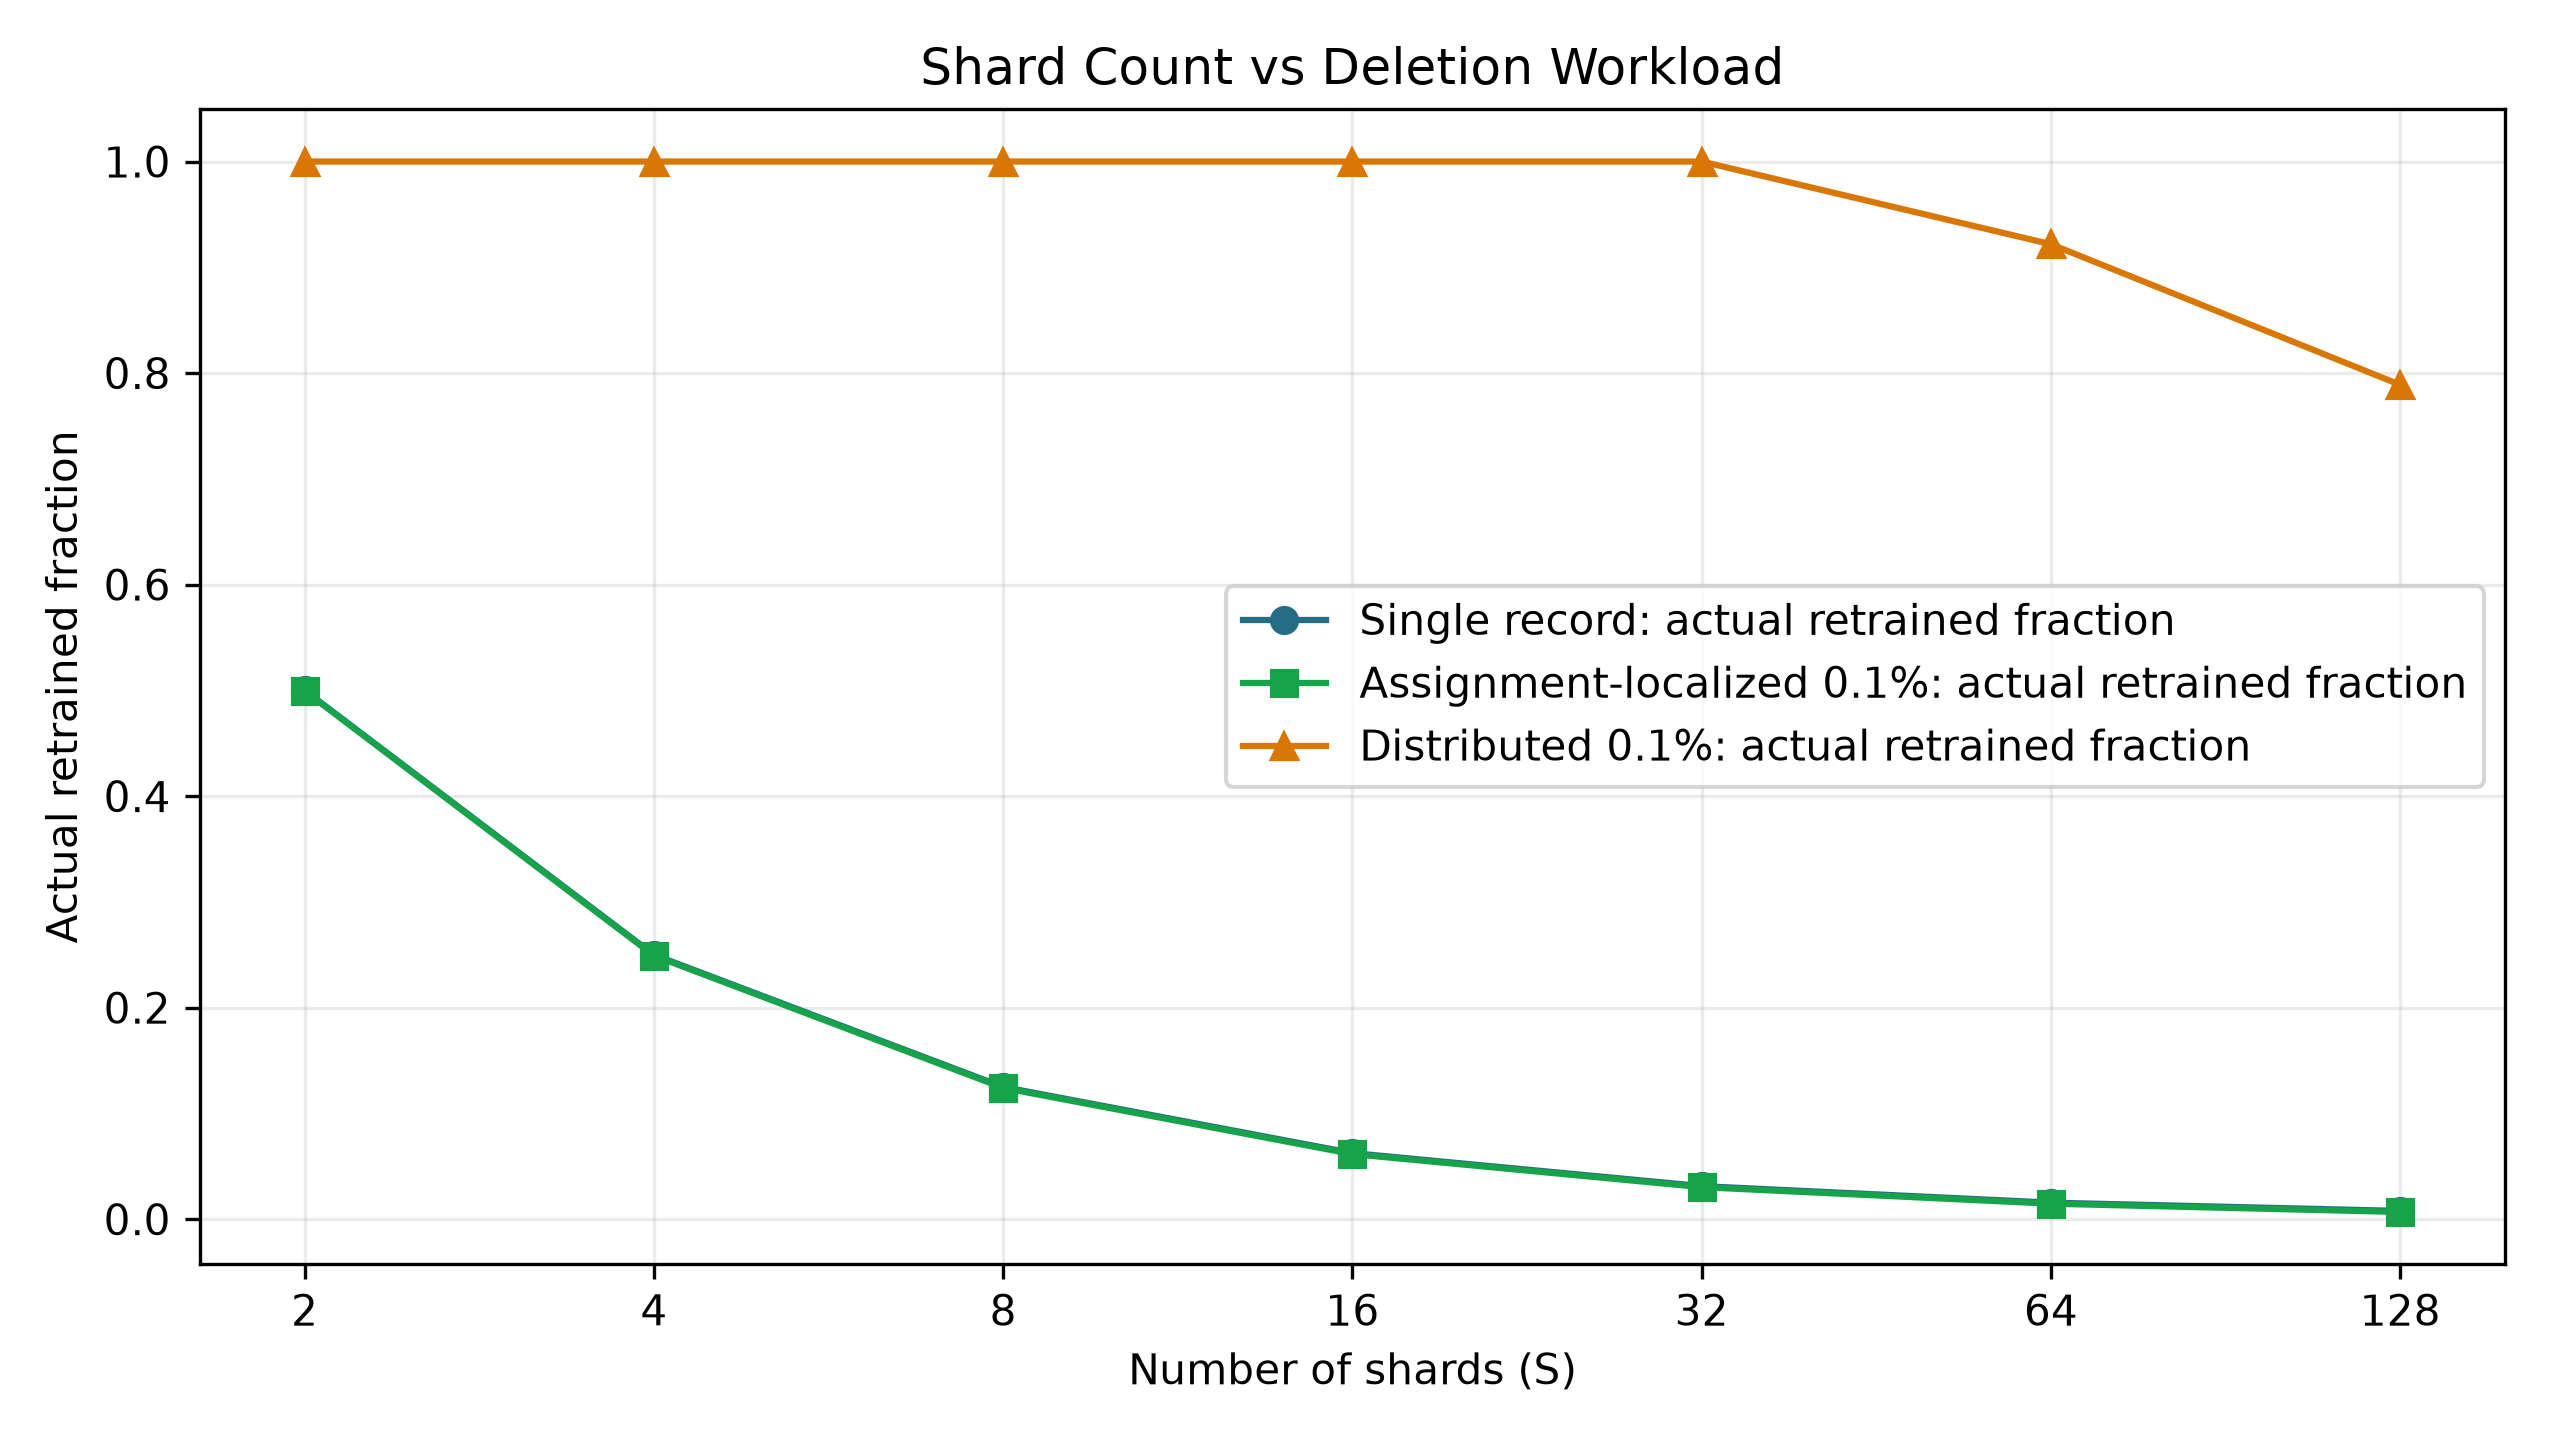

In [63]:
display(Image(filename=DIRS['figures'] / 'shard_count_vs_deletion_workload.png'))

**Interpretation.** Finer partitions reduce single-record and assignment-localized actual retraining fractions, while distributed requests can still touch most or all models. Utility is non-monotonic across S and drops most clearly at S=128; model-management and ensemble-prediction overhead increase with shard count. ผลนี้เป็น sensitivity analysis ไม่ใช่การเลือก S ที่ดีที่สุด.

### 4.2.2 Controlled strategy comparison and practical aggregation

#### Controlled assignment-only comparison

In [64]:
controlled_sharding = pd.read_csv(DIRS['results'] / 'expanded_controlled_sharding.csv')
display(controlled_sharding.head(40))

,strategy,comparison_layer,aggregation,roc_auc,average_precision,ks,brier,total_fit_seconds,size_cv,class_rate_sd
0,stratified_balanced,controlled,retained-size weighted probability + Platt cal...,0.765968,0.254092,0.401034,0.067332,12.116265,0.000018,0.000011
1,random_balanced,controlled,retained-size weighted probability + Platt cal...,0.766113,0.254821,0.401932,0.067298,12.527306,0.000009,0.000904
2,representative,controlled,retained-size weighted probability + Platt cal...,0.766435,0.255725,0.405010,0.067278,9.950381,0.000009,0.001159
3,specialist,controlled,retained-size weighted probability + Platt cal...,0.765861,0.257348,0.401052,0.067229,13.337370,0.000009,0.003925
4,risk_band,controlled,retained-size weighted probability + Platt cal...,0.695504,0.173674,0.285560,0.071065,10.292106,0.000009,0.081026


#### Practical learned aggregation

In [65]:
practical_sharding = pd.read_csv(DIRS['results'] / 'practical_sharding_architectures.csv')
display(practical_sharding.head(40))

,strategy,comparison_layer,aggregation,roc_auc,average_precision,ks,brier,total_fit_seconds,size_cv,class_rate_sd
0,specialist,practical,learned logistic meta-aggregator + held-out Pl...,0.765853,0.256136,0.401891,0.067367,13.337370,0.000009,0.003925
1,risk_band,practical,learned logistic meta-aggregator + held-out Pl...,0.753196,0.251738,0.385148,0.067553,10.292106,0.000009,0.081026


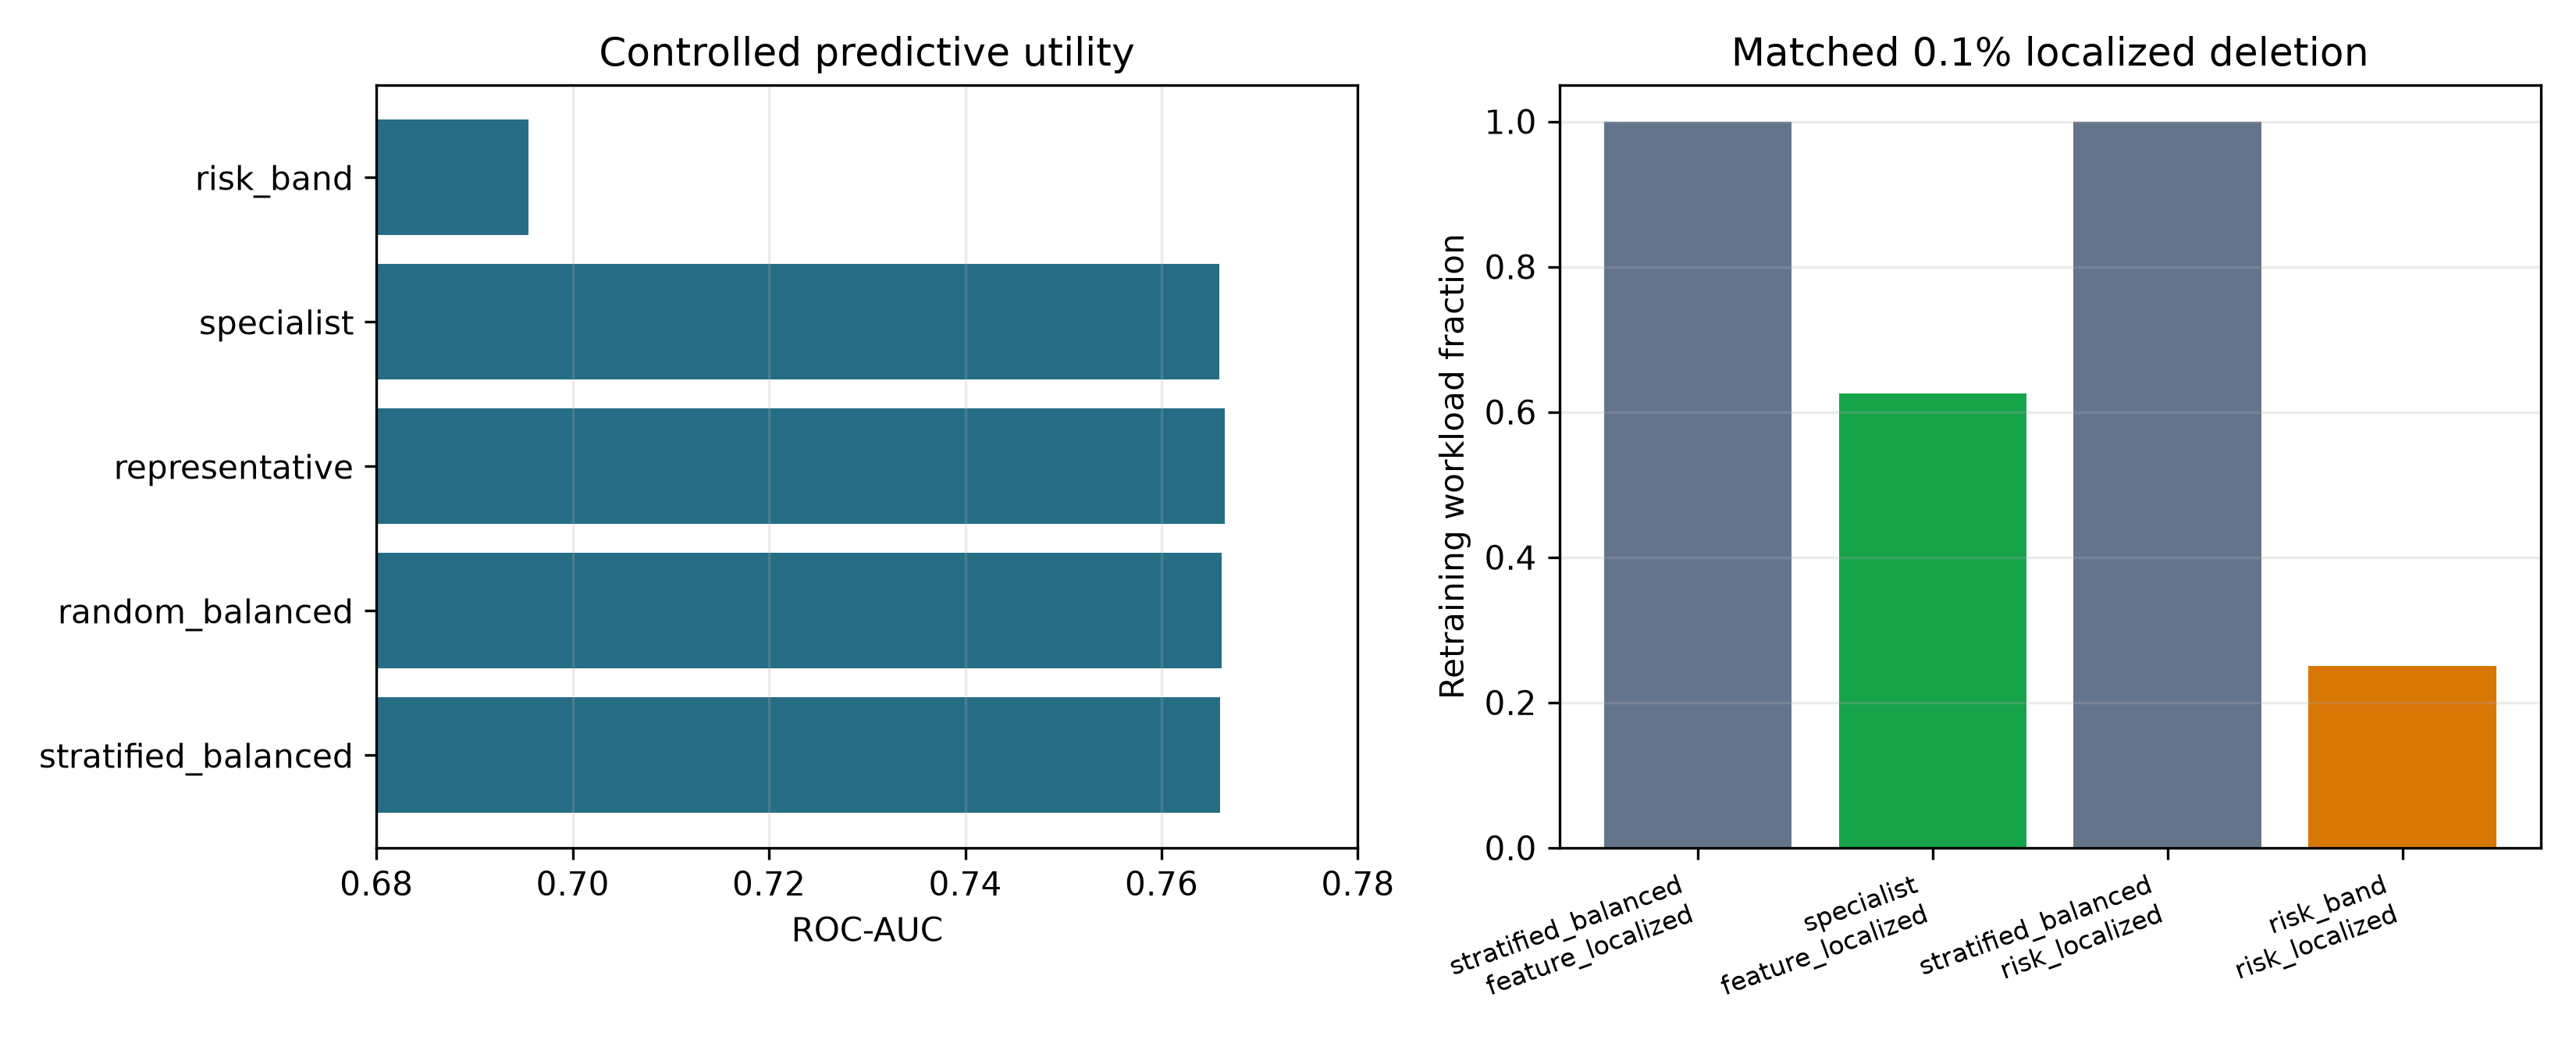

In [66]:
display(Image(filename=DIRS['figures'] / 'phase2_sharding_utility_locality.png'))

**Interpretation.** Stratified/random/representative/specialist มี utility ใกล้กันภายใต้ simple controlled aggregation. Risk-band AUC เหลือประมาณ 0.696 เพราะ shard priors ต่างกันมาก; learned meta-aggregation กู้ขึ้นถึงประมาณ 0.753 แต่ยังต่ำกว่า stratified. ข้อค้นพบคือ risk grouping ให้ locality สูงสำหรับ matched requests โดยแลก utility และต้องออกแบบ aggregation ให้เหมาะ.

## 4.3 Deletion Locality Results

### Primary controlled deletion scenarios

In [67]:
distributed_scale = pd.read_csv(DIRS['results'] / 'distributed_deletion_scale_summary.csv')
display(distributed_scale.head(40))

,deletion_size,affected_fraction_mean,workload_mean
0,single,0.25,0.250002
1,0.01%,1.00,1.000000
2,0.1%,1.00,1.000000
3,1%,1.00,1.000000


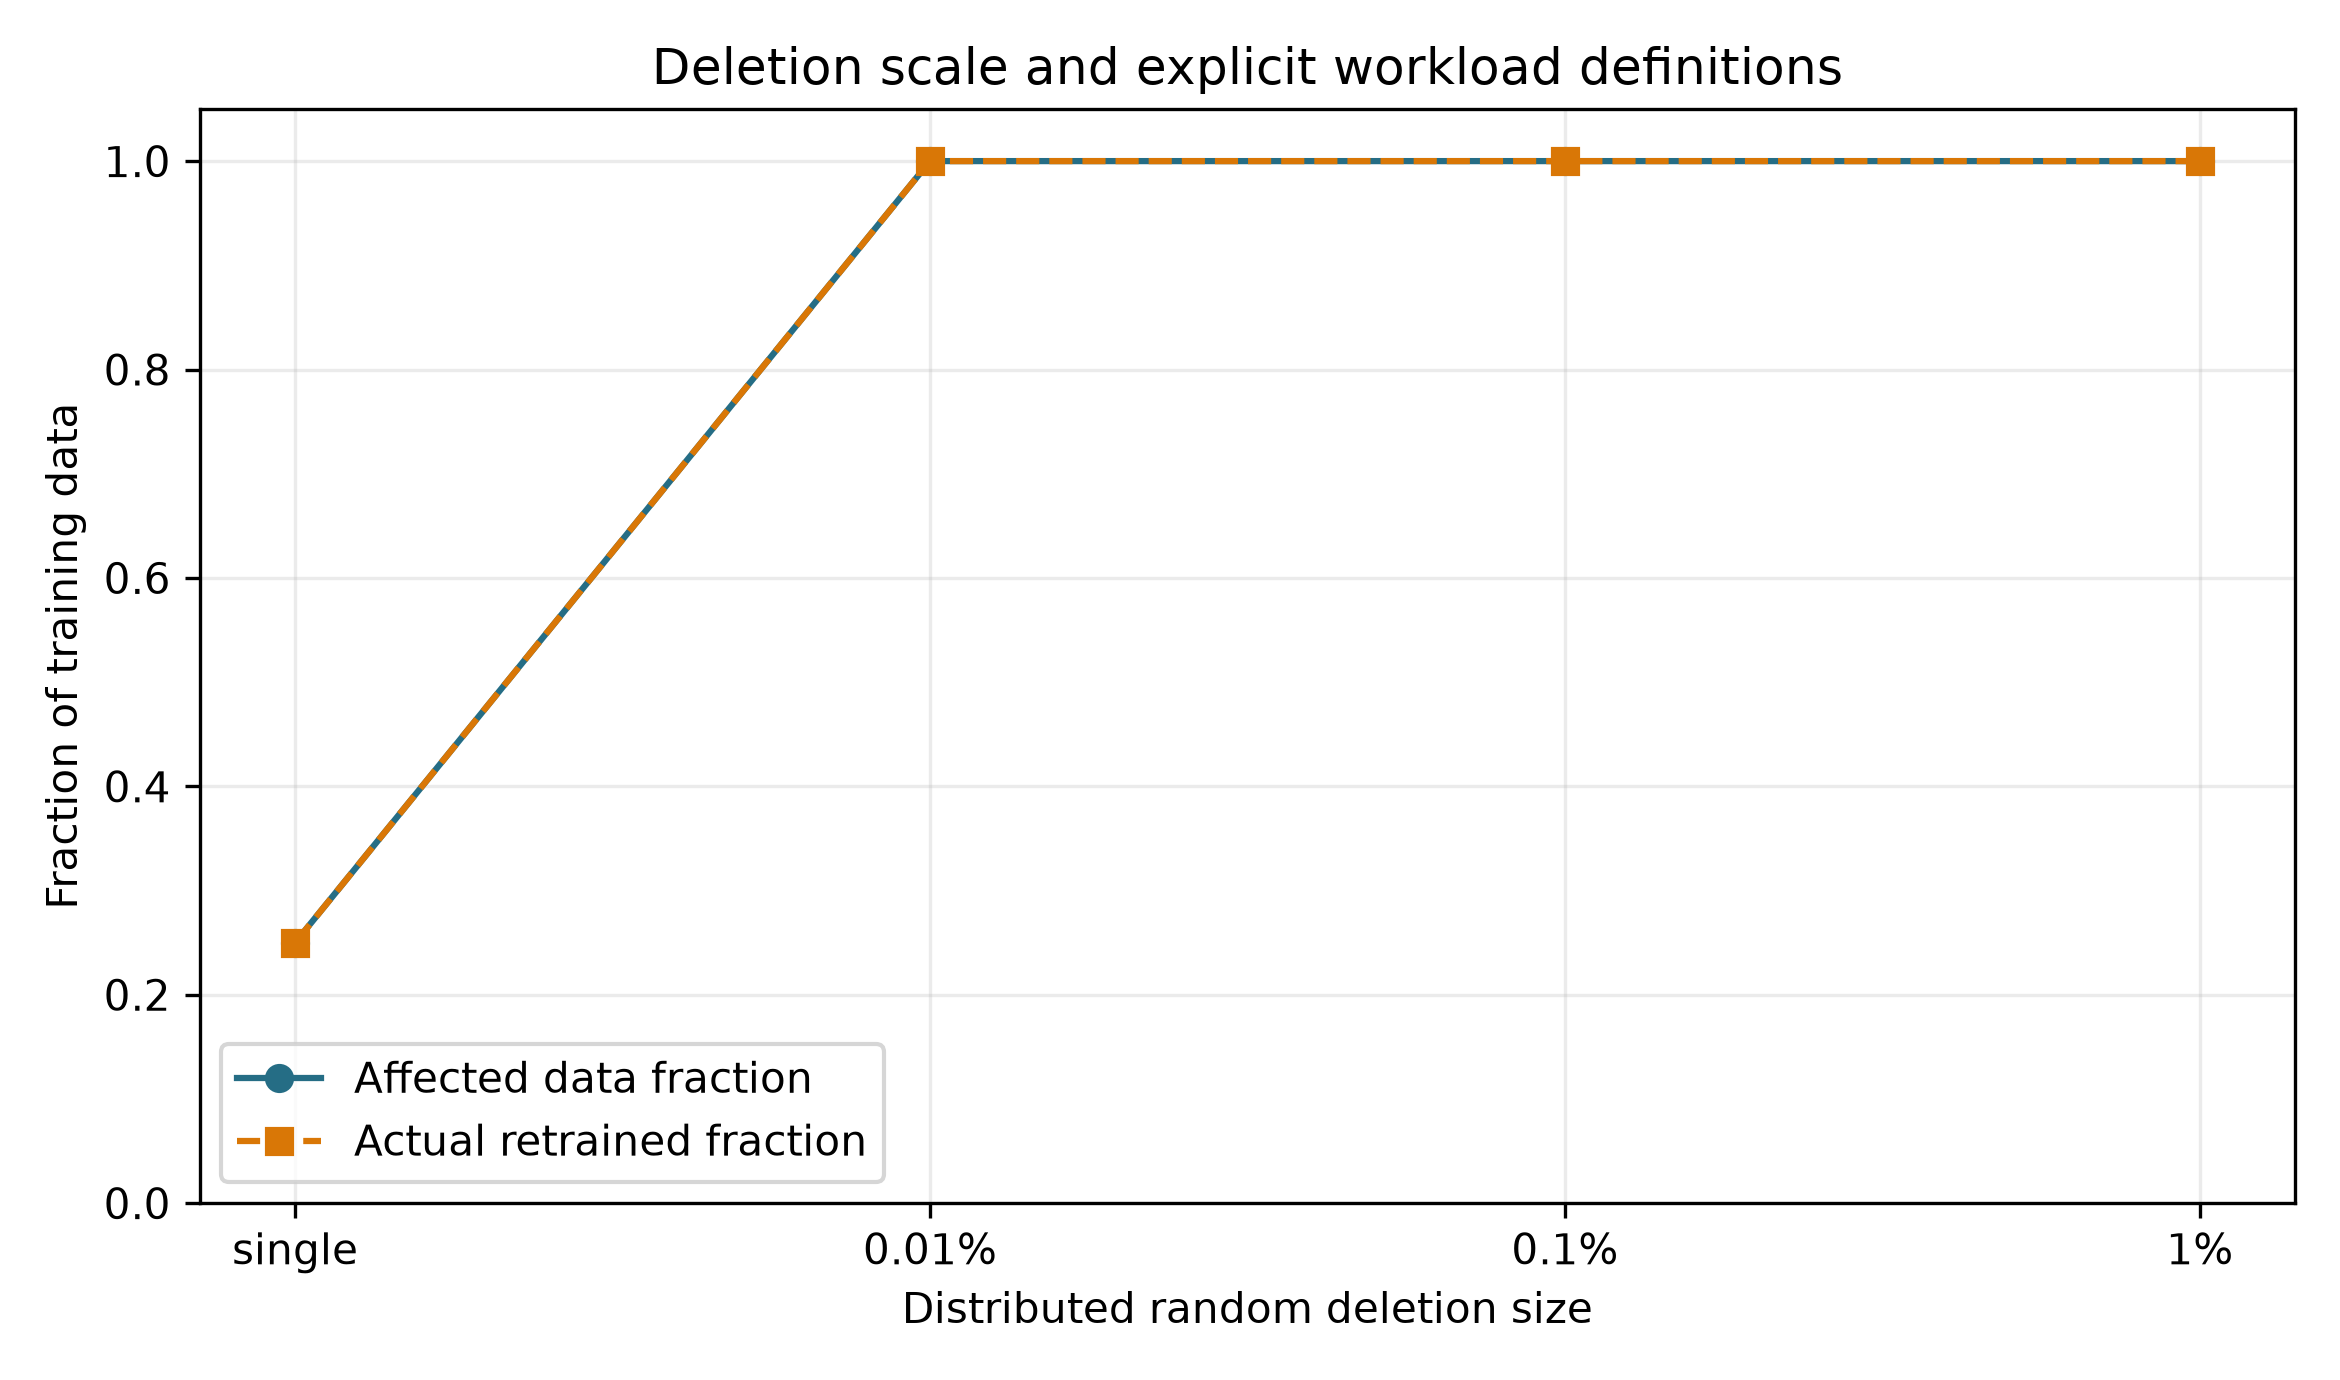

In [68]:
display(Image(filename=DIRS['figures'] / 'phase2_deletion_scale.png'))

In [69]:
matched_locality = pd.read_csv(DIRS['results'] / 'deletion_scale_locality_summary_explicit.csv').query("deletion_size == '0.1%' and ((strategy == 'stratified_balanced' and pattern in ['feature_localized','risk_localized']) or (strategy == 'specialist' and pattern == 'feature_localized') or (strategy == 'risk_band' and pattern == 'risk_localized'))")
display(matched_locality[['deletion_size', 'pattern', 'strategy', 'affected_shards_mean', 'affected_data_fraction_mean', 'actual_retrained_fraction_mean']])

,deletion_size,pattern,strategy,affected_shards_mean,affected_data_fraction_mean,actual_retrained_fraction_mean
23,0.1%,feature_localized,specialist,2.5,0.625000,0.624624
24,0.1%,feature_localized,stratified_balanced,4.0,1.000000,1.000000
27,0.1%,risk_localized,risk_band,1.0,0.250001,0.249248
29,0.1%,risk_localized,stratified_balanced,4.0,1.000000,1.000000


In [70]:
locality_statistics = pd.read_csv(DIRS['results'] / 'deletion_locality_statistics.csv')
display(locality_statistics.head(40))

,comparison,paired_n,mean_workload_difference,ci95_low,ci95_high,wilcoxon_statistic,one_sided_p_value,metric_definition
0,specialist vs stratified for feature_localized,10,-0.375000,-0.600000,-0.150000,0.0,0.031250,paired difference in affected_data_fraction
1,risk_band vs stratified for risk_localized,10,-0.749999,-0.750001,-0.749998,0.0,0.000977,paired difference in affected_data_fraction


**Interpretation.** Distributed requests ขนาด 0.01% ขึ้นไปแตะเกือบ/ครบทุก S=4 shards จึงทำให้ทั้ง affected-data และ actual-retrained fractions เข้าใกล้ 1. สถิติ legacy `mean_workload_difference` ในตารางนี้หมายถึงความต่างของ **affected_data_fraction**: Specialist ลดลงเฉลี่ยประมาณ 0.375 สำหรับ feature-localized และ Risk-Band ลดประมาณ 0.75 สำหรับ risk-localized. ข้ออ้างจำกัดอยู่ที่ paired n=10 design.

### 4.3.1 Supplementary Policy-Aware / Company-Aware Relationship Case Study

In [71]:
policy_structure_result = pd.read_csv(DIRS['results'] / 'policy_nested_summary.csv')
display(policy_structure_result.head(40))

,extension,base_sharding,relationship_layer,deletion_policy,balance_tolerance,maximum_moved_fraction,customers,customers_moved,customers_moved_fraction,specialist_assignment_preservation,assignment_adjusted_rand_index,base_mean_dominant_feature_cluster_share,nested_mean_dominant_feature_cluster_share,dominant_feature_cluster_share_change,relationships_improved,relationships_worsened,mean_strict_spread_before,mean_strict_spread_after,max_abs_default_rate_change
0,Policy-Aware / Company-Aware Nested Specialist,Specialist,synthetic company mapping,strict,0.05,0.1,184505,18450,0.099997,0.900003,0.752324,0.802098,0.797373,-0.004725,23,0,4.0,3.896552,0.00292


In [72]:
policy_locality_summary = pd.read_csv(DIRS['results'] / 'policy_deletion_locality_summary.csv')
display(policy_locality_summary.head(40))

,assignment,scenarios,affected_shards_mean,affected_data_fraction_mean,actual_retrained_fraction_mean,actual_retrained_fraction_sd,locality_mean
0,Specialist + policy-aware nested mapping,10,3.3,0.823992,0.821257,0.318612,0.233333
1,Specialist baseline,10,4.0,1.000000,1.000000,0.000000,0.000000


In [73]:
policy_per_relationship = pd.read_csv(DIRS['results'] / 'policy_deletion_per_relationship.csv')
display(policy_per_relationship.head(20))

,scenario,relationship,policy,deleted_customers,policy_aware_affected_shards,specialist_affected_shards,policy_aware_affected_data_fraction,specialist_affected_data_fraction,policy_aware_actual_retrained_fraction,specialist_actual_retrained_fraction,workload_improved,estimated_speedup_vs_specialist
0,0,Business Entity Type 3__SyntheticCompany_02,strict,2860,1.0,4.0,0.239923,1.0,0.227956,1.0,yes,4.386819
1,1,Business Entity Type 3__SyntheticCompany_05,strict,2857,4.0,4.0,1.000000,1.0,1.000000,1.0,no,1.000000
2,2,Business Entity Type 3__SyntheticCompany_12,strict,2853,4.0,4.0,1.000000,1.0,1.000000,1.0,no,1.000000
3,3,Business Entity Type 3__SyntheticCompany_07,strict,2828,4.0,4.0,1.000000,1.0,1.000000,1.0,no,1.000000
4,4,Business Entity Type 3__SyntheticCompany_09,strict,2810,4.0,4.0,1.000000,1.0,1.000000,1.0,no,1.000000
5,5,Business Entity Type 3__SyntheticCompany_11,strict,2800,1.0,4.0,0.257223,1.0,0.245777,1.0,yes,4.068721
6,6,Business Entity Type 3__SyntheticCompany_08,strict,2786,3.0,4.0,0.742777,1.0,0.738833,1.0,yes,1.353486
7,7,Business Entity Type 3__SyntheticCompany_04,strict,2782,4.0,4.0,1.000000,1.0,1.000000,1.0,no,1.000000
8,8,Business Entity Type 3__SyntheticCompany_10,strict,2769,4.0,4.0,1.000000,1.0,1.000000,1.0,no,1.000000
9,9,Business Entity Type 3__SyntheticCompany_06,strict,2765,4.0,4.0,1.000000,1.0,1.000000,1.0,no,1.000000


In [74]:
policy_utility = pd.read_csv(DIRS['results'] / 'policy_nested_utility.csv')
display(policy_utility.head(40))

,assignment,roc_auc,average_precision,ks,brier,aggregation,total_fit_seconds,roc_auc_delta_vs_specialist,average_precision_delta_vs_specialist,ks_delta_vs_specialist,brier_delta_vs_specialist
0,Specialist baseline,0.765861,0.257348,0.401052,0.067229,retained-size weighted probability + Platt cal...,13.337370,0.000000,0.000000,0.000000,0.000000
1,Specialist + policy-aware nested mapping,0.764195,0.255682,0.397465,0.067336,retained-size weighted probability + Platt cal...,31.511783,-0.001665,-0.001666,-0.003587,0.000108


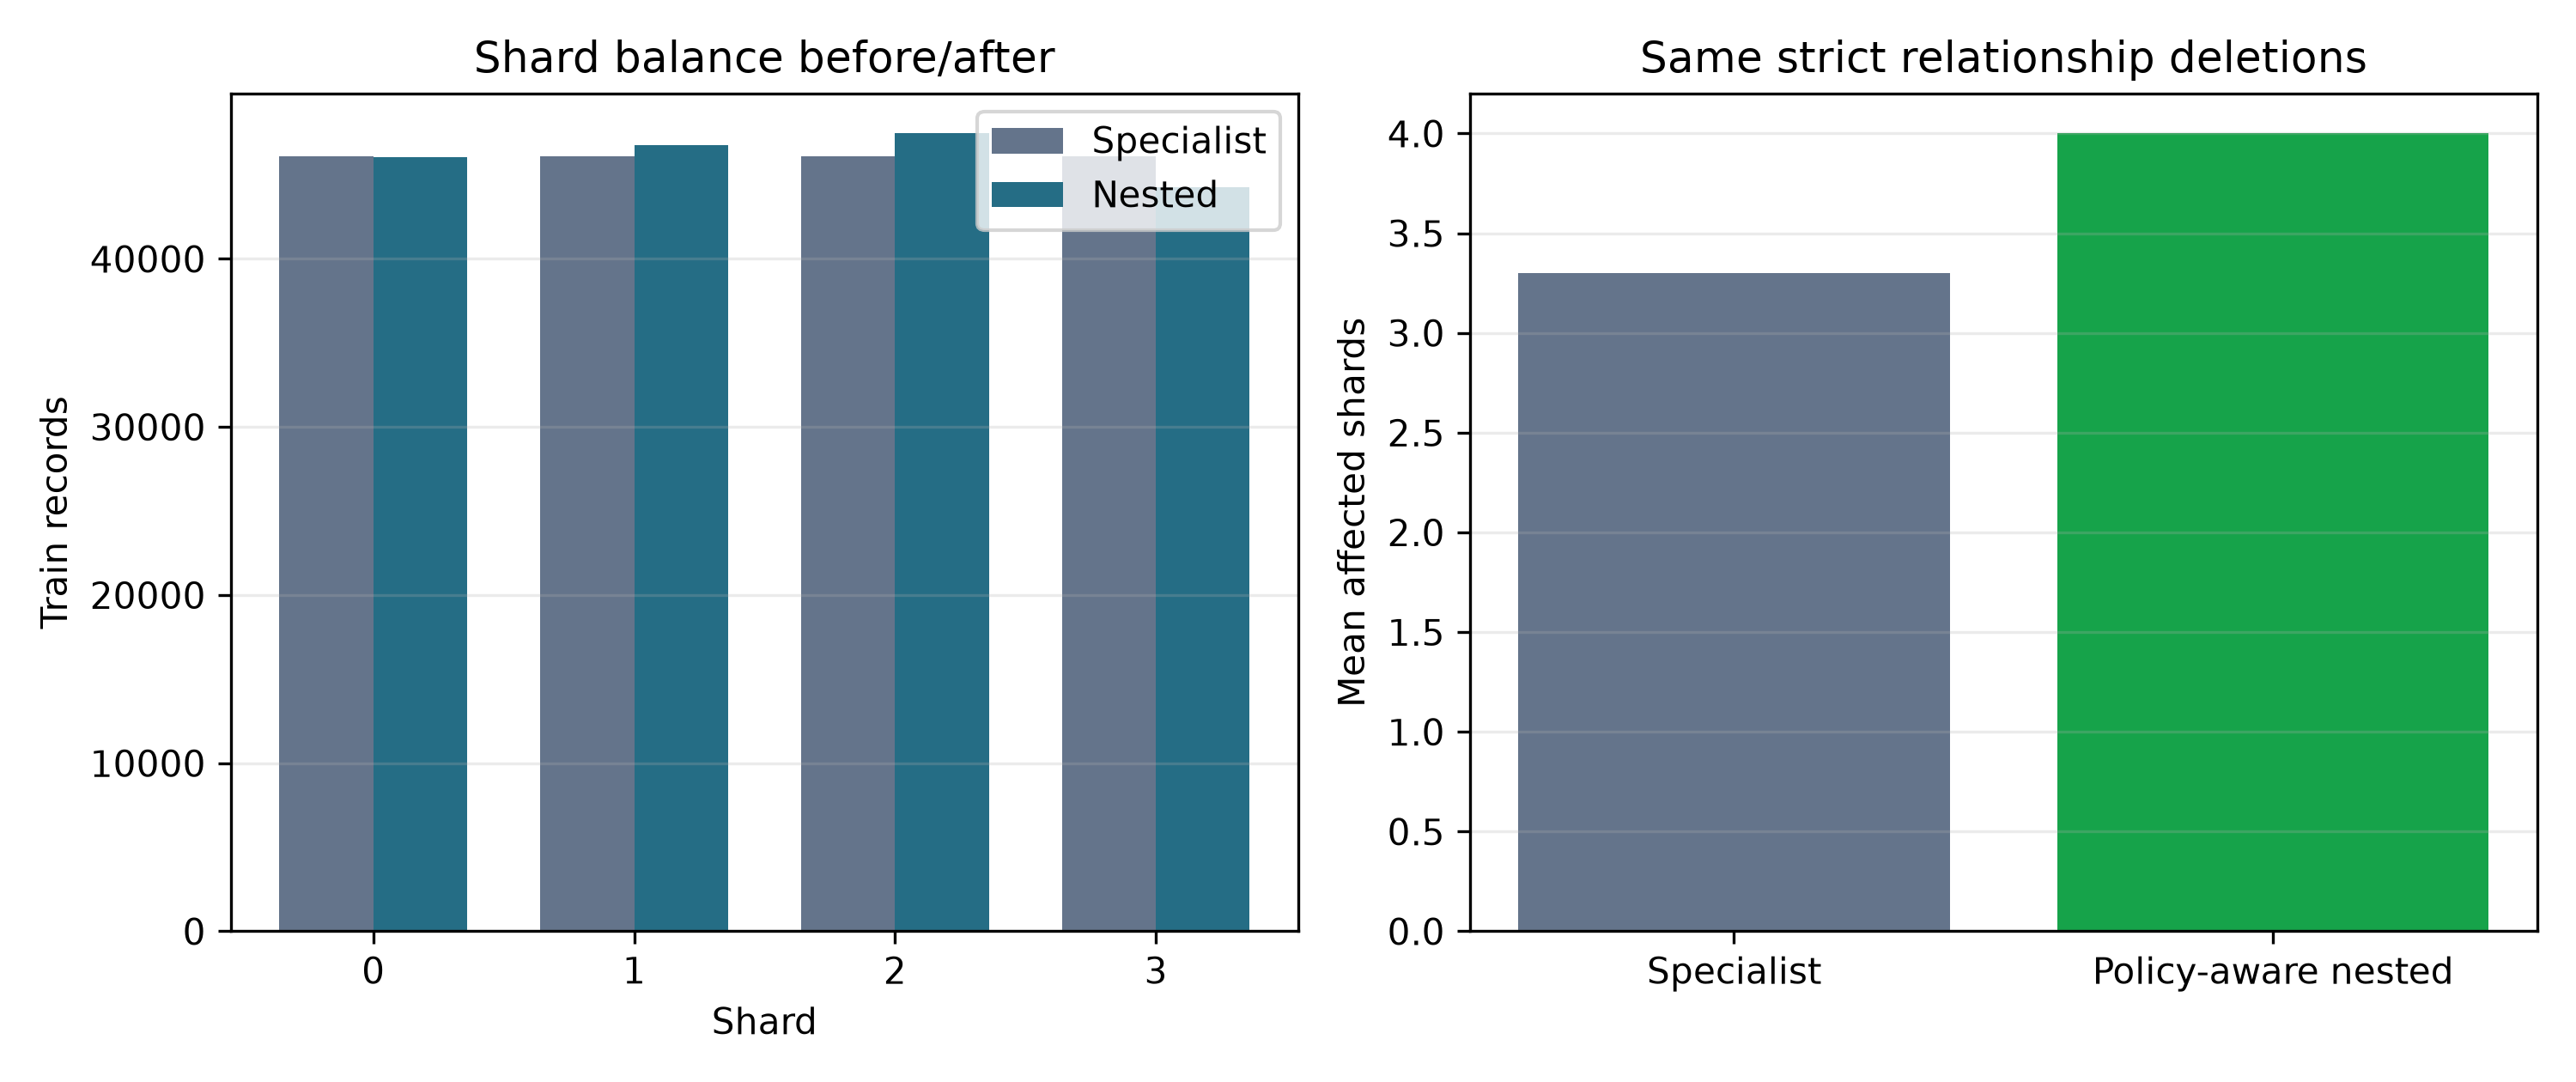

In [75]:
display(Image(filename=DIRS['figures'] / 'policy_nested_specialist_results.png'))

**Artifact-derived interpretation.** Mapping ครบ corrected train 184,505 IDs; 151,289 รายมี relationship เดียวและ 33,216 รายมีสอง relationshipsใน synthetic scenario. Nested optimization ใช้ movement budget เต็มเกือบ 10% ทำให้คง original Specialist assignment 90.0% (ARI≈0.752), ไม่มี relationship ใด fragmented มากขึ้น และ dominant feature-cluster share ลดเพียงประมาณ 0.0047.

สำหรับ strict deletion targets 10 บริษัทเดียวกัน Specialist baseline กระทบ 4 shards ทุกครั้ง; nested assignment เฉลี่ย 3.3 shards และ mean **actual retrained fraction** ลดจาก 1.000 เป็นประมาณ 0.821. ตาราง per-relationship แสดงครบทั้งกรณีที่ดีขึ้นมากและกรณีไม่ดีขึ้น. ROC-AUC ลดเล็กน้อย จึงเป็น **configurability/workload trade-off ที่สร้างโดยตั้งใจ** ไม่ใช่หลักฐานว่า company-aware mapping เหนือกว่าโดยทั่วไปหรือเหมาะกับธนาคารจริงทุกแห่ง.

## 4.4 Gold-Standard Fidelity Results

### 4.4.1 Direct Deletion Audit

In [76]:
result_deletion_audit = pd.read_csv(DIRS['results'] / 'direct_deletion_audit.csv')
display(result_deletion_audit.head(40))

,model,SK_ID_CURR,assigned_shard,present_before,present_in_exact_training,present_in_gold_training,affected_shard_rows_before,affected_shard_rows_after,audit_status
0,Logistic Regression,100008,0,1,0,0,46127,46126,PASS
1,Random Forest,100008,0,1,0,0,46127,46126,PASS
2,LightGBM,100008,0,1,0,0,46127,46126,PASS
3,XGBoost,100008,0,1,0,0,46127,46126,PASS


### 4.4.2 Model Fidelity

In [77]:
detailed_fidelity = pd.read_csv(DIRS['results'] / 'fidelity_detailed_four_models.csv')
display(detailed_fidelity.head(40))

,model,scenario,exact_gold_mae,exact_gold_rmse,exact_gold_max_abs,exact_gold_correlation,exact_gold_auc_difference,exact_gold_ap_difference,exact_gold_decision_disagreement,original_exact_mae,original_exact_decision_change
0,Logistic Regression,single_record,0.000000e+00,0.000000e+00,0.000000e+00,1.0,0.0,0.0,0.0,0.000062,0.000260
1,Random Forest,single_record,3.373096e-18,1.834783e-17,4.440892e-16,1.0,0.0,0.0,0.0,0.002955,0.010059
2,LightGBM,single_record,0.000000e+00,0.000000e+00,0.000000e+00,1.0,0.0,0.0,0.0,0.003147,0.008932
3,XGBoost,single_record,0.000000e+00,0.000000e+00,0.000000e+00,1.0,0.0,0.0,0.0,0.003068,0.007328


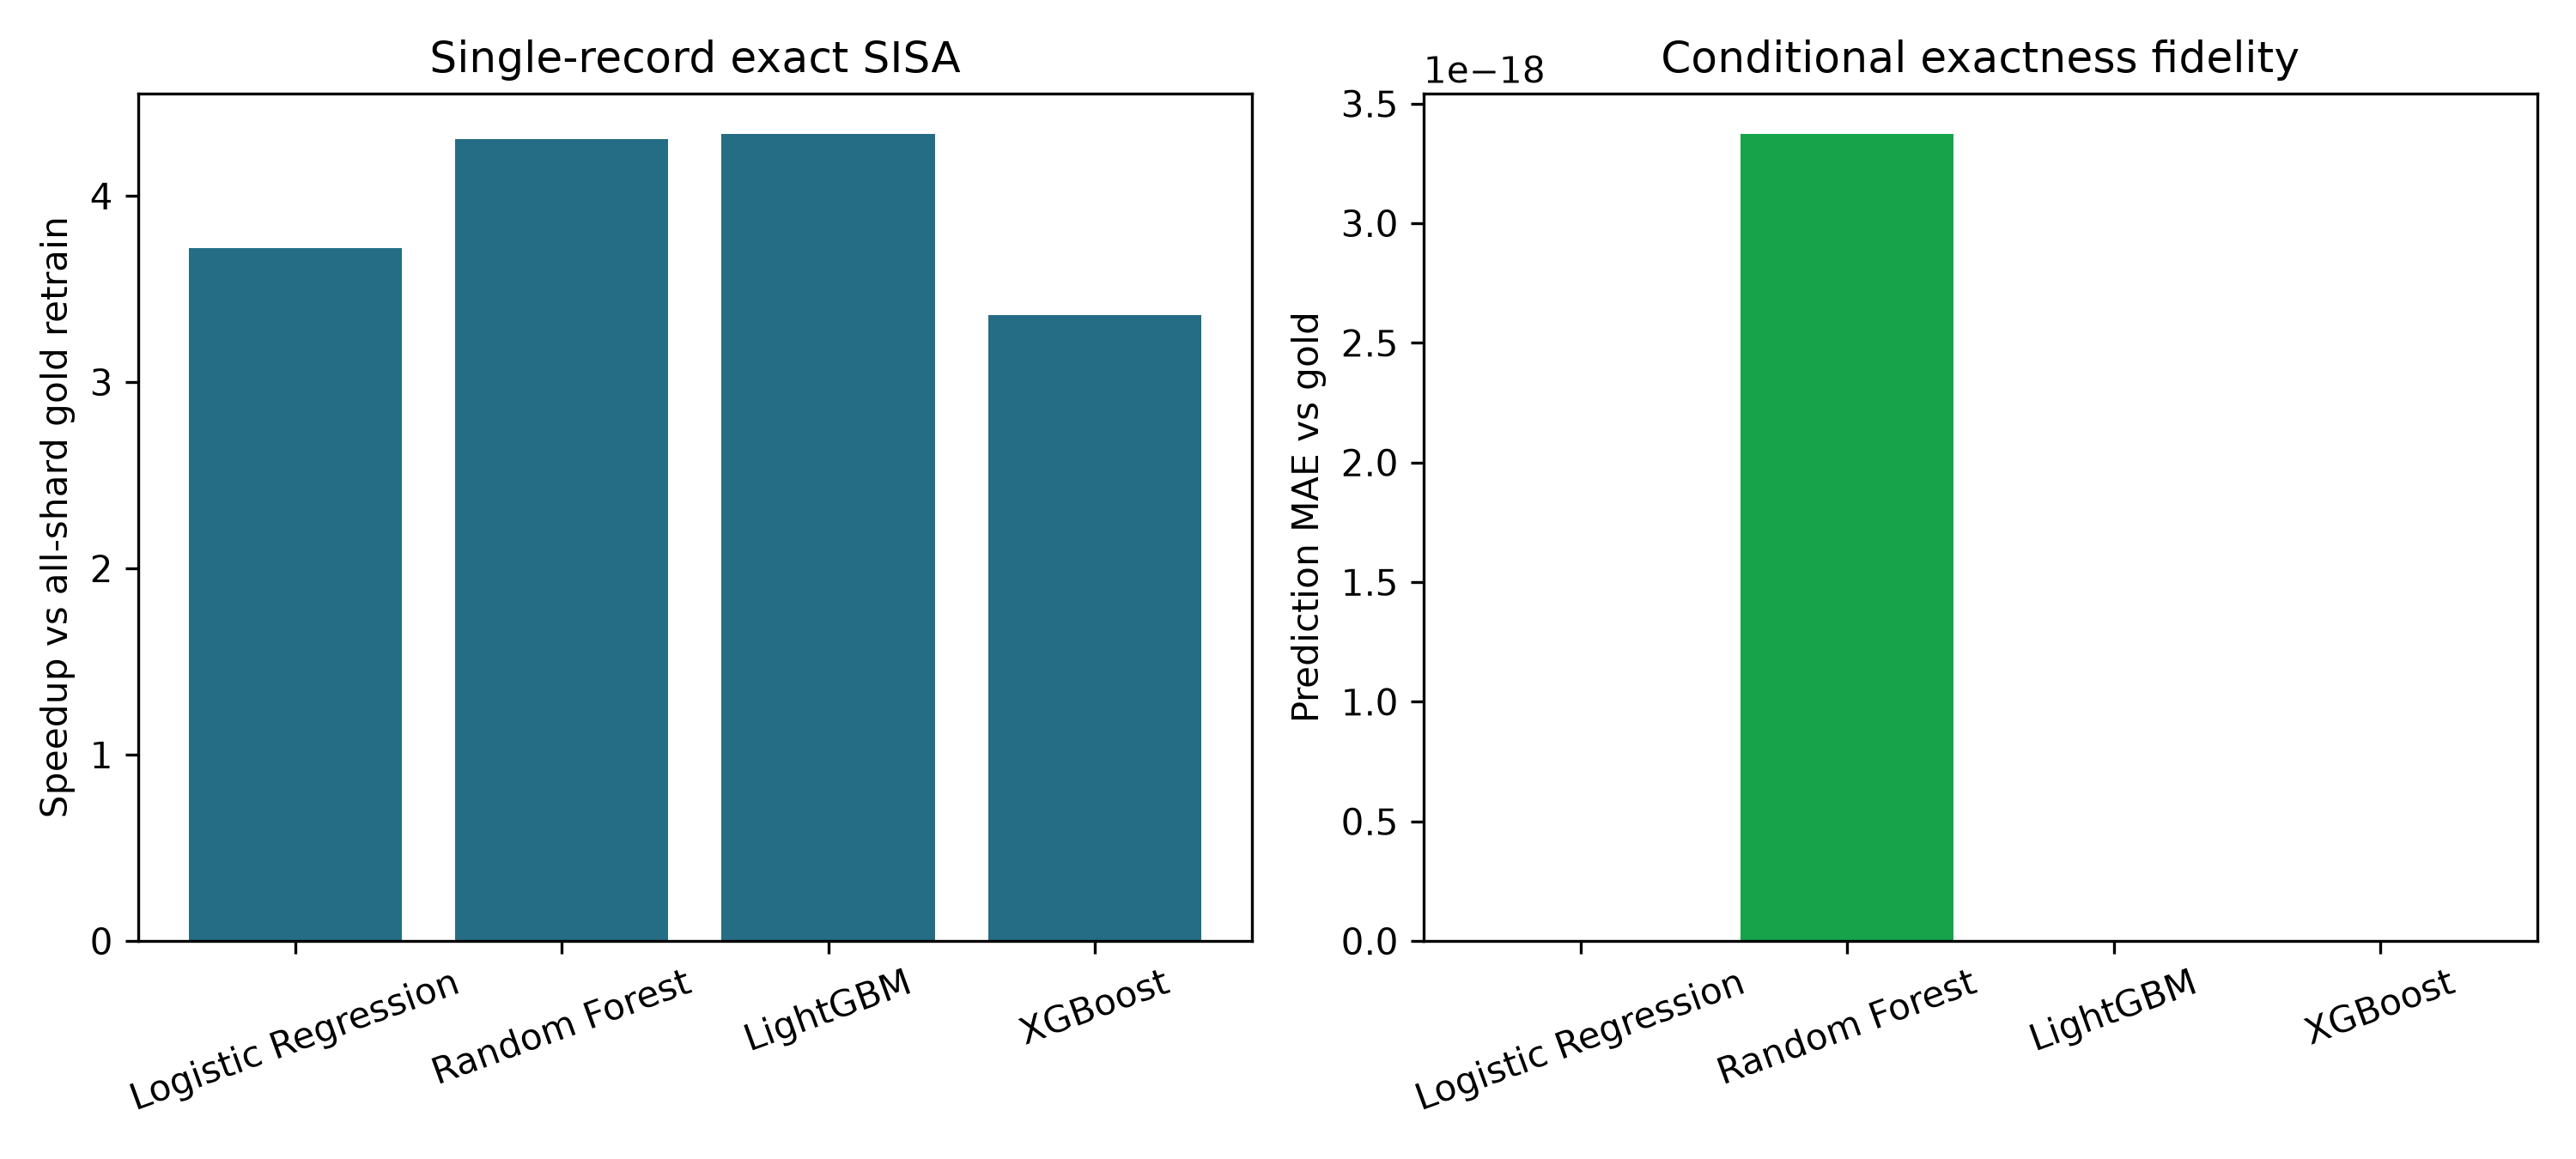

In [78]:
display(Image(filename=DIRS['figures'] / 'phase2_exact_four_models.png'))

### 4.4.3 Forget-set Behavior

In [79]:
forget_behavior = pd.read_csv(DIRS['results'] / 'forget_set_behavior_four_models.csv')
display(forget_behavior.head(40))

,model,SK_ID_CURR,target,threshold,original_probability,exact_probability,gold_probability,original_to_exact_change,exact_gold_absolute_difference,original_decision,exact_decision,gold_decision
0,Logistic Regression,100008,0,0.140,0.077738,0.077822,0.077822,0.000084,0.0,0,0,0
1,Random Forest,100008,0,0.130,0.115244,0.119730,0.119730,0.004486,0.0,0,0,0
2,LightGBM,100008,0,0.155,0.087604,0.084086,0.084086,-0.003517,0.0,0,0,0
3,XGBoost,100008,0,0.165,0.103105,0.102658,0.102658,-0.000447,0.0,0,0,0


**Interpretation.** Exact=gold บน deleted applicant เป็น implementation fidelity evidence ไม่ใช่ record-level privacy guarantee.

### 4.4.4 Cross-model Validation

In [80]:
exact_models = pd.read_csv(DIRS['results'] / 'exact_unlearning_four_models.csv')
display(exact_models.head(40))

,model,scenario,deleted_records,affected_shards,workload_fraction,exact_seconds,gold_seconds,speedup,prediction_mae,prediction_rmse,max_probability_difference,prediction_disagreement,exact_roc_auc,gold_roc_auc,affected_data_fraction,actual_retrained_fraction,legacy_workload_definition
0,Logistic Regression,single_record,1,1,0.25,3.927141,14.605070,3.719008,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.754475,0.754475,0.250004,0.25,workload_fraction approximated affected_data_f...
1,Random Forest,single_record,1,1,0.25,46.760358,201.316860,4.305289,3.373096e-18,1.834783e-17,4.440892e-16,0.0,0.745859,0.745859,0.250004,0.25,workload_fraction approximated affected_data_f...
2,LightGBM,single_record,1,1,0.25,2.694320,11.671968,4.332065,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.766285,0.766285,0.250004,0.25,workload_fraction approximated affected_data_f...
3,XGBoost,single_record,1,1,0.25,4.668463,15.691439,3.361157,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.769013,0.769013,0.250004,0.25,workload_fraction approximated affected_data_f...


**Interpretation.** Single localized deletion มี affected-data/actual-retrained fractions ใกล้ 1/4 และให้ measured speedup ราว 3.36–4.33×. Exact SISA ภายใต้ fixed protocol ตรงกับ protocol-compatible Gold ถึง numerical precision.

## 4.5 Exact vs Approximate Unlearning

### Correct slicing mechanism demonstration

In [81]:
slicing = pd.read_csv(DIRS['results'] / 'slicing_demonstration.csv')
display(slicing[['model', 'slices', 'earliest_affected_slice', 'replayed_fraction_of_affected_shard', 'replay_seconds', 'gold_all_shards_seconds', 'speedup_vs_gold', 'prediction_mae', 'exact_roc_auc']].head(40))

,model,slices,earliest_affected_slice,replayed_fraction_of_affected_shard,replay_seconds,gold_all_shards_seconds,speedup_vs_gold,prediction_mae,exact_roc_auc
0,SGD logistic (incremental LR),1,0,1.000000,0.158983,0.587975,3.698348,0.0,0.723979
1,SGD logistic (incremental LR),4,3,0.249984,0.063325,0.824446,13.019299,0.0,0.723596


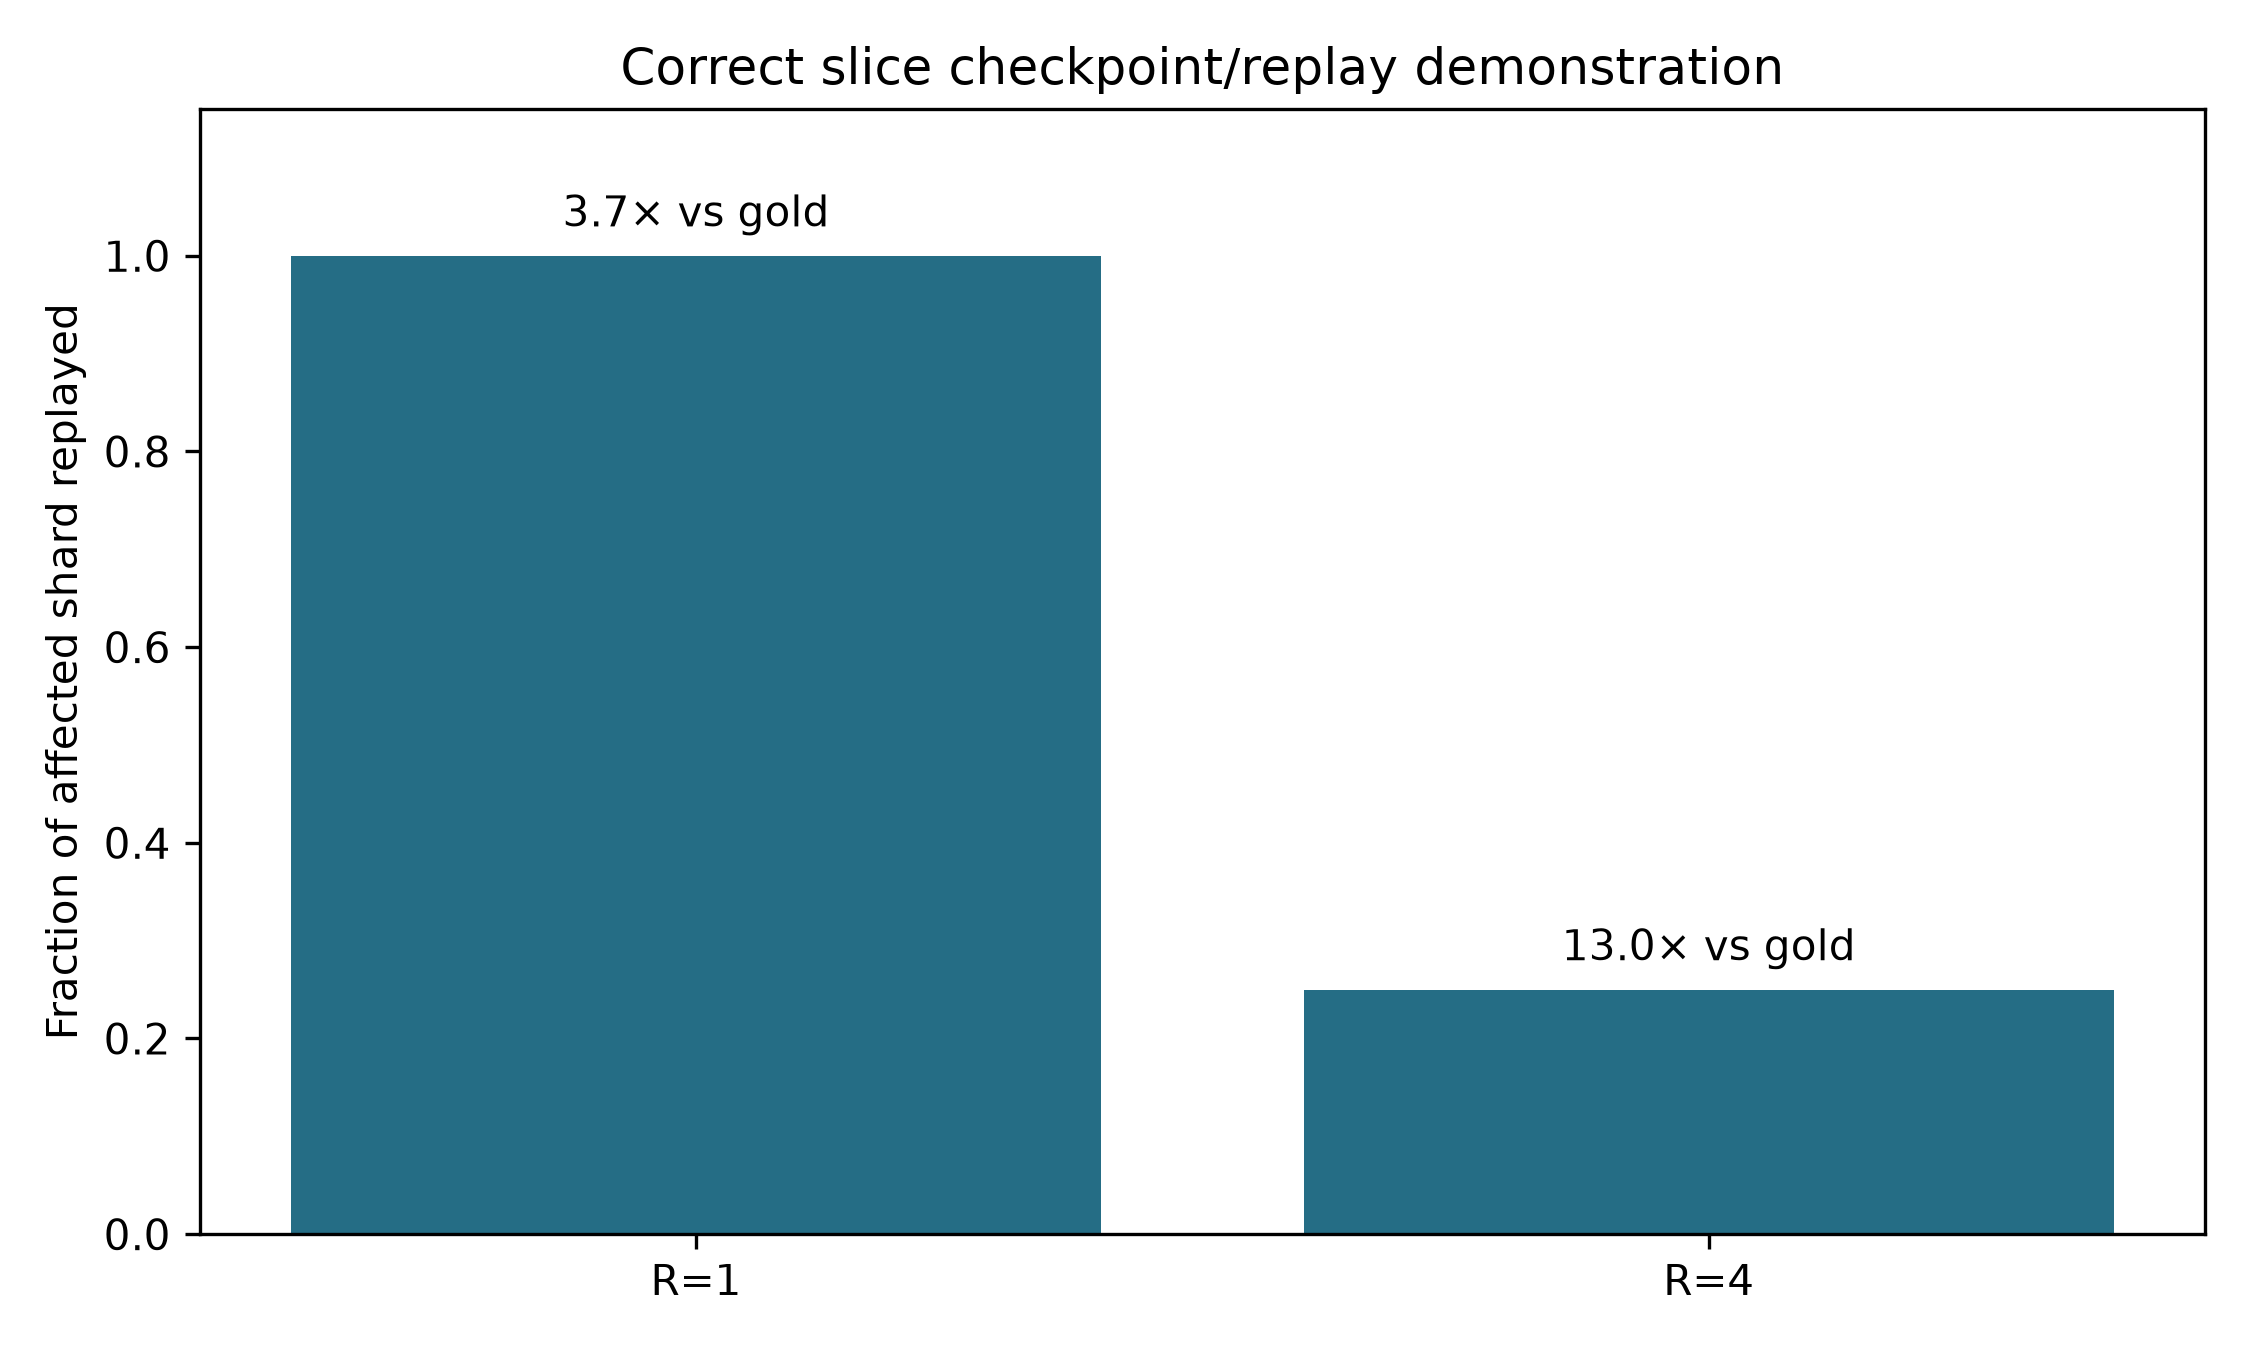

In [82]:
display(Image(filename=DIRS['figures'] / 'phase2_slicing_replay.png'))

**Interpretation.** R=4 และ deletion ใน final slice replay ประมาณ 25% ของ affected shard และ match gold exactly; R=1 replay ทั้ง shard. หลักฐานนี้เฉพาะ incremental logistic experiment ไม่ขยายไป RF/boosting.

### Approximate unlearning where the library supports continued boosting

In [83]:
approximate = pd.read_csv(DIRS['results'] / 'approximate_two_boosters.csv')
display(approximate.head(40))

,model,method,scenario,approx_seconds,prediction_mae,prediction_rmse,max_probability_difference,prediction_disagreement,approx_roc_auc,gold_roc_auc
0,LightGBM,continued_boosting_heuristic,single_record,1.150111,0.003220,0.005241,0.059205,0.008954,0.765950,0.766285
1,XGBoost,continued_boosting_heuristic,single_record,1.267157,0.003086,0.005290,0.067659,0.007393,0.769315,0.769013


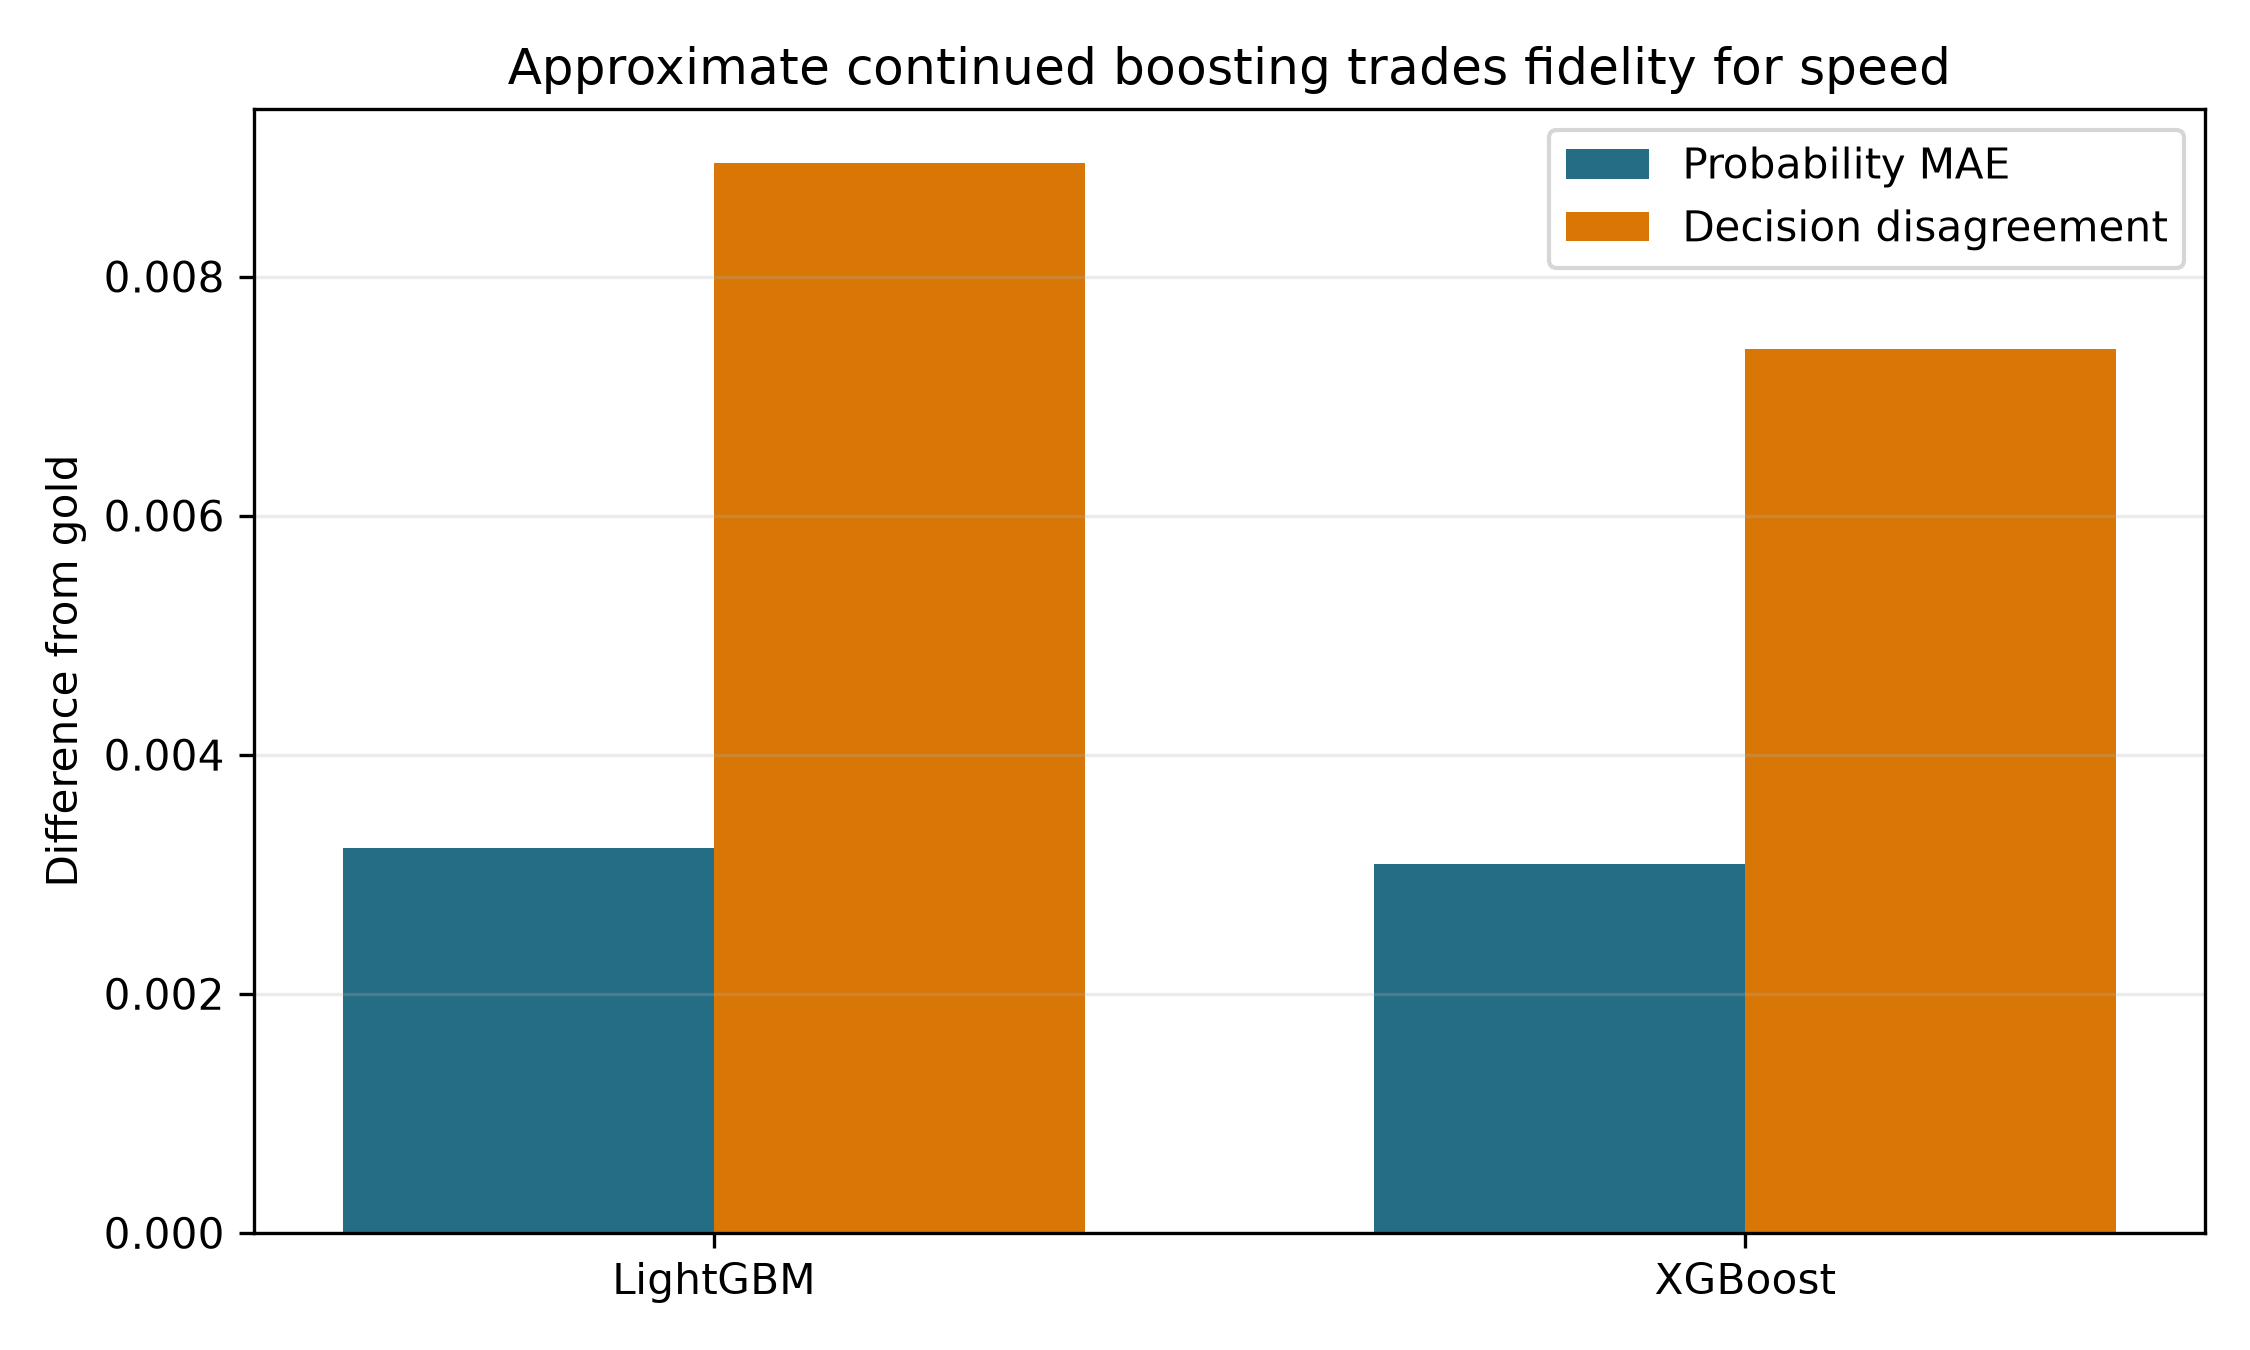

In [84]:
display(Image(filename=DIRS['figures'] / 'phase2_approximate_two_boosters.png'))

**Interpretation.** Continued boosting เร็วกว่า exact shard retraining แต่มี MAE ราว 0.0031–0.0032 และ non-zero decision disagreement. เนื่องจาก original trees ยังอยู่ วิธีนี้จึงเป็น heuristic approximation ไม่ใช่ exact forgetting.

## 4.6 Deletion Workload and Computational Efficiency

In [85]:
diffuse_exact = pd.read_csv(DIRS['results'] / 'exact_sisa_vs_gold.csv')
display(diffuse_exact.head(40))

,repetition,deletion_fraction,deleted_records,affected_shards,workload_fraction,exact_seconds,gold_seconds,speedup,prediction_mae,prediction_rmse,max_probability_difference,prediction_disagreement,exact_roc_auc,gold_roc_auc,status,error
0,0,0.01,1845,4,1.0,12.738891,14.170602,1.112389,0.0,0.0,0.0,0.0,0.766098,0.766098,complete,NaN
1,1,0.01,1845,4,1.0,14.184641,10.515830,0.741353,0.0,0.0,0.0,0.0,0.766248,0.766248,complete,NaN
2,2,0.01,1845,4,1.0,9.834304,9.509947,0.967018,0.0,0.0,0.0,0.0,0.765408,0.765408,complete,NaN


In [86]:
runtime_phase2 = pd.read_csv(DIRS['results'] / 'phase2_runtime_summary.csv')
display(runtime_phase2.head(40))

,experiment,unit,seconds,threads,note
0,SISA training,Logistic Regression,17.492872,2,sum of S=4 shard fits
1,SISA training,Random Forest,222.540560,2,sum of S=4 shard fits
2,SISA training,LightGBM,12.330813,2,sum of S=4 shard fits
3,SISA training,XGBoost,15.521894,2,sum of S=4 shard fits
4,shard-count training,LightGBM S=2,12.600352,2,sum of shard fits
5,shard-count training,LightGBM S=4,12.330813,2,sum of shard fits
6,shard-count training,LightGBM S=8,18.710777,2,sum of shard fits
7,shard-count training,LightGBM S=16,26.461368,2,sum of shard fits
8,exact single-record unlearning,Logistic Regression,3.927141,2,affected shard only
9,compatible gold retraining,Logistic Regression,14.605070,2,all shards


In [87]:
policy_runtime_summary = pd.read_csv(DIRS['results'] / 'policy_deletion_runtime_summary.csv')
display(policy_runtime_summary.head(40))

,assignment,measurements,mean_seconds,sd_seconds,median_seconds
0,Specialist + policy-aware nested mapping,9,22.625103,11.483651,29.564732
1,Specialist baseline,9,30.916567,0.954081,30.687314


**Interpretation.** Diffuse 1% deletion กระทบครบทุก shard จึง affected-data และ actual-retrained fractions เท่ากับ 1 และไม่มี speedup ที่เชื่อถือได้. Policy-aware runtime benchmark เป็น evidence รอง 3 targets × 3 repeats; variability สูงจึงให้ explicit data fractions เป็นข้อสรุปหลัก.

## 4.7 Membership Inference Results

In [88]:
mia = pd.read_csv(DIRS['results'] / 'privacy_mia.csv')
display(mia.head(40))

,model_state,attacked_shard,verified_members,verified_nonmembers,deleted_records_in_shard,attack_auc,attack_power,deleted_inferred_member_rate_at_5pct_fpr
0,original,0,5000,5000,483,0.524510,inconclusive,0.031056
1,exact_and_gold,0,5000,5000,483,0.526159,inconclusive,0.035197


**Interpretation.** Attack AUC ประมาณ 0.525–0.526 ต่ำกว่า power threshold 0.55 จึงสรุปว่า attack นี้ inconclusive. ห้ามอ้างว่า privacy ดีขึ้นหรือ unlearning ผ่าน privacy audit.

## 4.8 Synthesis and Discussion

In [89]:
# Lightweight artifact-to-headline audit (no model fitting).
baseline_check = pd.read_csv(DIRS['results'] / 'baseline_performance_complete.csv')
sisa_check = pd.read_csv(DIRS['results'] / 'sisa_four_model_comparison.csv')
controlled_check = pd.read_csv(DIRS['results'] / 'expanded_controlled_sharding.csv')
scalability_check = pd.read_csv(DIRS['results'] / 'shard_count_scalability_extended.csv')
exact_check = pd.read_csv(DIRS['results'] / 'fidelity_detailed_four_models.csv')
slicing_check = pd.read_csv(DIRS['results'] / 'slicing_demonstration.csv')
approx_check = pd.read_csv(DIRS['results'] / 'approximate_two_boosters.csv')
mia_check = pd.read_csv(DIRS['results'] / 'privacy_mia.csv')
policy_check = pd.read_csv(DIRS['results'] / 'policy_deletion_per_relationship.csv')

assert set(baseline_check.model) == {'Logistic Regression','Random Forest','LightGBM','XGBoost'}
assert baseline_check[['roc_auc','average_precision','ks','brier','threshold']].notna().all().all()
assert np.allclose(sisa_check.roc_auc_delta, sisa_check.sisa_roc_auc-sisa_check.baseline_roc_auc)
assert set(controlled_check.strategy) == {'stratified_balanced','random_balanced','representative','specialist','risk_band'}
assert scalability_check.shards.tolist() == [2,4,8,16,32,64,128]
assert exact_check.exact_gold_mae.max() < 1e-12
assert set(slicing_check.slices) == {1,4}
assert set(approx_check.model) == {'LightGBM','XGBoost'}
assert mia_check.attack_auc.max() < 0.55
assert set(policy_check.workload_improved) == {'yes','no'}

display(pd.DataFrame({
    'evidence_check': ['baseline metrics complete','SISA deltas consistent','S=2..128 complete',
                       'Exact≈Gold','slicing R=1/R=4','MIA interpretation','policy mixed outcomes visible'],
    'status': ['PASS']*7
}))

,evidence_check,status
0,baseline metrics complete,PASS
1,SISA deltas consistent,PASS
2,S=2..128 complete,PASS
3,Exact≈Gold,PASS
4,slicing R=1/R=4,PASS
5,MIA interpretation,PASS
6,policy mixed outcomes visible,PASS


In [90]:
findings = pd.read_csv(DIRS['results'] / 'final_consolidated_findings.csv')
display(findings.head(40))

,research_question,finding,limitation
0,Effect of SISA across models,S=4 changed ROC-AUC by -0.0030 to +0.0010 acro...,"One common configuration, not per-model optimi..."
1,Shard-count trade-off,AUC declined from 0.7678 at S=2 to 0.7602 at S...,LightGBM focused sweep.
2,Deletion locality,Specialist and risk-band assignments reduced w...,Speedup in the scale grid is workload-derived;...
3,Exactness,Exact SISA matched compatible gold predictions...,Conditional on fixed preprocessing and assignm...
4,Approximation,Continued boosting was faster but introduced m...,Not defined for LR/RF.
5,Privacy,The evaluated MIA was inconclusive.,No privacy improvement can be claimed.
6,How does fine SISA partitioning affect utility...,"S=2,4,8,16,32,64,128 shows non-monotonic utili...",LightGBM-only sensitivity analysis; final-test...
7,Can an operational relationship layer configur...,The same 10 strict synthetic relationship requ...,"Synthetic, intentionally optimized case study;..."


In [91]:
coverage = pd.read_csv(DIRS['results'] / 'objective_coverage.csv')
display(coverage.head(40))

,objective,status,evidence,qualification
0,1,SUPPORTED,4.2 Sharding Strategy Results; sisa_four_model...,"Common S=4 comparison across LR, RF, LightGBM ..."
1,2,SUPPORTED,"4.4–4.6 Fidelity, unlearning, and computationa...",Exact cross-model scenario is descriptive (one...
2,3,SUPPORTED,"4.2–4.3 controlled sharding, paired locality, ...",Controlled and practical comparisons are repor...
3,4,PARTIALLY SUPPORTED,4.7 Membership Inference Results; privacy_mia.csv,Verified-membership loss attack was weak (AUC≈...
4,5,PARTIALLY SUPPORTED,4.8 Synthesis and Discussion; technical suitab...,Technical suitability is evaluated on a local ...


### 4.8.1 Utility–Fidelity–Privacy–Cost Trade-off

งานรองรับว่า SISA สามารถรักษา predictive utility ได้ใกล้ baseline และ exact shard retraining สามารถตรงกับ compatible Gold ภายใต้ fixed protocol ข้ามสี่ model families. ประโยชน์ด้าน compute เป็น **conditional on deletion locality**: distributed requests สามารถทำให้ต้อง retrain ทุก shard. Shard count ที่ละเอียดขึ้นลด localized retraining fraction แต่เพิ่มจำนวน models/ensemble overhead และ utility เปลี่ยนแบบ non-monotonic. Specialist/Risk-Band ช่วยเฉพาะ matched patterns โดย Risk-Band มี utility/aggregation trade-off ชัดเจน.

### 4.8.2 Model-specific Sensitivity

Boosting models ให้ utility สูงสุด; RF มี runtime สูง; slicing evidence ใช้ได้เฉพาะ incremental LR; approximate continued boosting ใช้ได้เฉพาะ LightGBM/XGBoost. จึงไม่ควรสรุปวิธีเดียวครอบคลุมทุก family.

### 4.8.3 Sharding Strategy Selection Guideline

ใช้ Stratified เมื่อ deletion pattern ไม่แน่นอนและต้องการ stable control; Representative เมื่อต้องการ population-like shards; Specialist เมื่อ feature-localized requests มีเหตุผลรองรับ; Risk-Band เมื่อ risk-localized requests สำคัญและยอมรับ aggregation complexity/utility trade-off. Random-balanced เป็น control เท่านั้น.

### 4.8.4 Unlearning Method Selection Guideline

ใช้ exact affected-shard retraining เมื่อ fidelity เป็นข้อกำหนดหลัก; ใช้ slicing เมื่อ estimator รองรับ deterministic incremental checkpoints; approximate boosting ใช้เมื่อยอมรับ measurable mismatch ได้และต้องระบุว่าไม่ exact.

### 4.8.5 Robustness Across Scenarios and Replications

Primary locality inference ใช้ paired n=10. Cross-model single deletion และ policy runtime เป็น descriptive standardized scenarios. Negative results—diffuse affected-data/actual-retrained fractions=1, Risk-Band utility loss, approximate mismatch และ inconclusive MIA—ถูกเก็บไว้ทั้งหมด.

### 4.8.6 Practical Decision Framework

กรอบตัดสินใจไม่จัดอันดับวิธีแบบสากล: distributed request ที่แตะหลาย shards อาจทำให้ข้อได้เปรียบ SISA หาย; localized request เหมาะกับ finer S หรือ matched sharding; fidelity สูงใช้ Exact SISA/compatible Gold; approximate booster ใช้ได้เมื่อยอมรับ mismatch; Specialist เหมาะกับ feature-defined locality; Risk-Band ต้องประเมิน utility cost; policy-aware mapping ใช้ได้เมื่อ metadata และ governance semantics รองรับ. การตั้งค่าที่เหมาะขึ้นกับ model family, shard granularity, deletion locality, operational relationships, required fidelity และ computational resources.

### Limitations and deferred work

1. Exactness เป็น conditional model-level exactness ภายใต้ fixed preprocessing/assignment—not raw-source deletion.
2. Standardized cross-model exact test มี deletion record เดียว; runtime จึง descriptive.
3. S sweep ทำเฉพาะ LightGBM; per-family S optimization defer.
4. Slicing พิสูจน์เฉพาะ incremental logistic; production slicing สำหรับ RF/boosting defer.
5. Approximate method มีเฉพาะ LightGBM/XGBoost; ไม่มีการสร้างวิธีเทียมสำหรับ LR/RF.
6. Focused MIA ไม่มี power พอสรุป privacy; shadow-model/attribute attacks defer.
7. ใช้ dataset/domain เดียวและเครื่อง local เดียว; external validity และ distributed infrastructure benchmark defer.
8. PDPA เป็น motivation และ suitability discussion—not legal compliance audit.
9. Policy-aware relationships เป็น synthetic scenario ที่ intentionally optimized; ไม่ใช่ real Home Credit partnerships และไม่พิสูจน์ว่า mapping นี้ควรใช้ในธนาคารจริง.

# Thesis traceability and implementation appendix

In [92]:
traceability = pd.read_csv(DIRS['results'] / 'traceability_matrix.csv')
display(traceability.head(30))

,thesis_section,chapter_4_evidence,code_or_method,artifact,figure
0,3.1 Dataset,4.1 Baseline Model Performance,identity-safe source/split audit,dataset_table_summary.csv; split_integrity.csv,phase2_class_distribution.png
1,3.2 Data Preprocessing,4.1 Baseline Model Performance,train-only preprocessing audit,preprocessing_audit.csv,-
2,3.3 Baseline Model Development,4.1 Baseline Model Performance,four fixed model families; frozen calibration/...,baseline_model_config.csv; baseline_performanc...,baseline_and_sisa_auc.png
3,3.3.1 Logistic Regression,4.1 Baseline Model Performance,linear reference,baseline_performance_complete.csv,-
4,3.3.2 Random Forest,4.1 Baseline Model Performance,bagged-tree reference,baseline_performance_complete.csv,-
5,3.3.3 LightGBM,4.1 Baseline Model Performance,boosting reference and scalability representative,baseline_performance_complete.csv,-
6,3.3.4 XGBoost,4.1 Baseline Model Performance,second boosting family,baseline_performance_complete.csv,-
7,3.4 SISA Sharding Strategies,4.2 Sharding Strategy Results,fixed SISA architecture and assignment comparison,sisa_four_model_comparison.csv,phase2_sisa_four_models.png
8,3.4.1 Stratified,4.2 Sharding Strategy Results,class-wise round robin,sharding_contribution_thesis.csv,phase2_sharding_utility_locality.png
9,3.4.2 Representative,4.2 Sharding Strategy Results,SVD8/cluster representation,sharding_contribution_thesis.csv,phase2_sharding_utility_locality.png


## Legacy Research Component → Final Status

In [93]:
legacy_coverage = pd.read_csv(DIRS['results'] / 'legacy_to_final_coverage.csv')
display(legacy_coverage.head(30))

,legacy_research_component,class,final_status,class_meaning
0,Legacy identity/data pipeline,B,replaced by corrected SK_ID_CURR-aligned pipel...,replaced by corrected implementation
1,Legacy split/calibration workflow,B,replaced by isolated train/validation/calibrat...,replaced by corrected implementation
2,LR/RF/LightGBM/XGBoost baselines,B,recomputed under corrected common protocol,replaced by corrected implementation
3,Legacy SISA models,B,recomputed with compatible S=4 comparison acro...,replaced by corrected implementation
4,Shard-count study,B,restored as corrected focused LightGBM scalabi...,replaced by corrected implementation
5,Stratified/Representative/Specialist/Risk-Band,B,retained under controlled assignment-only comp...,replaced by corrected implementation
6,Random-balanced,A,"retained as control, not a fifth research design",already correctly represented
7,Simple and learned aggregation,B,controlled and practical layers separated,replaced by corrected implementation
8,Deletion scale/locality,B,replaced by paired distributed/feature/risk-lo...,replaced by corrected implementation
9,Exact SISA vs Gold and forget behavior,B,"revalidated with compatible seeds, assignments...",replaced by corrected implementation


Core implementation ที่แสดงใน notebook มาจากไฟล์เดียวกับที่ใช้สร้างผลจริง: `final_pipeline.py`, `expanded_experiments.py`, `thesis_notebook_support.py`, `policy_aware_extension.py`. Controller cells ใช้ validate/reuse checkpoint; ไม่ใช่สิ่งทดแทน implementation cells. ORG chain ถูกคืนมาเฉพาะในฐานะ corrected supplementary case study; proxy exploratory branches อื่นไม่ถูกคืน. รายการ section → code → artifact → figure อยู่ใน `THESIS_TRACEABILITY.md`.

# Restored Experimental Scope — Additive Extension

`RESTORED-EXPERIMENTAL-SCOPE-V1-FINAL-PATCH`

ส่วนนี้ถูก append หลัง notebook เดิมครบ 181 cells โดยไม่มีการลบ แก้ไข เรียงใหม่ หรือรันซ้ำผลเดิม ผลใหม่ทั้งหมดเขียนลง `outputs_restored/` เท่านั้น และใช้ `outputs_final/` แบบ read-only หลังตรวจ configuration compatibility แล้ว

Protocol คง Train/Calibration/Validation/Test roles, final model configurations, deterministic seeds, Platt calibration, Validation-only threshold selection และ Test-only final reporting ส่วน slicing เดิม R=1/4 ถูกเก็บไว้เพื่อ provenance แต่ถูก supersede ด้วย full corrected grid ด้านล่างซึ่งใช้ post-deletion retained-size weights.

In [94]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
import restored_experiments as restored

restored.initialize_restoration()
RESTORED_OUT = restored.OUT
display(pd.DataFrame([restored._manifest()['restoration_plan']]))
print('Restored output root:', RESTORED_OUT)
print('Implementation:', Path(restored.__file__).resolve())

[2026-09-30 09:56:33] Restoration initialized; immutable source hashes and environment verified


,models,shard_grid,strategies,slicing_grid,exact_requests_per_model,learned_strategies,stress
0,"[Logistic Regression, Random Forest, LightGBM,...","[2, 4, 8, 16, 32, 64, 128]","[stratified_balanced, random_balanced, represe...","[1, 2, 4, 8]",4,"[specialist, risk_band]","{'model': 'LightGBM', 'rounds': 30, 'records_p..."


Restored output root: outputs_restored
Implementation: restored_experiments.py


## R1. Cross-model Shard-count Sensitivity and Positive-sample Scarcity

Common pre-specified grid `S={2,4,8,16,32,64,128}` for Logistic Regression, Random Forest, LightGBM and XGBoost. No Test-based optimal-S selection is performed. Model families show different sensitivity to increasing shard granularity under a common experimental protocol; intermediate recoveries mean the pattern must not be described as monotonic. Positive-count and class-rate diagnostics are explanatory associations only, not evidence that scarcity causes utility changes.

,model,shards,roc_auc,average_precision,min_positives_per_shard,total_fit_seconds
0,LightGBM,2,0.767791,0.259655,7447,12.600352
1,LightGBM,4,0.765968,0.254092,3723,12.330813
2,LightGBM,8,0.762574,0.250513,1861,18.710777
3,LightGBM,16,0.760228,0.247547,930,26.461368
4,LightGBM,32,0.760952,0.247565,465,44.179180
5,LightGBM,64,0.763510,0.250502,232,64.875998
6,LightGBM,128,0.757137,0.243912,116,84.072131
7,Logistic Regression,2,0.754624,0.235153,7447,17.921740
8,Logistic Regression,4,0.754480,0.235468,3723,17.492872
9,Logistic Regression,8,0.754243,0.235521,1861,16.133762


,model,shards,min_rows_per_shard,mean_rows_per_shard,min_positives_per_shard,median_positives_per_shard,mean_positives_per_shard,zero_positive_shards,min_positive_rate_per_shard,mean_positive_rate_per_shard,max_positive_rate_per_shard,sd_positive_rate_across_shards,roc_auc,average_precision
0,LightGBM,2,92252,92252.500000,7447,7447.0,7447.000000,0,0.080724,0.080724,0.080725,4.375171e-07,0.767791,0.259655
1,LightGBM,4,46125,46126.250000,3723,3723.5,3723.500000,0,0.080714,0.080724,0.080734,9.547325e-06,0.765968,0.254092
2,LightGBM,8,23062,23063.125000,1861,1862.0,1861.750000,0,0.080696,0.080724,0.080735,1.657172e-05,0.762574,0.250513
3,LightGBM,16,11530,11531.562500,930,931.0,930.875000,0,0.080659,0.080724,0.080739,2.469484e-05,0.760228,0.247547
4,LightGBM,32,5765,5765.781250,465,465.0,465.437500,0,0.080659,0.080724,0.080819,7.373144e-05,0.760952,0.247565
5,LightGBM,64,2882,2882.890625,232,233.0,232.718750,0,0.080500,0.080724,0.080819,1.407502e-04,0.763510,0.250502
6,LightGBM,128,1441,1441.445312,116,116.0,116.359375,0,0.080500,0.080724,0.081137,2.998518e-04,0.757137,0.243912
7,Logistic Regression,2,92252,92252.500000,7447,7447.0,7447.000000,0,0.080724,0.080724,0.080725,4.375171e-07,0.754624,0.235153
8,Logistic Regression,4,46125,46126.250000,3723,3723.5,3723.500000,0,0.080714,0.080724,0.080734,9.547325e-06,0.754480,0.235468
9,Logistic Regression,8,23062,23063.125000,1861,1862.0,1861.750000,0,0.080696,0.080724,0.080735,1.657172e-05,0.754243,0.235521


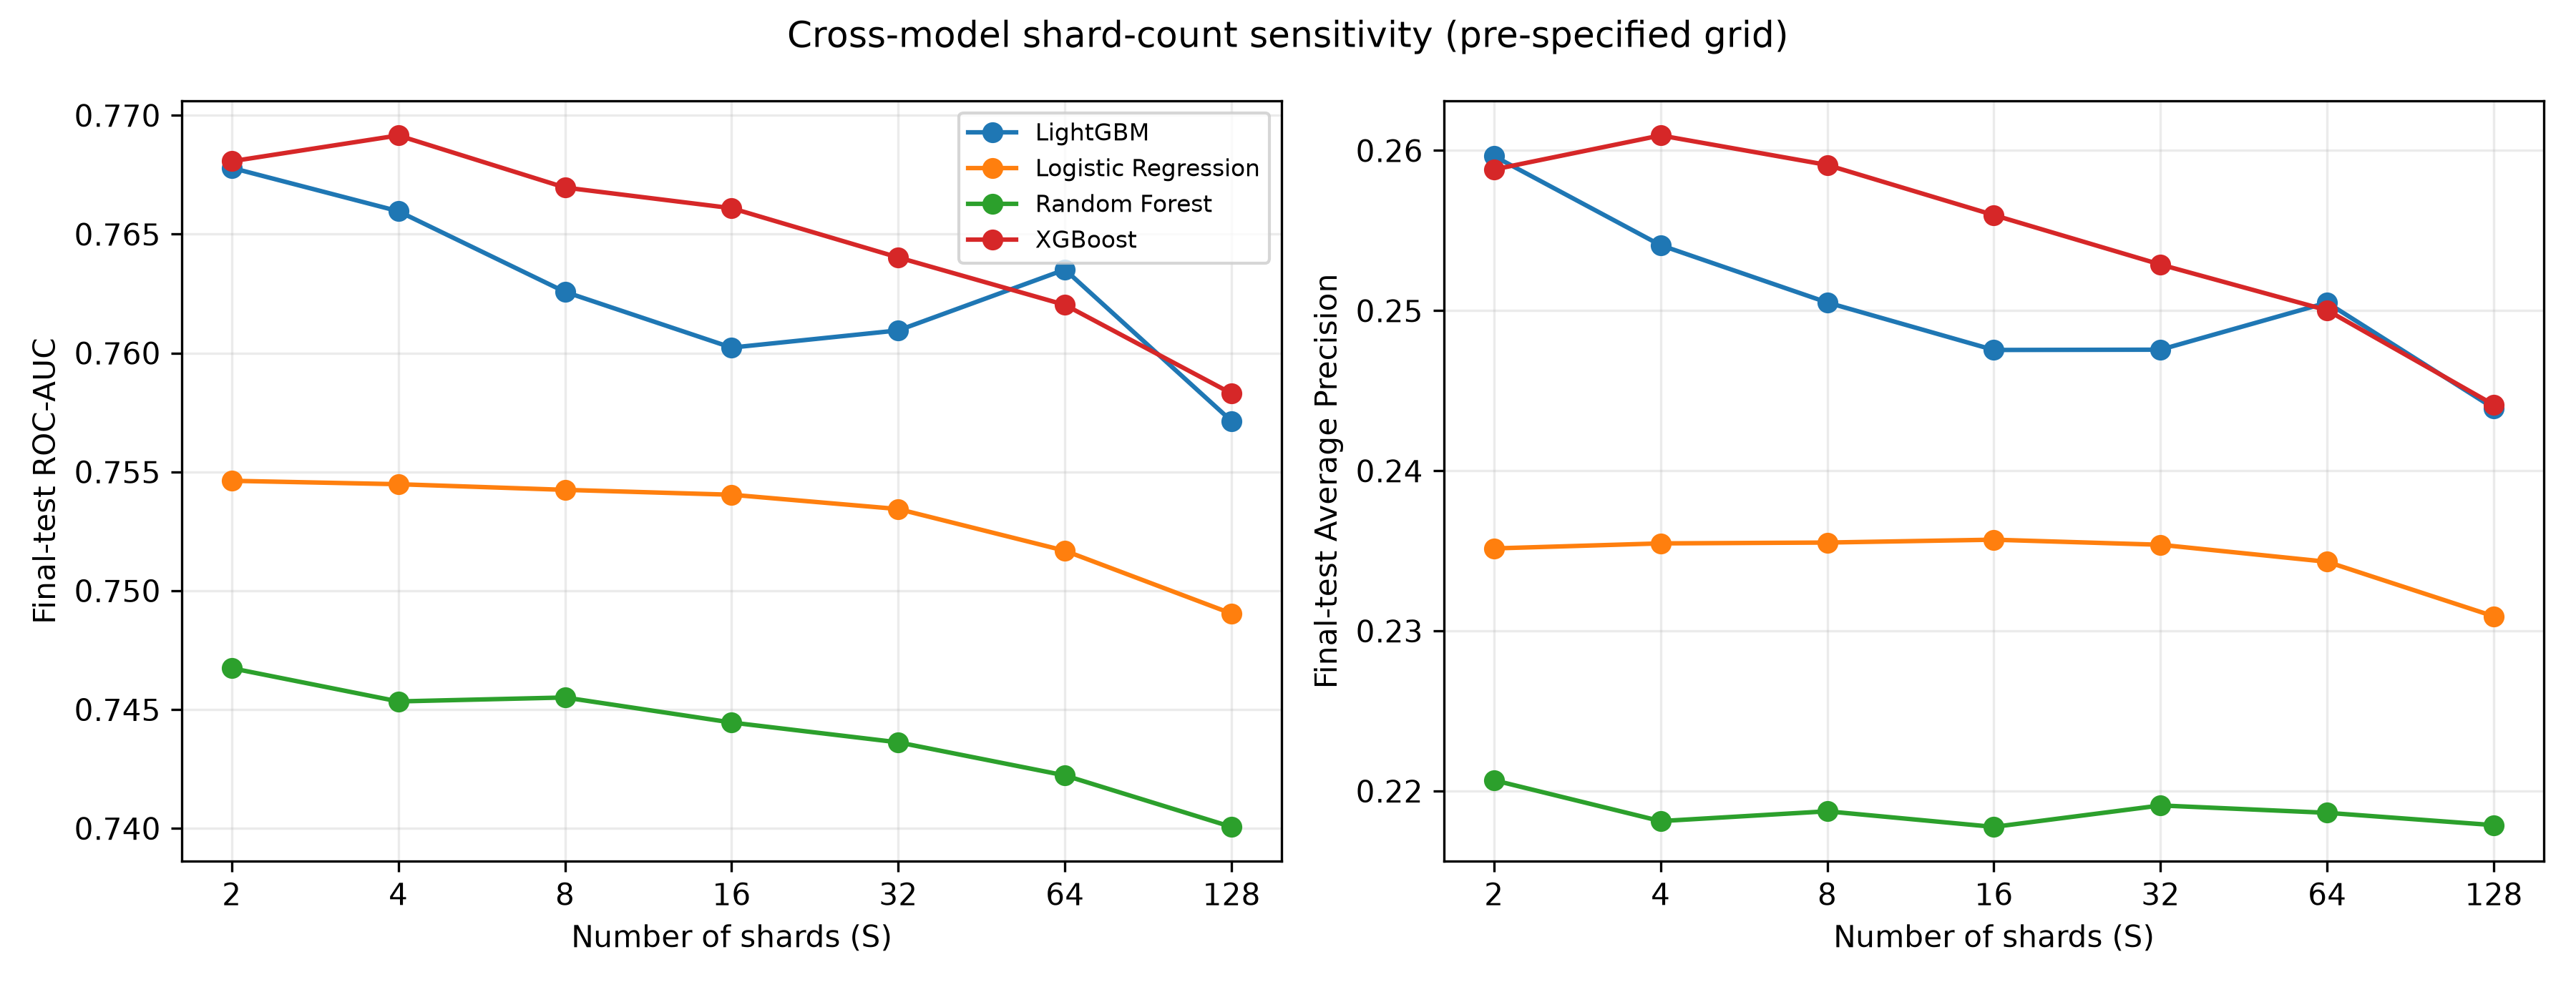

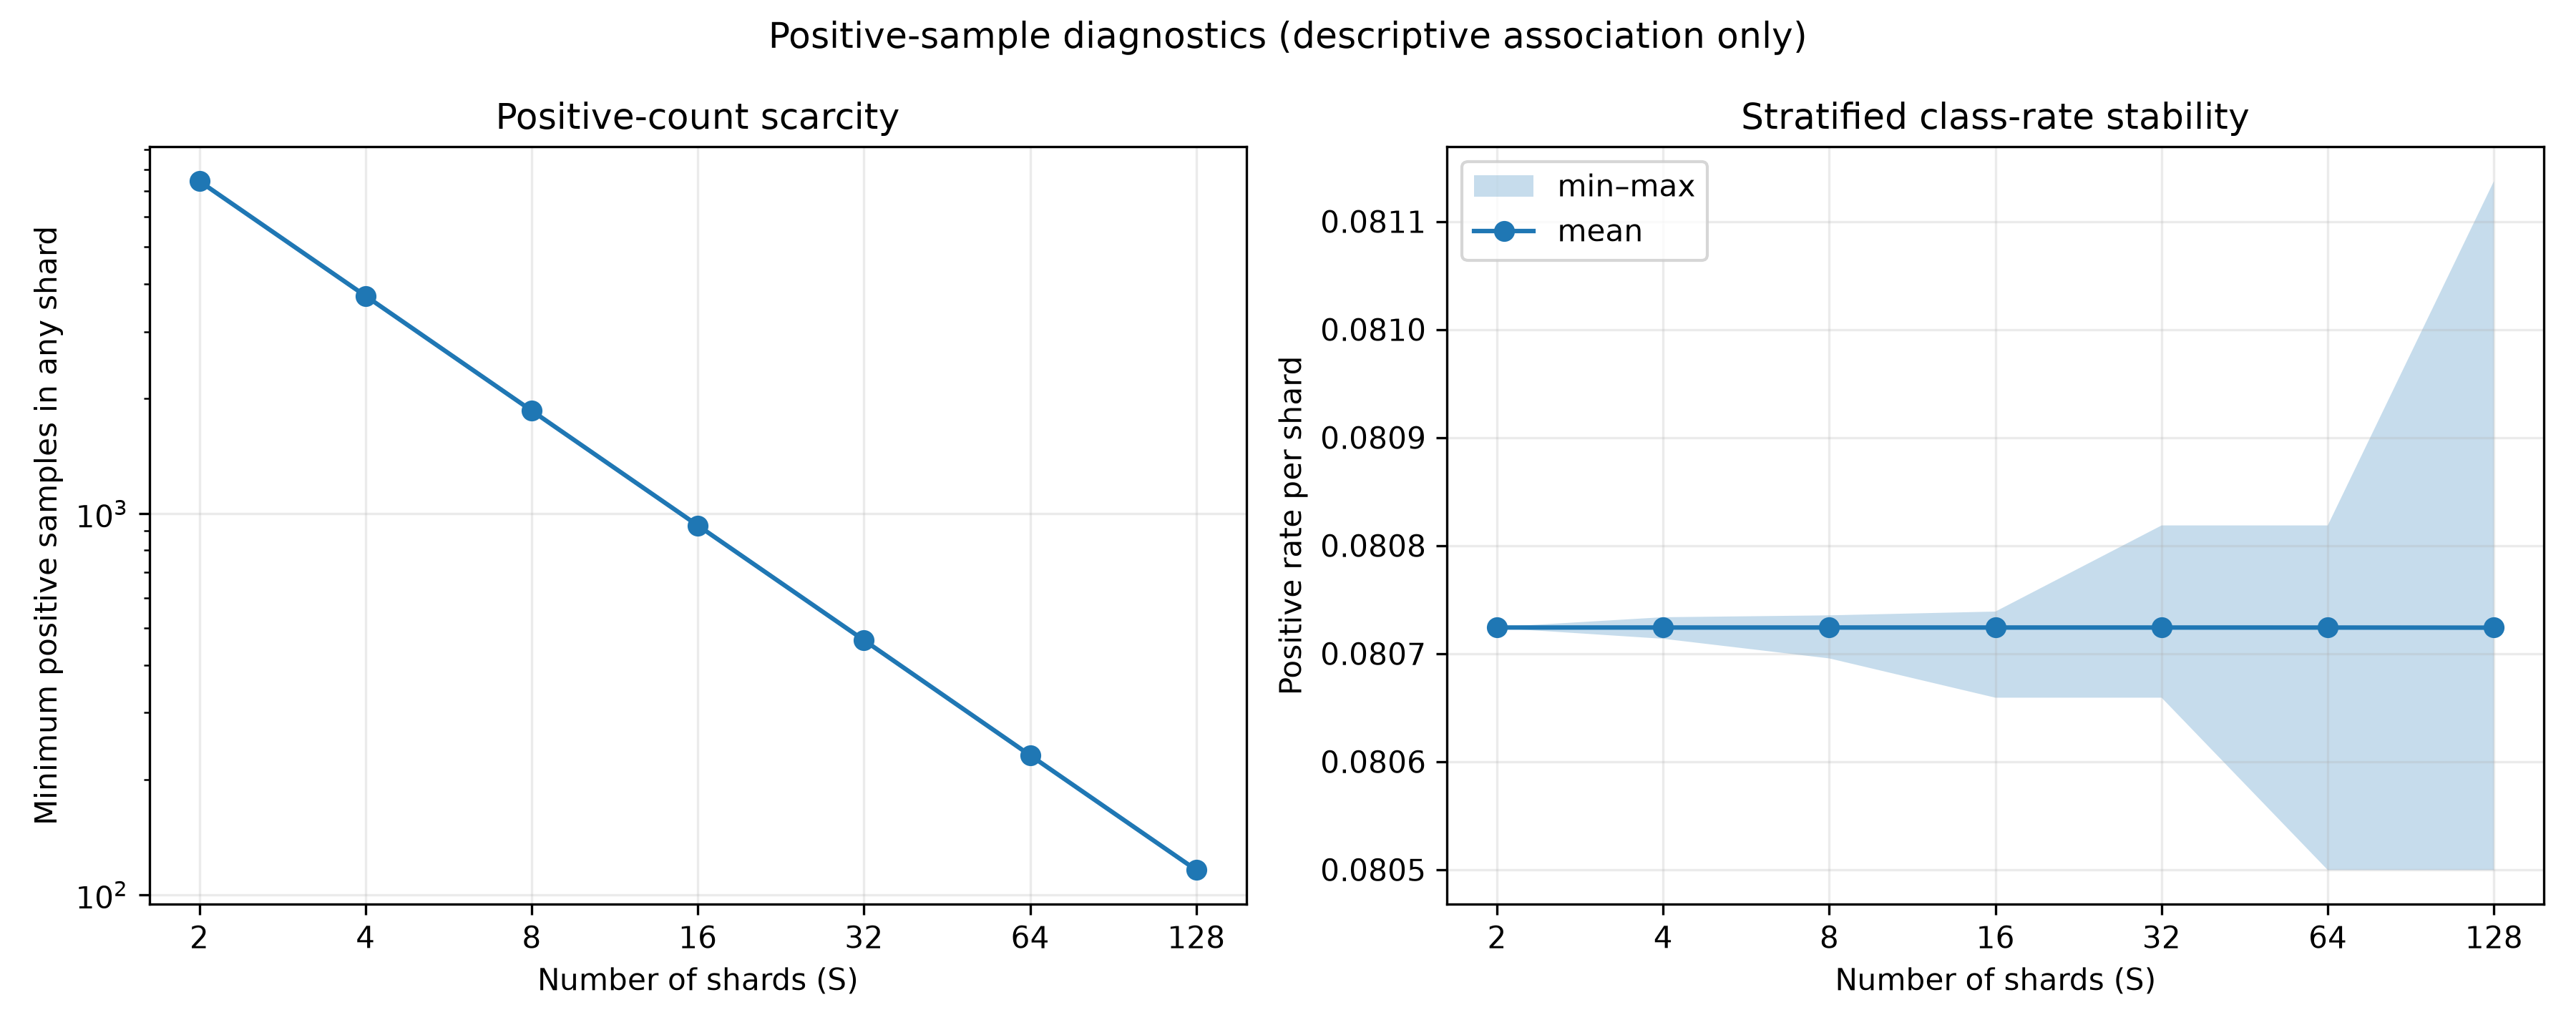

In [95]:
restored_shard_count = restored.stage_cross_model_shard_count()
scarcity = pd.read_csv(RESTORED_OUT / 'results' / 'positive_sample_scarcity_diagnostic.csv')
display(restored_shard_count[['model','shards','roc_auc','average_precision','min_positives_per_shard','total_fit_seconds']])
display(scarcity)
display(Image(filename=RESTORED_OUT / 'figures' / 'cross_model_shard_count_utility.png'))
display(Image(filename=RESTORED_OUT / 'figures' / 'positive_sample_scarcity.png'))

## R2. Cross-model Controlled Sharding Strategy Comparison

Four model families × five assignments at common `S=4`. Retained-size weighted aggregation, calibration and evaluation are fixed; only assignment changes. Random-balanced remains a control. The effect of Sharding Strategy differed across Model Families in the observed controlled comparison; no factorial inferential interaction test was performed. The common Risk-Band assignment was derived once from current 3-fold train-only OOF LightGBM risk scores and then reused unchanged for LR, RF, LightGBM and XGBoost.

,model,strategy,roc_auc,average_precision,ks,brier,total_fit_seconds
0,LightGBM,random_balanced,0.766113,0.254821,0.401932,0.067298,12.527306
1,LightGBM,representative,0.766435,0.255725,0.405010,0.067278,9.950381
2,LightGBM,risk_band,0.695504,0.173674,0.285560,0.071065,10.292106
3,LightGBM,specialist,0.765861,0.257348,0.401052,0.067229,13.337370
4,LightGBM,stratified_balanced,0.765968,0.254092,0.401034,0.067332,12.330813
5,Logistic Regression,random_balanced,0.754225,0.235331,0.379123,0.068119,17.286774
6,Logistic Regression,representative,0.754440,0.235190,0.379592,0.068105,14.966543
7,Logistic Regression,risk_band,0.751155,0.227743,0.379201,0.068494,15.643953
8,Logistic Regression,specialist,0.754566,0.233317,0.378436,0.068191,16.042665
9,Logistic Regression,stratified_balanced,0.754480,0.235468,0.378704,0.068107,17.492872


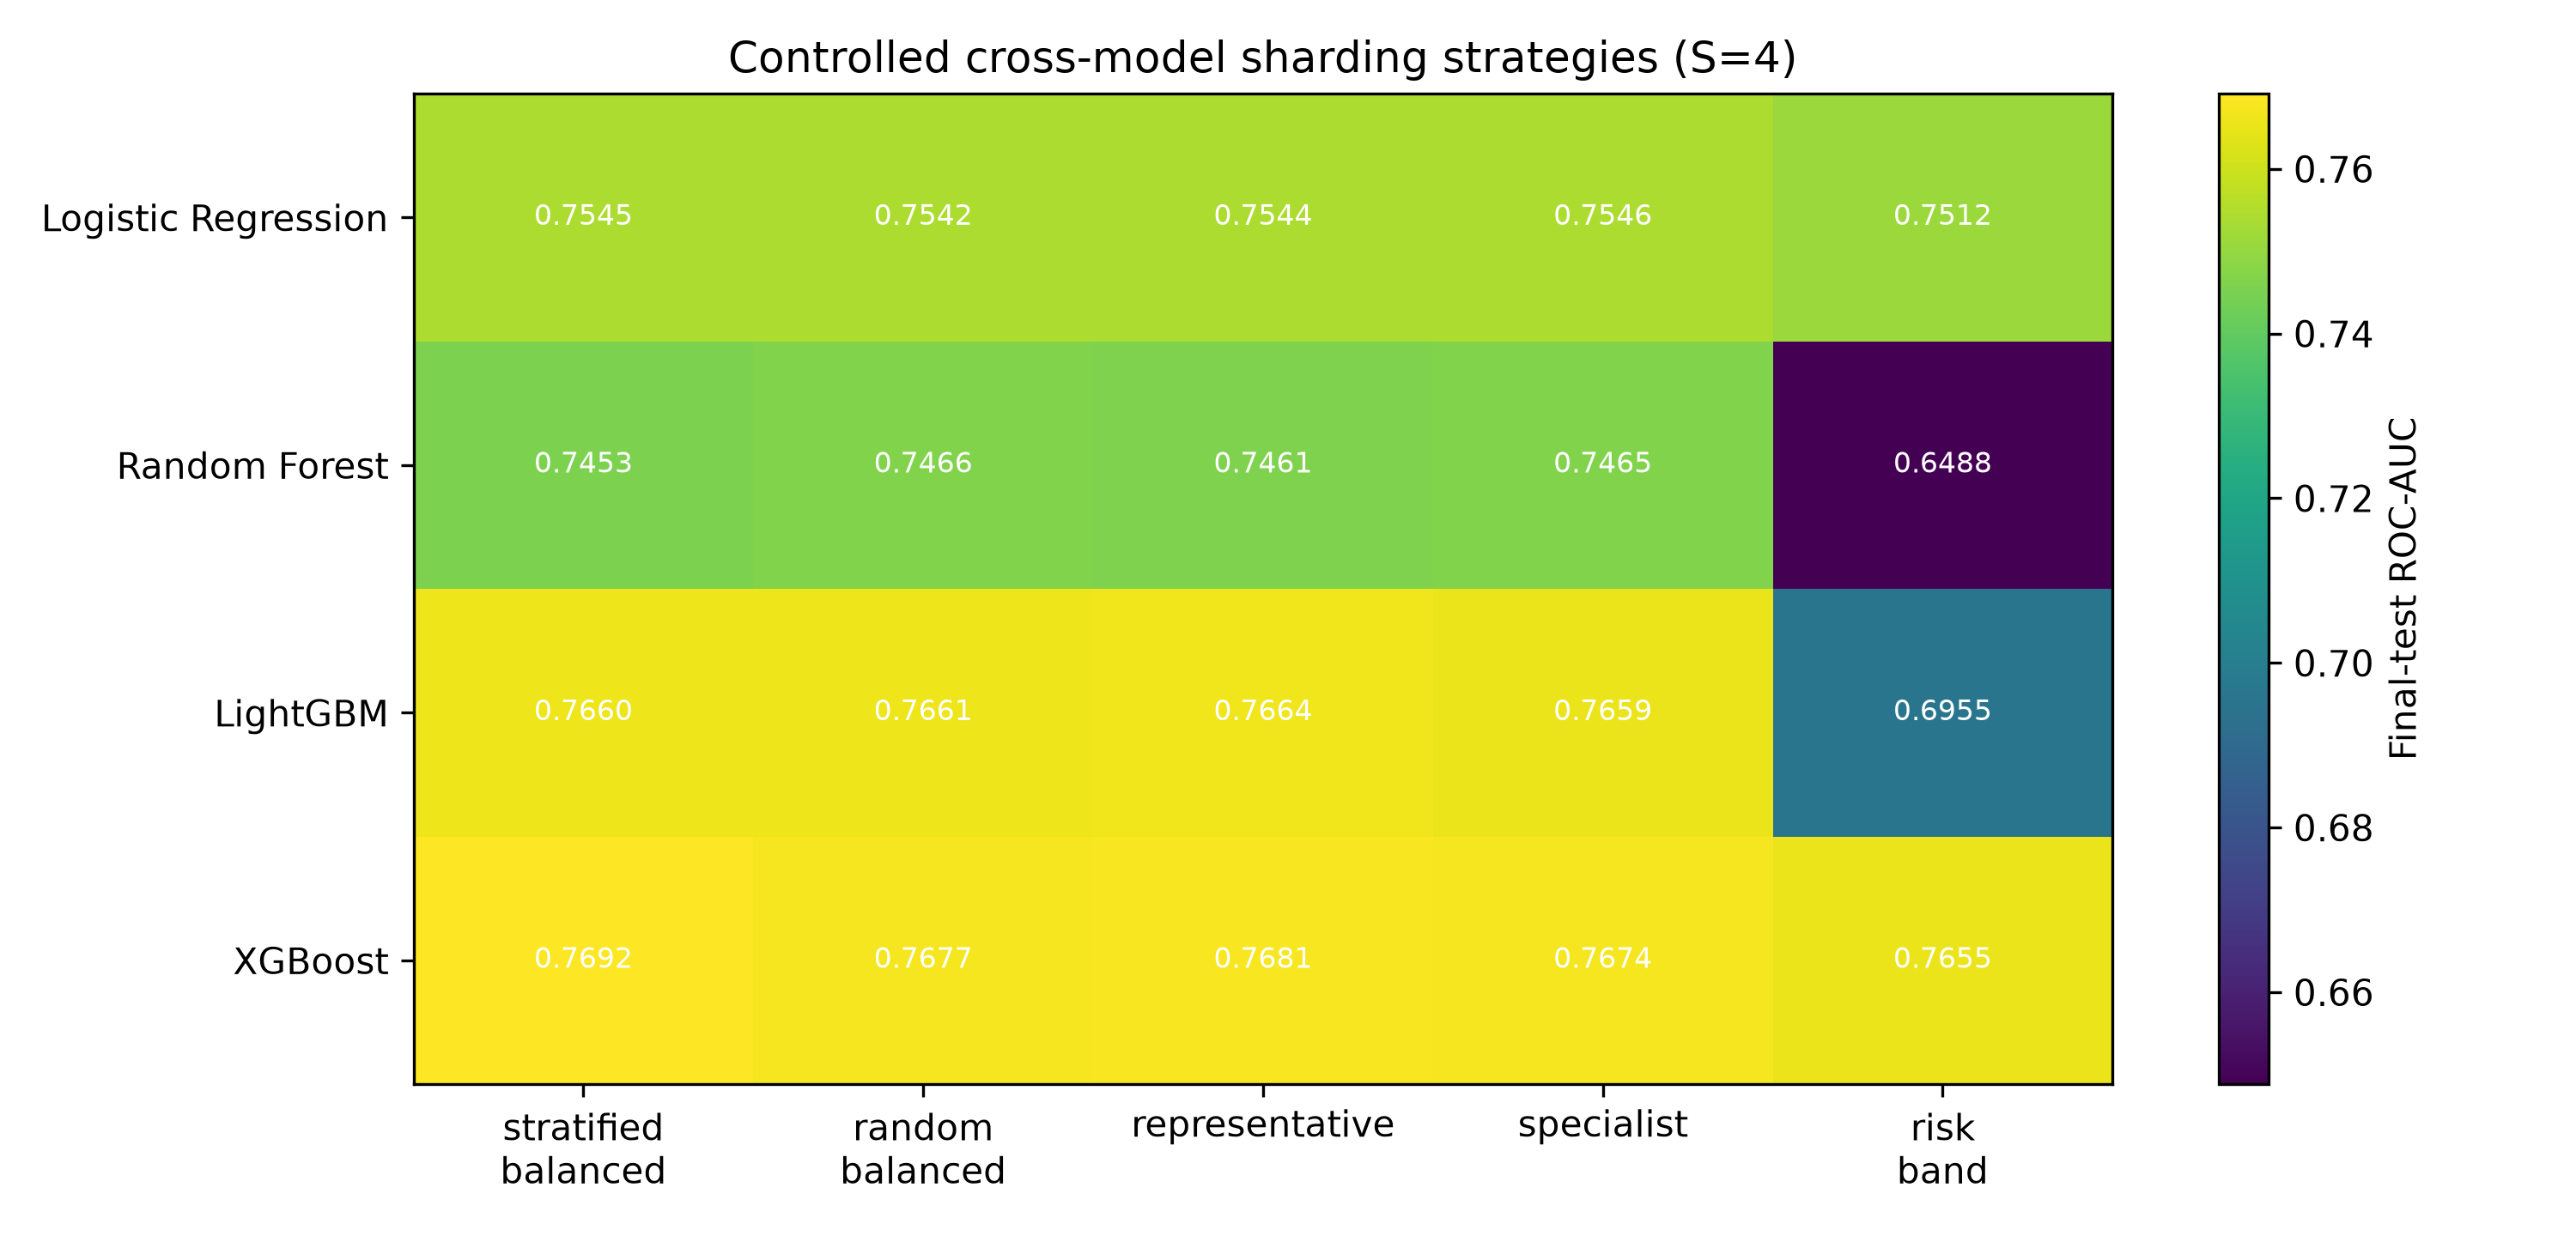

In [96]:
restored_controlled = restored.stage_cross_model_controlled_strategies()
display(restored_controlled[['model','strategy','roc_auc','average_precision','ks','brier','total_fit_seconds']])
display(Image(filename=RESTORED_OUT / 'figures' / 'cross_model_controlled_sharding.png'))

## R3. Corrected Full Slicing Grid R={1,2,4,8}

ทุกค่า R ถูก rerun ด้วย corrected incremental implementation และ post-deletion retained-size weights ตาราง `slicing_original_vs_corrected.csv` เก็บค่า R=1/4 เดิมและใหม่แยกกันเพื่อ audit; ไม่มีการผสมผลเดิมกับ comparison table/figure ที่เป็น authoritative ด้านล่าง

The slicing experiment deliberately deletes a record located in the final slice of the affected shard for each R. It is therefore a favorable-case mechanism demonstration of checkpoint replay and is not an estimate of expected replay workload under randomly located deletion requests. Deleted records differ across R, so small AUC differences must not be interpreted as an effect caused by R. The meaningful cross-R comparison is replay workload/runtime and Exact–Gold fidelity. `slicing_only_speedup` isolates slice replay benefit; `end_to_end_speedup_vs_all_shard_gold` combines shard isolation and slicing.

[2026-09-30 09:56:39] Validated corrected slicing checkpoint


,model,preprocessing,aggregation,shards,slices,deleted_records,deleted_SK_ID_CURR,deleted_row_index,deleted_slice,slice_position_description,...,replay_seconds,affected_shard_full_retrain_seconds,gold_all_shards_seconds,slicing_only_speedup,end_to_end_speedup_vs_all_shard_gold,prediction_mae,max_probability_difference,exact_roc_auc,gold_roc_auc,affected_shard_weight
0,SGD logistic (incremental LR),train-fitted MaxAbsScaler; 3 deterministic pas...,post-deletion retained-size weighted probability,4,1,1,171948,37264,0,last-slice favorable mechanism demonstration,...,0.401484,0.336291,1.196817,0.837620,2.980980,0.0,0.0,0.723979,0.723979,0.25
1,SGD logistic (incremental LR),train-fitted MaxAbsScaler; 3 deterministic pas...,post-deletion retained-size weighted probability,4,2,1,252676,78881,1,last-slice favorable mechanism demonstration,...,0.140666,0.391576,1.311303,2.783721,9.322067,0.0,0.0,0.723658,0.723658,0.25
2,SGD logistic (incremental LR),train-fitted MaxAbsScaler; 3 deterministic pas...,post-deletion retained-size weighted probability,4,4,1,258810,82008,3,last-slice favorable mechanism demonstration,...,0.072372,0.421221,1.488092,5.820237,20.561770,0.0,0.0,0.723596,0.723596,0.25
3,SGD logistic (incremental LR),train-fitted MaxAbsScaler; 3 deterministic pas...,post-deletion retained-size weighted probability,4,8,1,114336,7441,7,last-slice favorable mechanism demonstration,...,0.046710,0.453227,1.688293,9.703027,36.144229,0.0,0.0,0.723919,0.723919,0.25


,slices,original_replayed_fraction_of_affected_shard,corrected_replayed_fraction_of_affected_shard,delta_replayed_fraction_of_affected_shard,original_replay_seconds,corrected_replay_seconds,delta_replay_seconds,original_gold_all_shards_seconds,corrected_gold_all_shards_seconds,delta_gold_all_shards_seconds,...,delta_exact_roc_auc,original_gold_roc_auc,corrected_gold_roc_auc,delta_gold_roc_auc,utility_material,fidelity_material,runtime_material,material_difference,runtime_only_change_allowed,materiality_rule
0,1,1.000000,1.000000,0.000000,0.158983,0.401484,0.242501,0.587975,1.196817,0.608842,...,6.332770e-08,0.723979,0.723979,6.332770e-08,False,False,True,False,True,stop only for |delta AUC|>1e-4 or fidelity>1e-...
1,4,0.249984,0.249967,-0.000016,0.063325,0.072372,0.009047,0.824446,1.488092,0.663647,...,3.799662e-08,0.723596,0.723596,3.799662e-08,False,False,False,False,False,stop only for |delta AUC|>1e-4 or fidelity>1e-...


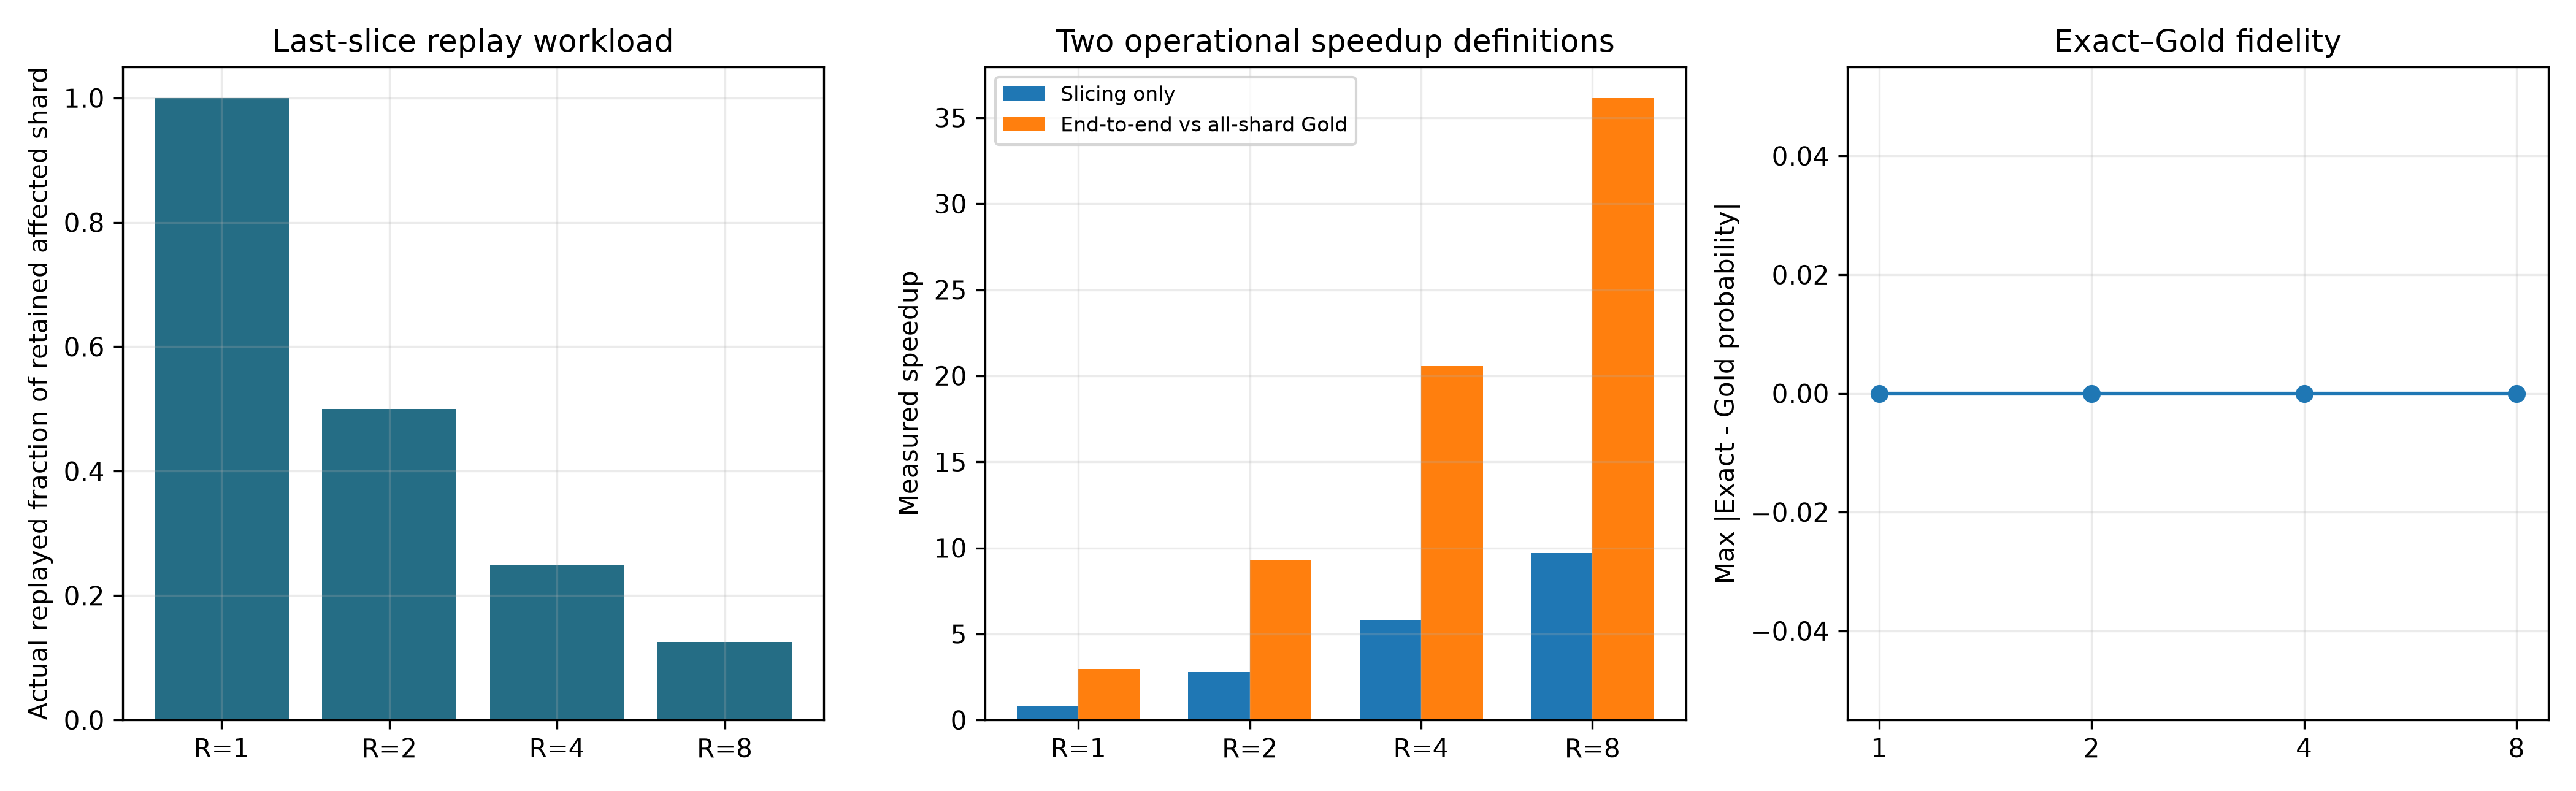

In [97]:
restored_slicing = restored.stage_slicing_corrected()
slicing_supersession = pd.read_csv(RESTORED_OUT / 'results' / 'slicing_original_vs_corrected.csv')
display(restored_slicing)
display(slicing_supersession)
display(Image(filename=RESTORED_OUT / 'figures' / 'slicing_corrected_full_grid.png'))

## R4. Repeated Cross-model Exact–Gold Fidelity

Four deterministic single-record requests per model—one originating from each of the four shards—under the final `S=4` Stratified setup. Exact and Gold use identical preprocessing, seeds, model configurations, assignments, frozen calibration/threshold policy and post-deletion retained-size weights. This is deterministic robustness validation, not statistical proof over all possible deletion requests.

,model,repetition,SK_ID_CURR,deleted_records,affected_shards,affected_shard,aggregation,exact_seconds,gold_seconds,speedup,prediction_mae,prediction_rmse,max_probability_difference,prediction_disagreement,exact_roc_auc,gold_roc_auc,direct_deletion_audit_pass
0,LightGBM,0,451746,1,1,0,post-deletion retained-size weighted probability,2.723193,13.807856,5.070465,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.766353,0.766353,True
1,LightGBM,1,216247,1,1,1,post-deletion retained-size weighted probability,3.664560,13.758632,3.754511,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.765540,0.765540,True
2,LightGBM,2,308163,1,1,2,post-deletion retained-size weighted probability,3.857573,14.358373,3.722126,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.765764,0.765764,True
3,LightGBM,3,214920,1,1,3,post-deletion retained-size weighted probability,10.711706,38.323107,3.577685,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.766047,0.766047,True
4,Logistic Regression,0,451746,1,1,0,post-deletion retained-size weighted probability,3.740718,12.826783,3.428963,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.754484,0.754484,True
5,Logistic Regression,1,216247,1,1,1,post-deletion retained-size weighted probability,3.423386,11.835591,3.457276,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.754485,0.754485,True
6,Logistic Regression,2,308163,1,1,2,post-deletion retained-size weighted probability,3.556748,12.144864,3.414598,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.754488,0.754488,True
7,Logistic Regression,3,214920,1,1,3,post-deletion retained-size weighted probability,6.933641,27.507907,3.967310,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.754469,0.754469,True
8,Random Forest,0,451746,1,1,0,post-deletion retained-size weighted probability,42.130249,166.113449,3.942855,4.060788e-18,2.041301e-17,4.440892e-16,0.0,0.745720,0.745720,True
9,Random Forest,1,216247,1,1,1,post-deletion retained-size weighted probability,41.906951,166.408304,3.970900,3.777133e-18,2.045630e-17,5.551115e-16,0.0,0.745899,0.745899,True


,model,repetitions,max_prediction_mae,max_probability_difference,mean_speedup,min_speedup
0,LightGBM,4,0.000000e+00,0.000000e+00,4.031197,3.577685
1,Logistic Regression,4,0.000000e+00,0.000000e+00,3.567037,3.414598
2,Random Forest,4,4.060788e-18,5.551115e-16,3.840345,3.537979
3,XGBoost,4,0.000000e+00,0.000000e+00,3.864007,3.582108


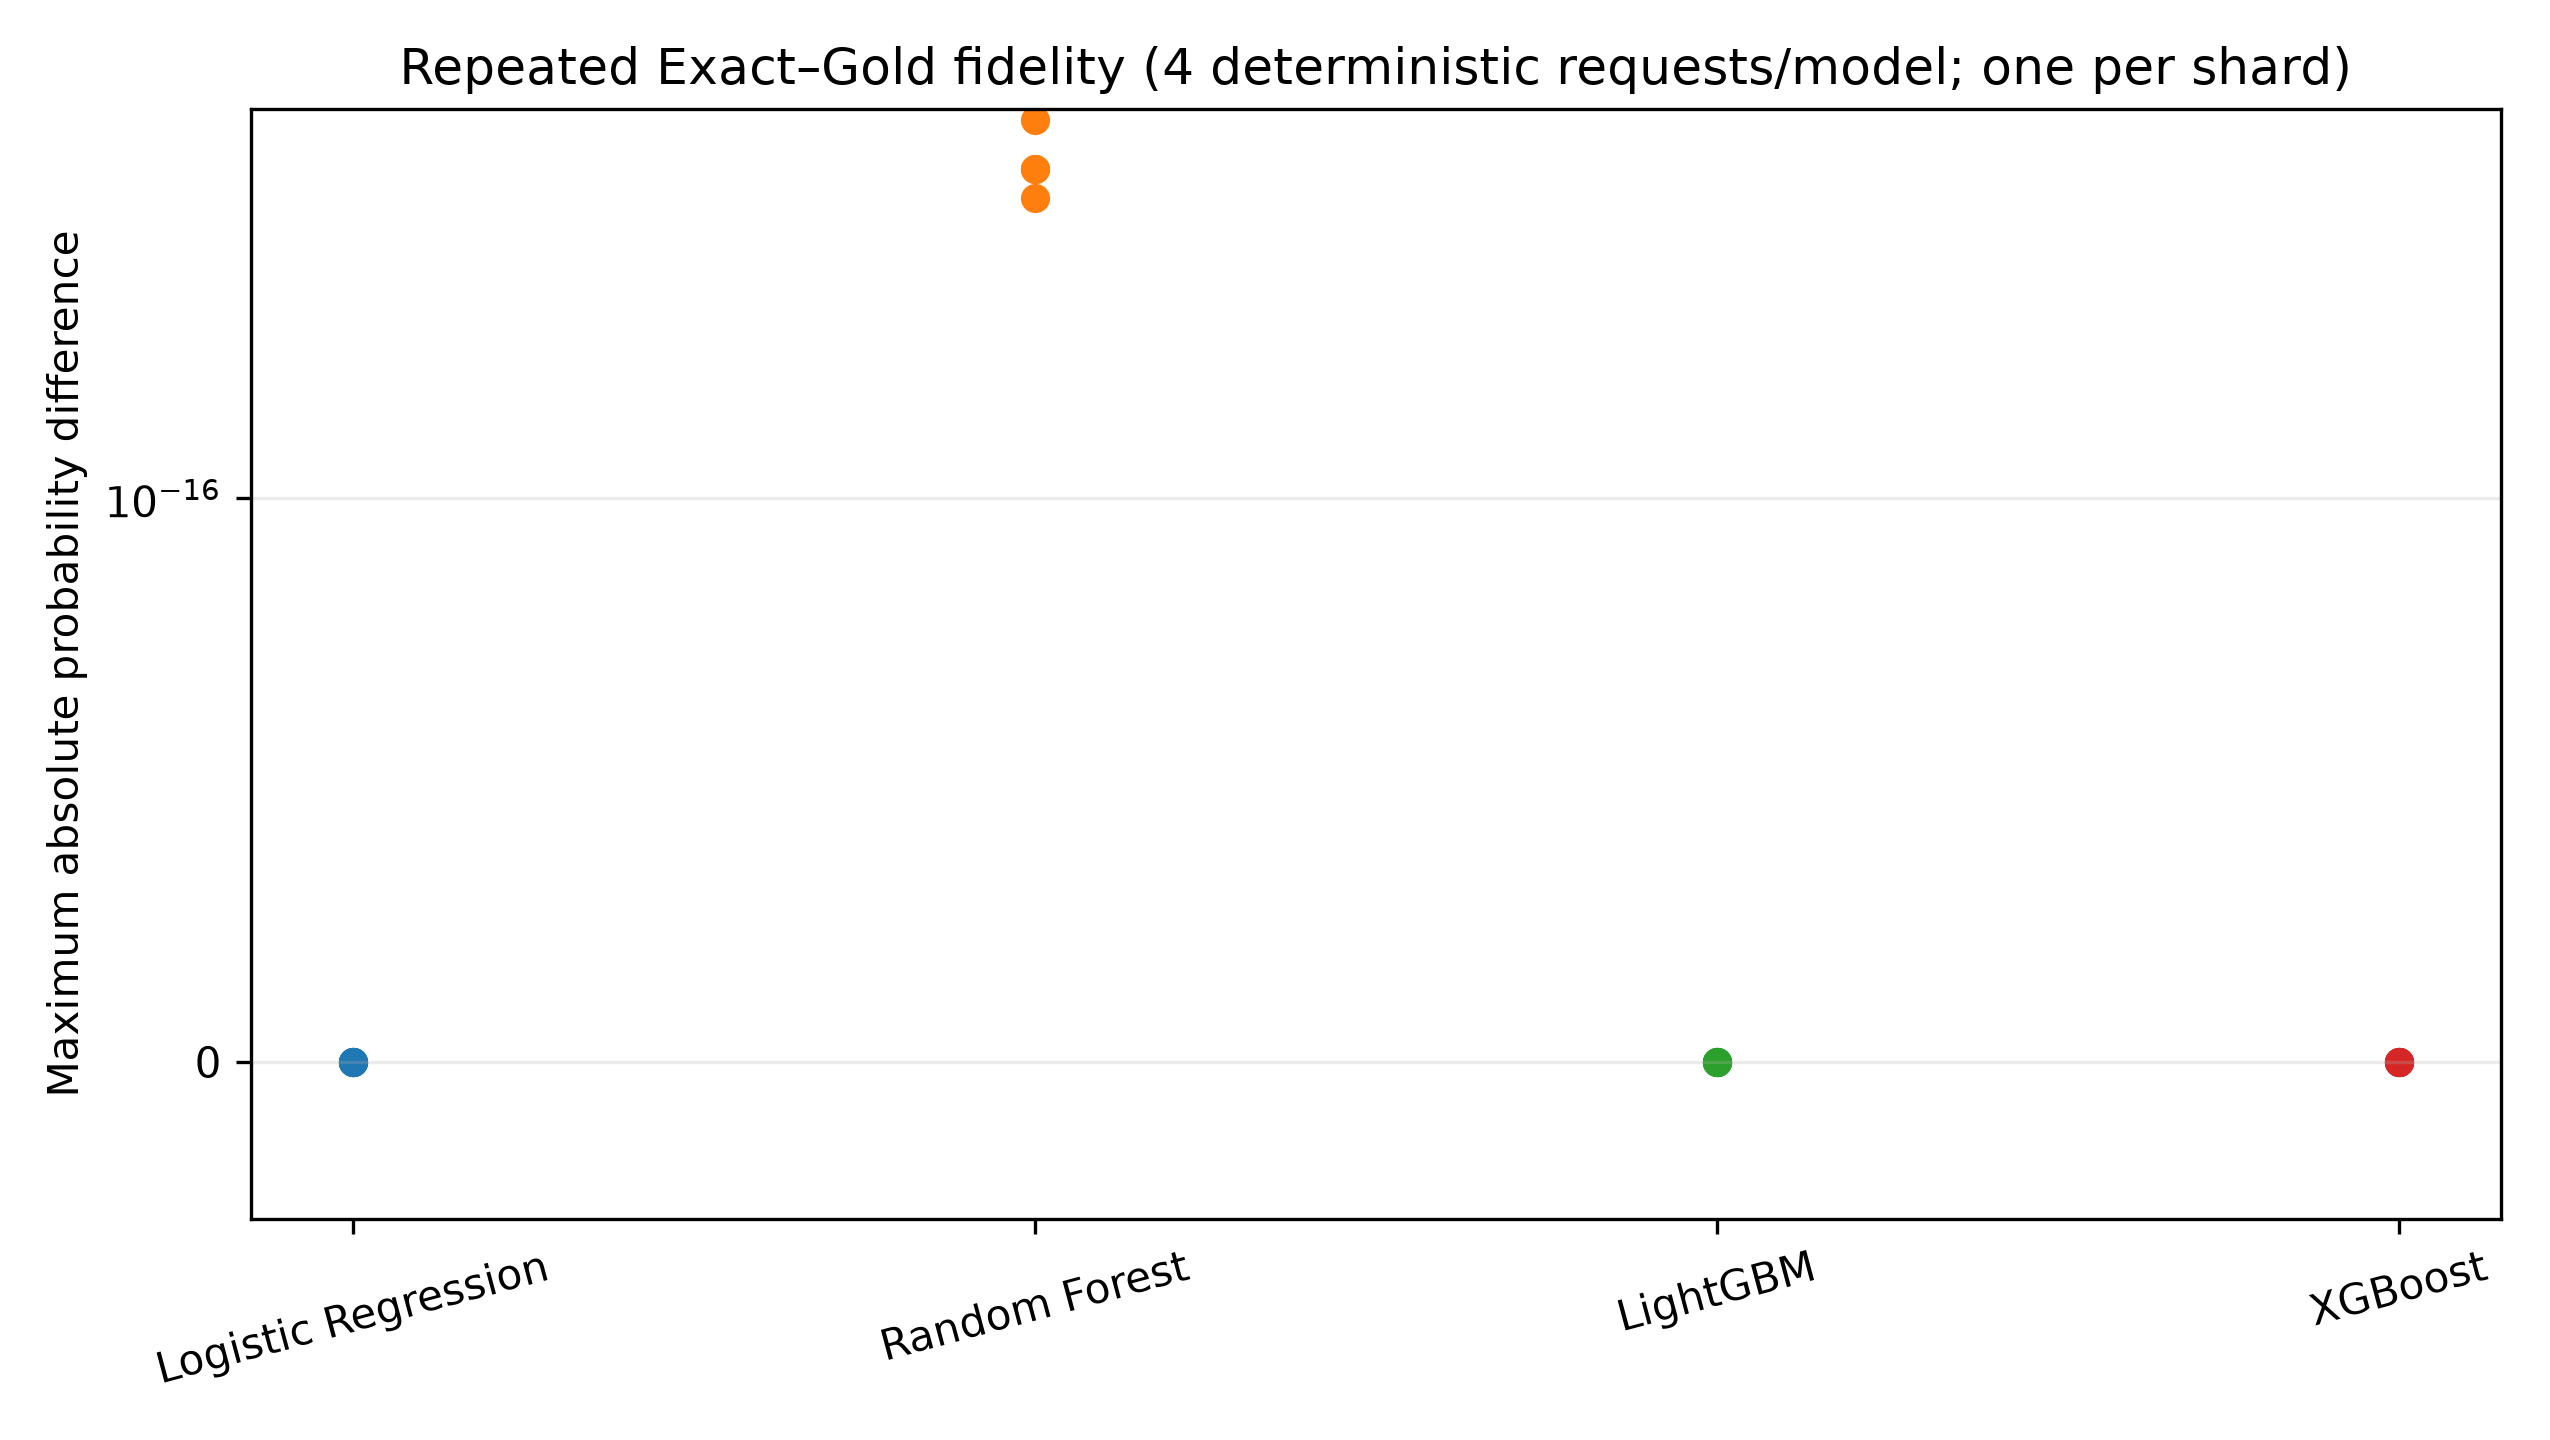

In [98]:
restored_exact = restored.stage_repeated_exact_gold()
restored_exact_summary = pd.read_csv(RESTORED_OUT / 'results' / 'repeated_cross_model_exact_gold_summary.csv')
display(restored_exact)
display(restored_exact_summary)
display(Image(filename=RESTORED_OUT / 'figures' / 'repeated_cross_model_exact_gold.png'))

## R5. Cross-model Learned Aggregation — Practical Architecture Layer

Specialist and Risk-Band at `S=4` across four model families. This practical learned-aggregation layer is reported separately from the controlled assignment-only comparison. Calibration is split deterministically into meta-fit and held-out Platt subsets; threshold selection remains Validation-only. Risk-Band uses the same shared 3-fold train-only OOF LightGBM-derived assignment across all model families.

,model,strategy,roc_auc,average_precision,ks,brier,meta_fit_rows,platt_fit_rows
0,LightGBM,risk_band,0.753196,0.251738,0.385148,0.067553,15376,15376
1,LightGBM,specialist,0.765853,0.256136,0.401891,0.067367,15376,15376
2,Logistic Regression,risk_band,0.754024,0.236010,0.384198,0.068073,15376,15376
3,Logistic Regression,specialist,0.755239,0.235010,0.379213,0.068161,15376,15376
4,Random Forest,risk_band,0.716655,0.224475,0.327803,0.068987,15376,15376
5,Random Forest,specialist,0.746584,0.219756,0.373472,0.068899,15376,15376
6,XGBoost,risk_band,0.764826,0.257492,0.402582,0.067870,15376,15376
7,XGBoost,specialist,0.767485,0.260246,0.404129,0.067751,15376,15376


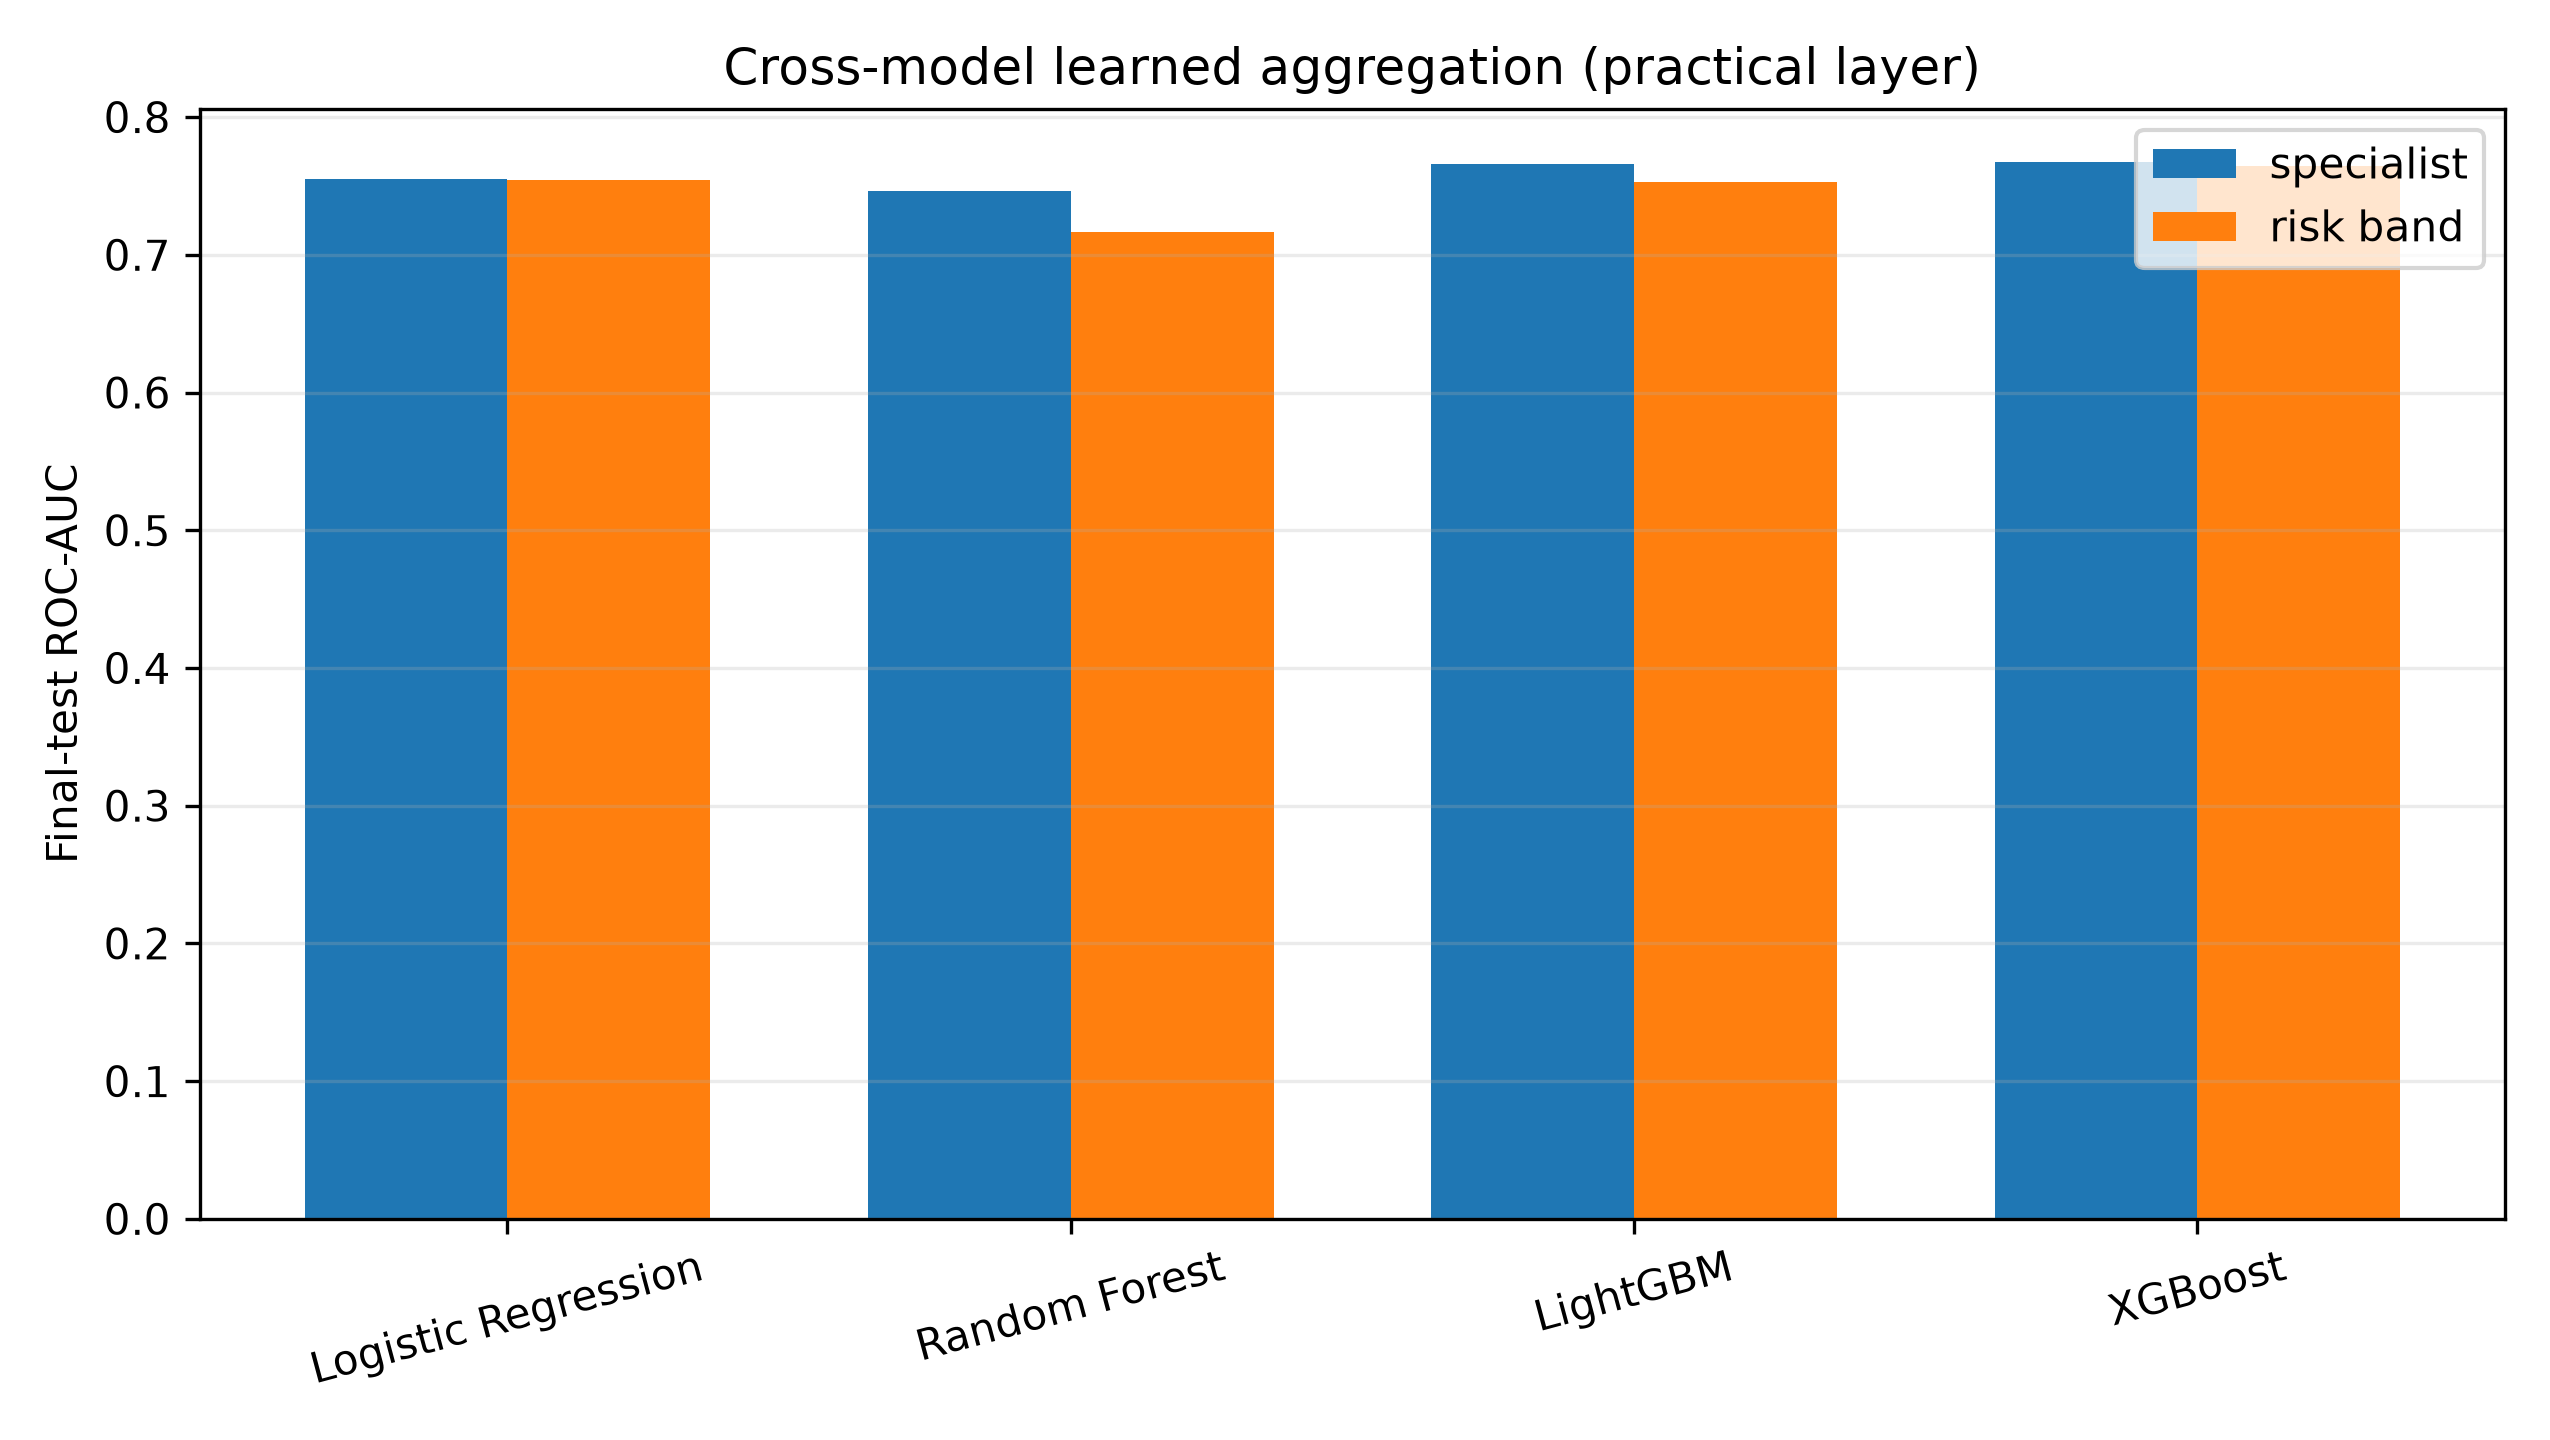

In [99]:
restored_learned = restored.stage_cross_model_learned_aggregation()
display(restored_learned[['model','strategy','roc_auc','average_precision','ks','brier','meta_fit_rows','platt_fit_rows']])
display(Image(filename=RESTORED_OUT / 'figures' / 'cross_model_learned_aggregation.png'))

## R6. Supplementary 30-round Cumulative Deletion Stress Test

LightGBM, `S=4`, four records per request, 30 rounds for Localized Repeated, Rotating Localized and Diffuse Repeated streams. Exact affected-shard retraining and protocol-compatible Gold are directly timed at every round 0–30; formal fidelity checkpoints remain rounds 0, 1, 5, 10, 20 and 30. Exact runtime is the sum of checkpoint-returned `fit_seconds`, so resume time cannot be mistaken for training time.

Repeated requests do not automatically make SISA more beneficial. Computational savings accumulate when requests preserve deletion locality and unaffected shard models can be reused; diffuse requests reduce this advantage.

[2026-09-30 09:57:00] Validated patched cumulative stress checkpoint


,stream,rounds,final_deleted,min_auc,max_auc,cumulative_exact_seconds,cumulative_gold_seconds,cumulative_measured_speedup,all_membership_audits_pass
0,diffuse_repeated,30,120,0.765188,0.766767,386.032497,385.290271,0.998077,True
1,localized_repeated,30,120,0.765687,0.766418,108.160116,391.480456,3.619453,True
2,rotating_localized,30,120,0.765566,0.766786,108.329244,431.390005,3.982212,True


,model,stream,round,cumulative_deleted_records,gold_seconds,cumulative_gold_seconds,round_exact_seconds,cumulative_exact_seconds,cumulative_measured_speedup,gold_timing_source,exact_gold_prediction_mae,exact_gold_max_probability_difference,exact_gold_prediction_disagreement,gold_roc_auc,formal_fidelity_checkpoint,direct_deletion_audit_pass
0,LightGBM,diffuse_repeated,0,0,0.000000,0.000000,0.000000,0.000000,1.000000,round-0 baseline; no retraining,0.0,0.0,0.0,0.765968,True,True
1,LightGBM,diffuse_repeated,1,4,14.665985,14.665985,13.586959,13.586959,1.079416,independent protocol-compatible Gold checkpoints,0.0,0.0,0.0,0.765543,True,True
2,LightGBM,diffuse_repeated,2,8,13.548929,28.214914,13.548929,27.135887,1.039764,direct measured compatible per-shard checkpoints,0.0,0.0,0.0,0.765948,False,True
3,LightGBM,diffuse_repeated,3,12,12.207590,40.422504,12.207590,39.343478,1.027426,direct measured compatible per-shard checkpoints,0.0,0.0,0.0,0.765838,False,True
4,LightGBM,diffuse_repeated,4,16,14.611062,55.033565,14.611062,53.954539,1.019999,direct measured compatible per-shard checkpoints,0.0,0.0,0.0,0.766305,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
88,LightGBM,rotating_localized,26,104,15.059927,373.045138,3.599962,94.196682,3.960279,direct measured compatible per-shard checkpoints,0.0,0.0,0.0,0.766786,False,True
89,LightGBM,rotating_localized,27,108,14.696054,387.741192,3.587672,97.784355,3.965268,direct measured compatible per-shard checkpoints,0.0,0.0,0.0,0.766520,False,True
90,LightGBM,rotating_localized,28,112,14.718175,402.459367,3.787346,101.571700,3.962318,direct measured compatible per-shard checkpoints,0.0,0.0,0.0,0.766042,False,True
91,LightGBM,rotating_localized,29,116,14.005668,416.465036,3.030688,104.602388,3.981410,direct measured compatible per-shard checkpoints,0.0,0.0,0.0,0.765950,False,True


,model,stream,round,cumulative_deleted_records,gold_seconds,cumulative_gold_seconds,round_exact_seconds,cumulative_exact_seconds,cumulative_measured_speedup,gold_timing_source,exact_gold_prediction_mae,exact_gold_max_probability_difference,exact_gold_prediction_disagreement,gold_roc_auc,formal_fidelity_checkpoint,direct_deletion_audit_pass
0,LightGBM,diffuse_repeated,0,0,0.000000,0.000000,0.000000,0.000000,1.000000,round-0 baseline; no retraining,0.0,0.0,0.0,0.765968,True,True
1,LightGBM,diffuse_repeated,1,4,14.665985,14.665985,13.586959,13.586959,1.079416,independent protocol-compatible Gold checkpoints,0.0,0.0,0.0,0.765543,True,True
2,LightGBM,diffuse_repeated,5,20,14.953947,69.987512,16.313782,70.268321,0.996004,independent protocol-compatible Gold checkpoints,0.0,0.0,0.0,0.765998,True,True
3,LightGBM,diffuse_repeated,10,40,14.185237,137.868526,12.746902,136.710999,1.008467,independent protocol-compatible Gold checkpoints,0.0,0.0,0.0,0.766033,True,True
4,LightGBM,diffuse_repeated,20,80,11.840705,269.864983,14.070602,270.937352,0.996042,independent protocol-compatible Gold checkpoints,0.0,0.0,0.0,0.765566,True,True
5,LightGBM,diffuse_repeated,30,120,11.593096,385.290271,11.262953,386.032497,0.998077,independent protocol-compatible Gold checkpoints,0.0,0.0,0.0,0.765679,True,True
6,LightGBM,localized_repeated,0,0,0.000000,0.000000,0.000000,0.000000,1.000000,round-0 baseline; no retraining,0.0,0.0,0.0,0.765968,True,True
7,LightGBM,localized_repeated,1,4,13.653468,13.653468,3.364008,3.364008,4.058691,independent protocol-compatible Gold checkpoints,0.0,0.0,0.0,0.765996,True,True
8,LightGBM,localized_repeated,5,20,13.540048,65.940959,2.936232,17.403898,3.788862,independent protocol-compatible Gold checkpoints,0.0,0.0,0.0,0.766064,True,True
9,LightGBM,localized_repeated,10,40,13.676602,131.470766,2.925930,35.324655,3.721785,independent protocol-compatible Gold checkpoints,0.0,0.0,0.0,0.766384,True,True


,stream,previous_outer_timer_cumulative_exact_seconds,corrected_checkpoint_fit_seconds_cumulative_exact_seconds,runtime_delta_seconds,corrected_to_previous_runtime_ratio,max_absolute_exact_roc_auc_change,utility_changed_materially,fidelity_changed_materially
0,localized_repeated,108.662129,108.160116,-0.502013,0.995380,0.0,False,False
1,rotating_localized,110.849007,108.329244,-2.519763,0.977269,0.0,False,False
2,diffuse_repeated,395.188357,386.032497,-9.155860,0.976832,0.0,False,False


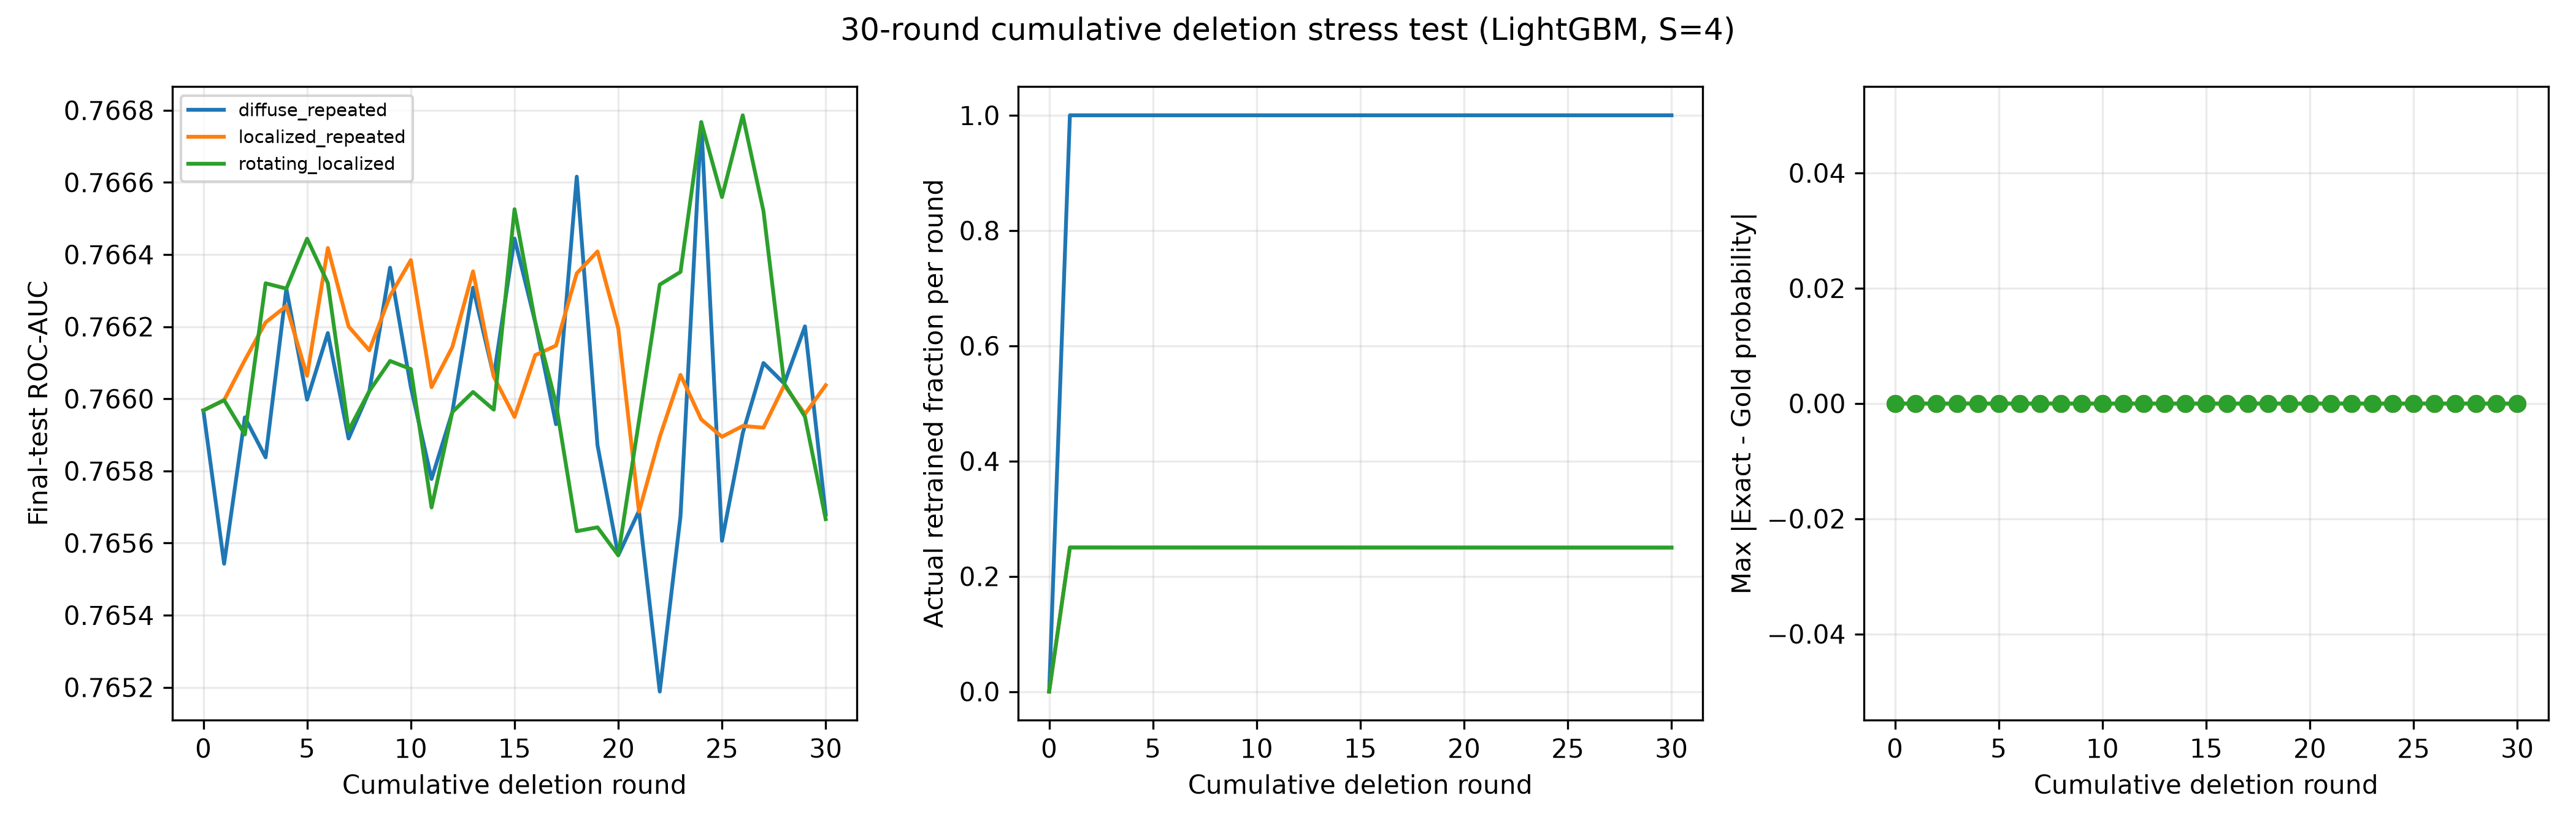

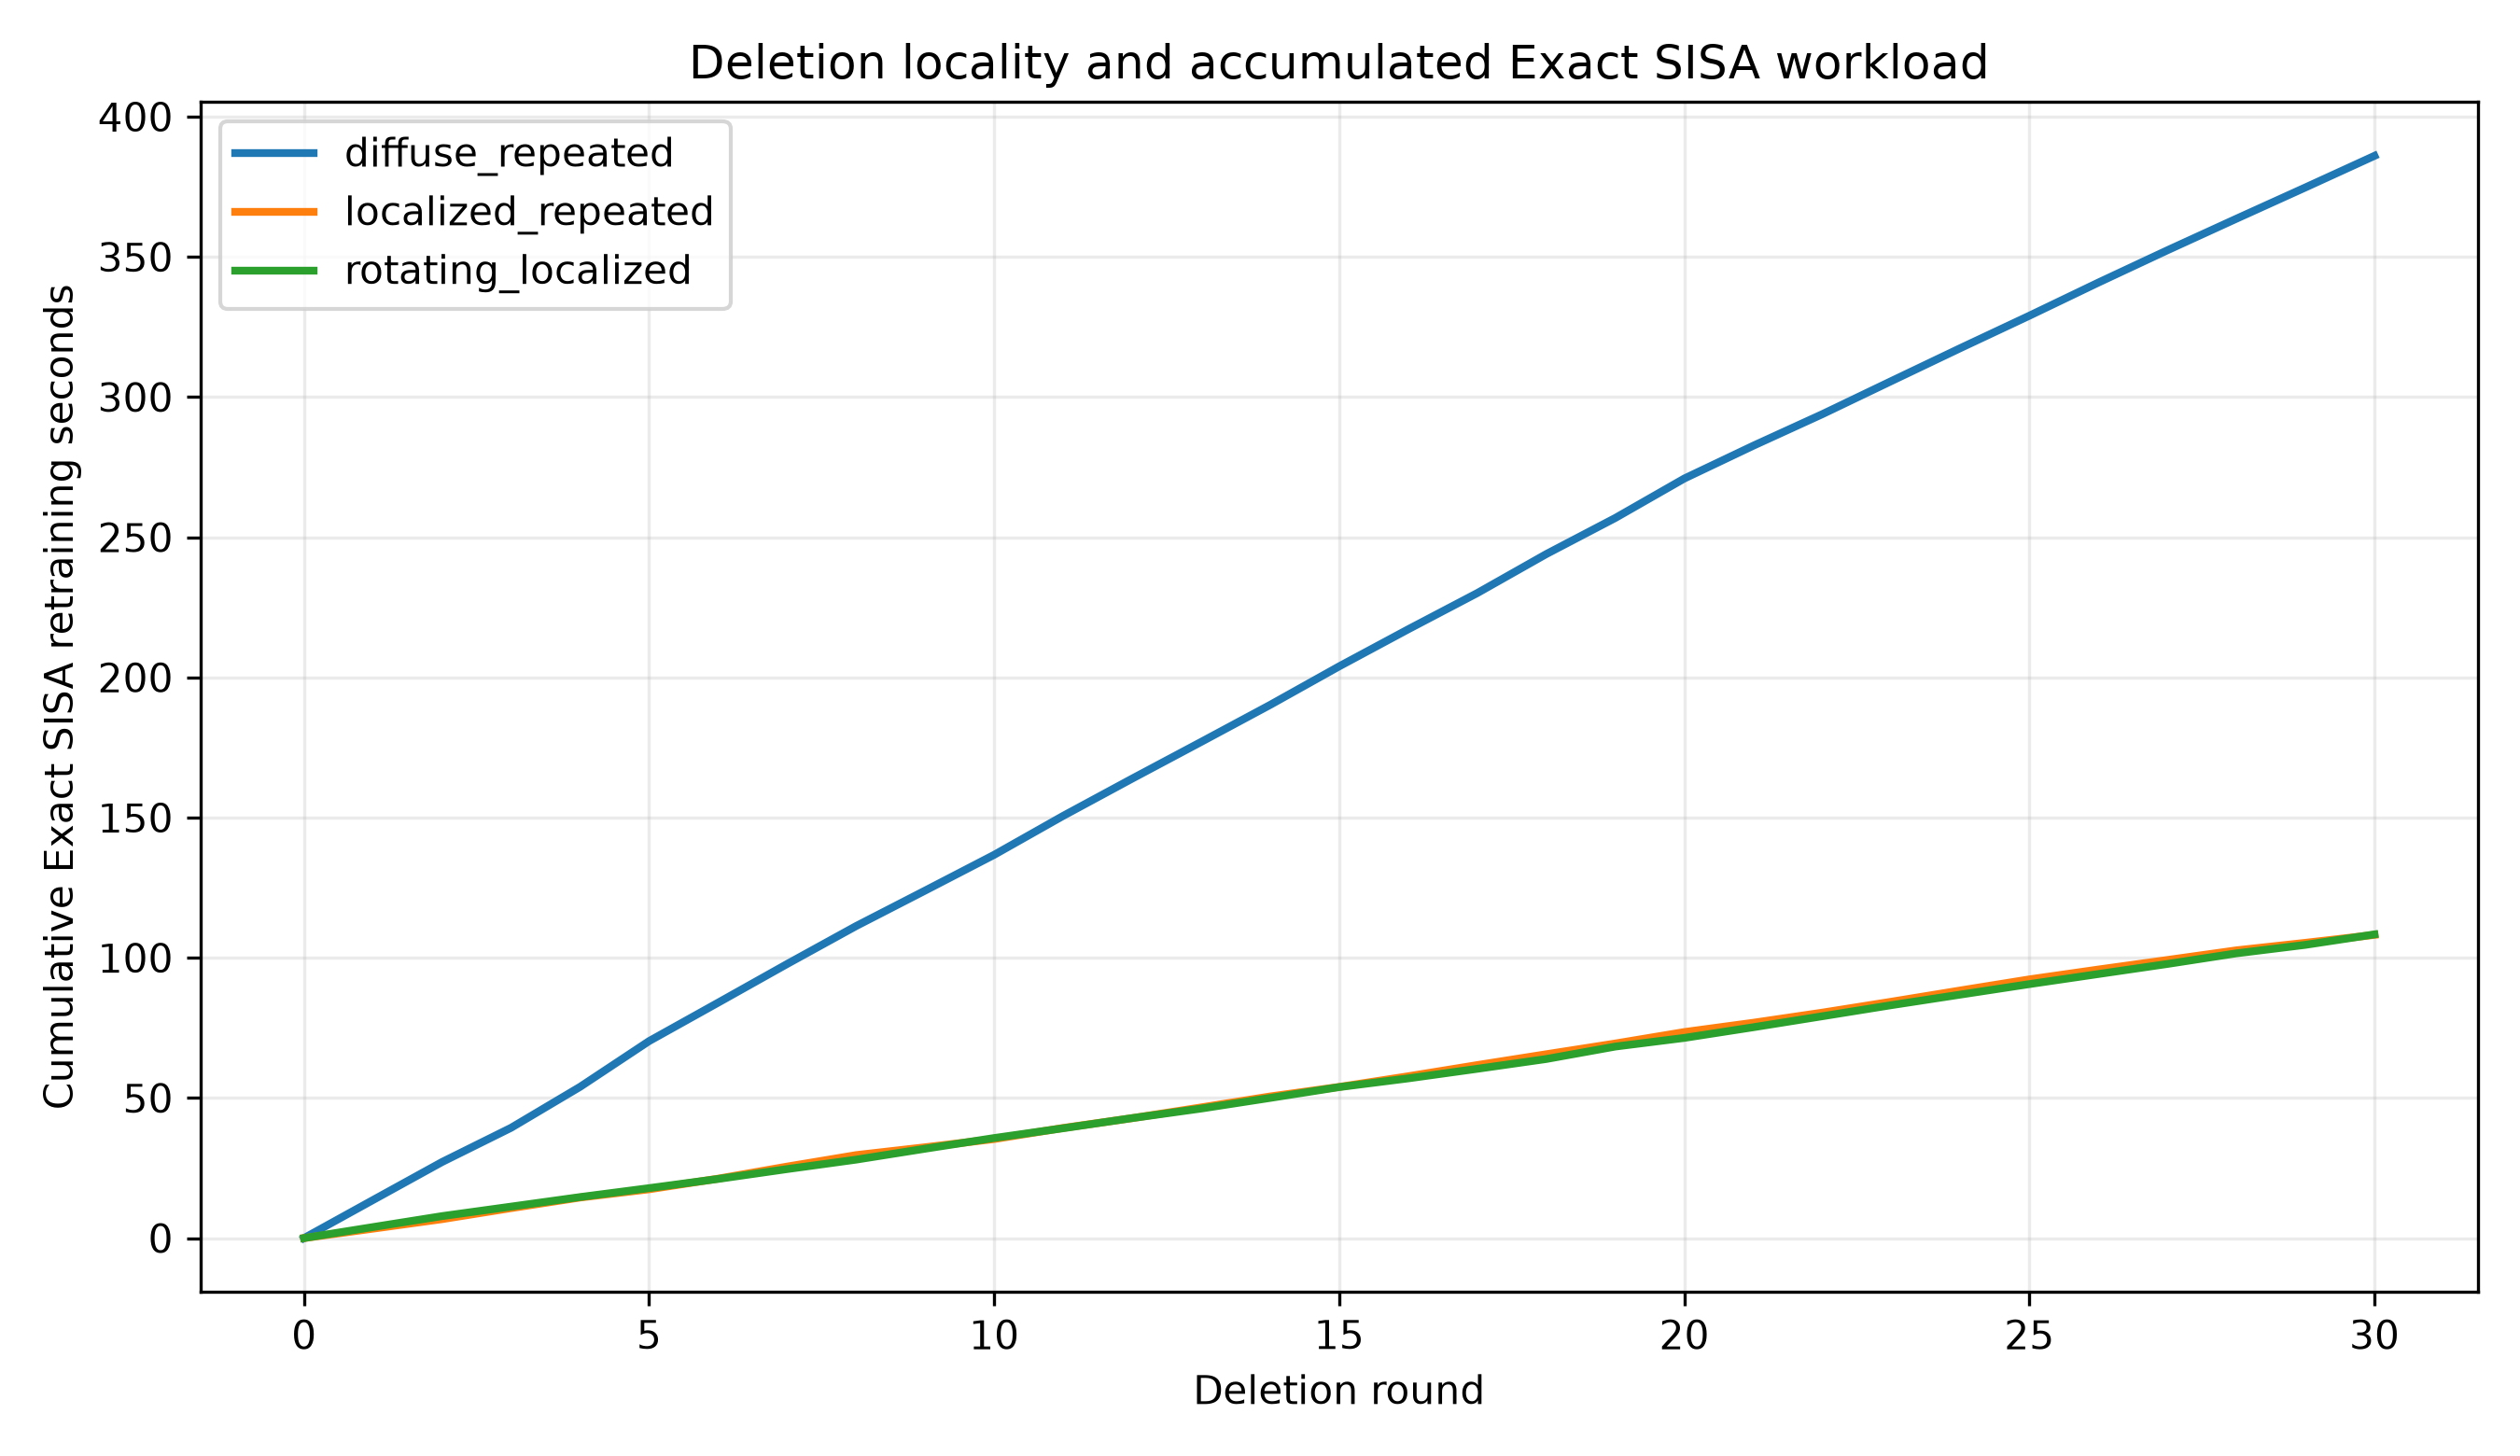

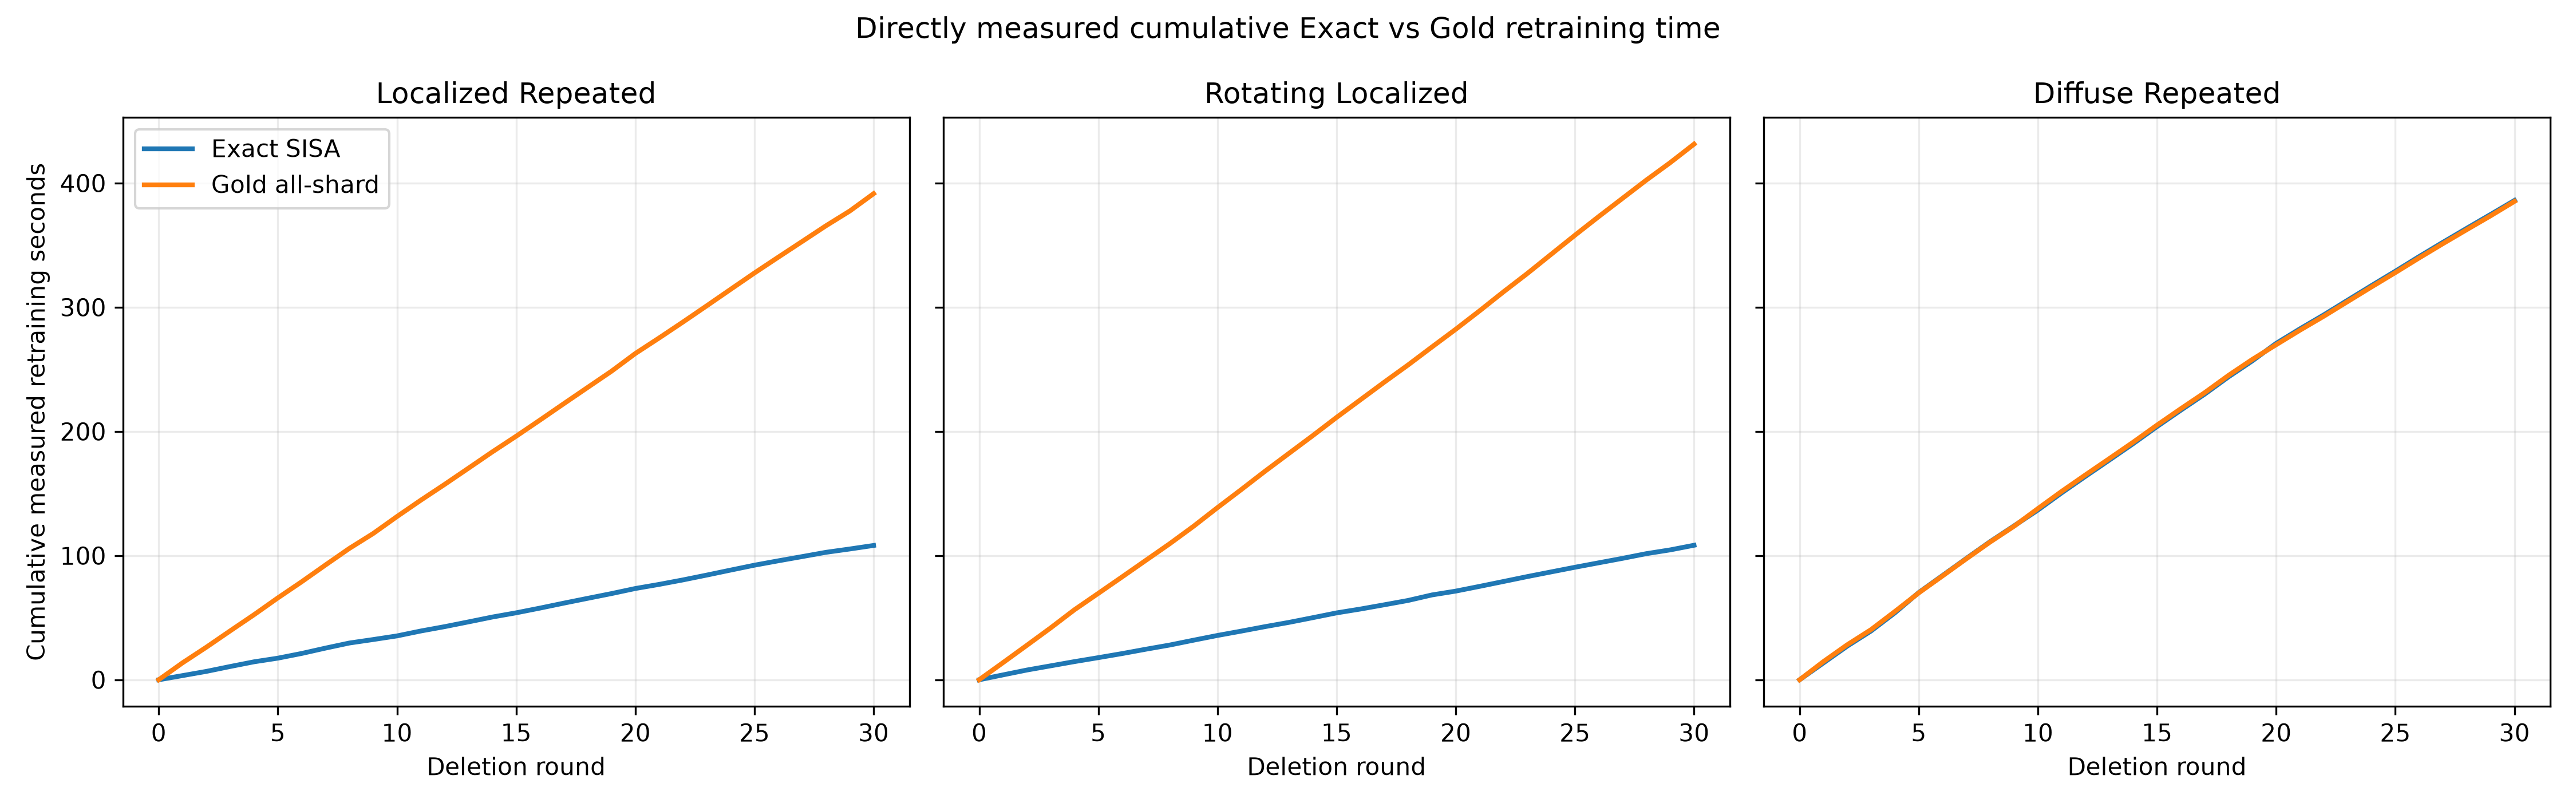

In [100]:
restored_stress = restored.stage_cumulative_deletion_stress()
restored_stress_gold_all = pd.read_csv(RESTORED_OUT / 'results' / 'cumulative_deletion_stress_gold_all_rounds.csv')
restored_stress_gold = pd.read_csv(RESTORED_OUT / 'results' / 'cumulative_deletion_stress_gold_checkpoints.csv')
display(restored_stress.groupby('stream').agg(
    rounds=('round','max'), final_deleted=('cumulative_deleted_records','max'),
    min_auc=('exact_roc_auc','min'), max_auc=('exact_roc_auc','max'),
    cumulative_exact_seconds=('cumulative_exact_seconds','last'),
    cumulative_gold_seconds=('cumulative_gold_seconds','last'),
    cumulative_measured_speedup=('cumulative_measured_speedup','last'),
    all_membership_audits_pass=('direct_deletion_audit_pass','all')).reset_index())
display(restored_stress_gold_all)
display(restored_stress_gold)
display(pd.read_csv(RESTORED_OUT / 'results' / 'cumulative_stress_runtime_correction.csv'))
display(Image(filename=RESTORED_OUT / 'figures' / 'cumulative_deletion_stress.png'))
display(Image(filename=RESTORED_OUT / 'figures' / 'cumulative_deletion_stress_runtime.png'))
display(Image(filename=RESTORED_OUT / 'figures' / 'cumulative_deletion_stress_exact_vs_gold.png'))

## R7. Full Restoration Verification

Candidate status requires complete grids, clean execution, immutable-source hashes, compatible reused artifacts, disjoint data roles, no Test-based optimization, direct deletion audits and Exact–Gold fidelity checks.

In [101]:
restoration_verification = restored.verify_restoration()
display(pd.DataFrame([restoration_verification]))
display(pd.read_csv(RESTORED_OUT / 'results' / 'leakage_config_consistency_checks.csv'))
display(pd.read_csv(RESTORED_OUT / 'results' / 'complete_experimental_scope_matrix.csv'))
print('Failed/skipped configurations:', len(pd.read_csv(RESTORED_OUT / 'results' / 'failed_skipped_configurations.csv')))

[2026-09-30 09:57:04] Full restoration verification passed; notebook execution audit remains


,verified_at,all_checks_passed,checks,failed_or_skipped_configurations,result_tables,artifacts_in_inventory,source_immutability_passed,candidate_source_of_truth_pending_notebook_execution_audit
0,2026-09-30T09:57:04,True,26,0,19,1471,True,True


,category,check,passed,evidence
0,provenance,immutable final/legacy notebooks and outputs_f...,True,source_immutability_audit.csv
1,scope,complete cross-model shard grid,True,"observed=28, expected=28"
2,scope,complete controlled strategy grid,True,"observed=20, expected=20"
3,scope,complete corrected slicing grid,True,"observed=[1, 2, 4, 8]"
4,protocol,corrected R=1/4 non-material gate,True,slicing_original_vs_corrected.csv
5,protocol,slicing replay rows exclude deleted membership,True,actual replay rows = pre-deletion span - 1; de...
6,protocol,slicing speedups are separated,True,affected-shard/replay and all-shard-Gold/repla...
7,protocol,slicing favorable last-slice design disclosed,True,each R deliberately deletes a record from its ...
8,scope,complete repeated exact grid,True,"observed=16, expected=16"
9,scope,repeated exact covers every shard per model,True,"four deterministic requests per model, one ori..."


,experimental_component,authoritative_artifact_root,status,verification_note
0,Identity-safe data pipeline and isolated splits,outputs_final retained,A,unchanged validated foundation
1,Four-family baseline and SISA S=4,outputs_final retained,A,unchanged validated foundation
2,Cross-model shard-count S=2..128,outputs_restored,A-restored,28/28 configurations complete
3,Positive-sample scarcity diagnostic,outputs_restored,A-restored,derived for every model x S row
4,Controlled model x sharding strategy,outputs_restored,A-restored,20/20 configurations complete
5,Learned aggregation Specialist/Risk-Band,outputs_restored,A-restored,8/8 practical configurations complete
6,Deletion locality scale/pattern,outputs_final retained,A,unchanged validated foundation
7,Incremental slicing R=1/2/4/8,outputs_restored,A-restored,corrected post-deletion weights; old R=1/4 sup...
8,Repeated cross-model Exact–Gold,outputs_restored,A-restored,16/16 model-request cases complete; one reques...
9,Approximate continued boosting,outputs_final retained,A,unchanged validated foundation


Failed/skipped configurations: 0
